# Meta-labeling pe mai multe strategii primare și mai multe tipuri de bare

**`btcusdt_v2`** · Binance USDⓈ-M BTCUSDT perpetual · 17 strategii primare și un control × 9 seturi de bare · test forward februarie–octombrie 2026 · `EXPLORATORY`

## Rezumat

**Întrebarea.** Există în aceste date informație pe care un model secundar o poate folosi pentru a filtra strategii primare? Cu ce features, depinde de `edge`-ul primarei, de numărul de semnale sau de tipul de bare?

**Răspunsul scurt.** Există informație, dar nu de tipul care face bani. Modelul secundar prezice destul de bine **dacă piața se va mișca** și aproape deloc **în ce parte**. De aceea crește rata de câștig fără să crească profitul. Niciun filtru nu face vreo strategie profitabilă la 10 bps cost, iar câștigul economic nu se distinge de un filtru aleator de aceeași mărime.

| Întrebare | Răspuns | Dovada principală |
|---|---|---|
| Există informație? | Da pentru rata de câștig, slabă. Nu pentru profit | AUC mediu 0.521. 4 din 17 reguli trec testul față de 0.5, **niciuna** nu trece testul față de intrări aleatoare (0.524) |
| Log loss? | Aproape nicio îmbunătățire | Doar `DON6H` bate clar predicția constantă, cu 0.0046 nats. 75 din 161 de celule au skill pozitiv |
| Îmbunătățește strategia? | Reduce pierderile, nu selectează mai bine | 8 din 161 de celule bat filtrul aleator, exact cât dă șansa la pragul de 5%. Percentila medie e 55 |
| Ce fel de informație? | Volatilitate, nu direcție | Același model: AUC 0.69 pentru "atinge o barieră", 0.498 pentru "care barieră" |
| Cu ce features? | `VOL`, `CALENDAR`, `BOOK_FLOW` | Mult redundante: 0 din 198 de combinații au valoare unică semnificativă. `BOOK_STATE` și `FLOW` aproape nimic |
| Features diferite pe strategii? | În test da, dar nu se păstrează | Corelația importanțelor train-test e 0.09, cu semn identic în 53% din cazuri, adică monedă aruncată |
| Depinde de `edge`? | Nu se vede, iar testul are putere mică | `Edge`-urile din test sunt aproape toate nedistingibile de zero. Oglinda păstrează AUC-ul (corelație 0.70) |
| Depinde de N? | Limitează ce se poate vedea, nu explică tiparul | Sub 300 de evenimente efective pipeline-ul recuperează doar 55% din un semnal real, deci 6 reguli rămân `UNDERPOWERED`. AUC-ul real nu crește cu N între strategii |
| Depinde de bare? | Foarte puțin ca AUC, mult ca număr de semnale | Efectele sunt sub 0.01 AUC și nesemnificative (p = 0.09). La regulile de microstructură, numărul de evenimente variază de până la 54 de ori |

**Trei lucruri care ar fi fost concluzii greșite fără controale.**

1. **AUC peste 0.5 nu înseamnă `edge`.** Intrările aleatoare au și ele AUC 0.524. Cu o etichetă netă, volatilitatea mare micșorează costul față de barieră și scurtează timpul până la o ieșire. Asta ridică mecanic rata de câștig.
2. **Stabilitatea feature-urilor era un artefact.** Pe `net / lățime`, importanțele păreau stabile (corelație 0.47), fiindcă rezultatul conține `−cost / lățime`. Pe brut, corelația cade la 0.09.
3. **Îmbunătățirea de Sharpe e reducere de expunere.** Sharpe crește pe aproape toate regulile doar pentru că se tranzacționează mai puțin dintr-o strategie care pierde.

**Cele două candidate pentru o confirmare viitoare.** `TSCAN` are cel mai bun `edge` brut (+3.8 bps, interval −2.9 la +9.7), iar la 4 bps cost filtrul lui ajunge la +3.9 bps. `LIQREV` are cel mai mare AUC (0.575) și singurul indiciu de direcție, dar are și unul din cele mai mici N. Niciuna nu e dovedită.

**Limite.** Tot studiul e `EXPLORATORY`: toate lunile au mai fost analizate, iar holdout-ul iunie–octombrie 2026 era deja folosit. Rezultatul e despre aceste 17 reguli, cu `edge` aproape de zero. Nu arată ce ar face un model secundar pe o primară cu `edge` real.

**Cum se citește.** Secțiunile 1–9 sunt designul și codul. Rezultatele încep la secțiunea 10, iar concluziile sunt în secțiunea 17. Celulele marcate `POST-HOC` au fost adăugate după ce am văzut rezultatele, ca verificări.

## 1. Setup și reproductibilitate

**Mediu.** Rulează cu env-ul conda `disertatie`. Calculul greu merge în procese `fork` (nu în thread-uri), cu `num_threads=1` în LightGBM: pilotul a arătat că apelurile concurente din thread-uri dau segfault în `lib_lightgbm`.

**Ce atinge.** Citește doar `derived/datasets/btcusdt_v2` și `derived/canonical/trades`. Ultima celulă verifică faptul că sursele nu s-au schimbat.

**Durată.** O rulare completă durează aproximativ 20 de minute cu 14 procese. Procesul principal ajunge la 3.2 GB. O a doua rulare de la zero a dat aceleași numere, cu excepția timpilor afișați.

**Variabile de mediu.** `META_DRY_RUN=1` mută testul pe luni din perioada de dezvoltare și reduce grila, pentru depanare fără a atinge lunile de test. `META_CACHE=<dir>` păstrează rezultatele etapelor grele, ca analiza să poată fi reluată fără recalcul. `META_WORKERS` setează numărul de procese.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMBA_NUM_THREADS"):
    os.environ[_v] = "1"          # one thread per process: parallelism comes from the process pool only
import hashlib, json, multiprocessing as mp, pickle, platform, resource, sys, time, warnings
from concurrent.futures import ProcessPoolExecutor, as_completed
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
import lightgbm as lgb
import numba
import scipy
import sklearn
import statsmodels
import statsmodels.api as sm
from numba import njit
from scipy import stats
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform
from scipy.special import expit, logit
from sklearn.linear_model import LogisticRegression
from statsmodels.stats.multitest import multipletests

T0 = time.time()
SEED = 20261107
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

def find_repo_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data/cryptohftdata/derived/datasets/btcusdt_v2/manifest.json").exists():
            return p
    raise FileNotFoundError("Run this notebook from inside the QuantForge repository.")

ROOT = find_repo_root()
CHDDS = ROOT / "data/cryptohftdata"
DATA = CHDDS / "derived/datasets/btcusdt_v2"
TRADES = CHDDS / "derived/canonical/trades"
sys.path.insert(0, str(CHDDS))
from chdds.dataset import incident_rows

man = json.loads((DATA / "manifest.json").read_text())
DRY_RUN = os.environ.get("META_DRY_RUN") == "1"
CACHE = os.environ.get("META_CACHE")
WORKERS = int(os.environ.get("META_WORKERS", "12"))

def source_fingerprint():
    files = sorted(DATA.rglob("*.parquet")) + [DATA / "manifest.json"] + sorted(TRADES.glob("*.parquet"))
    return (len(files), sum(f.stat().st_size for f in files), max(f.stat().st_mtime_ns for f in files))
FINGERPRINT_START = source_fingerprint()

def cached(name, fn):
    # Optional stage cache. Without META_CACHE every stage is recomputed.
    if CACHE:
        p = Path(CACHE) / f"{name}{'_dry' if DRY_RUN else ''}.pkl"
        if p.exists():
            return pickle.loads(p.read_bytes())
    out = fn()
    if CACHE:
        Path(CACHE).mkdir(parents=True, exist_ok=True)
        p.write_bytes(pickle.dumps(out, protocol=5))
    return out

def pmap(fn, items, workers=None, key=None):
    # Fork pool: workers inherit the read-only globals, so no data is pickled in. Results keep input order.
    # ProcessPoolExecutor raises BrokenProcessPool on a worker crash, where multiprocessing.Pool would hang.
    items = list(items)
    order = sorted(range(len(items)), key=(lambda i: -key(items[i])) if key else (lambda i: i))
    out = [None] * len(items)
    with ProcessPoolExecutor(workers or WORKERS, mp_context=mp.get_context("fork")) as ex:
        futs = {ex.submit(fn, items[i]): i for i in order}
        for f in as_completed(futs):
            out[futs[f]] = f.result()
    return out

C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", red="#e34948", purple="#7a5bd0", gold="#c99a1e")
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list("seq", ["#f0efec", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])     # red < 0 < blue
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10, "font.family": "sans-serif",
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "lines.linewidth": 1.8, "legend.frameon": False, "legend.fontsize": 9,
})
pd.set_option("display.width", 220, "display.max_columns", 60, "display.max_rows", 300, "display.max_colwidth", 90)
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | lightgbm {lgb.__version__} | scikit-learn {sklearn.__version__} | statsmodels {statsmodels.__version__}")
print(f"Dataset: {DATA.name} | created {man['created_utc']} | book mode {man['book_provenance']['book_mode']} | workers {WORKERS} | dry run {DRY_RUN}")

Python 3.11.13 | pandas 2.3.3 | numpy 2.0.2 | lightgbm 4.6.0 | scikit-learn 1.7.2 | statsmodels 0.14.5
Dataset: btcusdt_v2 | created 2026-11-05T20:01:10Z | book mode rebuilt | workers 14 | dry run False


## 2. Designul, fixat înainte de orice rezultat de test

Tot ce e în această secțiune a fost scris înainte să fie calculat vreun rezultat din lunile de test. Singurele rezultate văzute înainte sunt cele ale strategiilor primare pe perioada de dezvoltare (secțiunea 2.2).

### 2.1 Întrebările

| # | Întrebare | Unde e răspunsul |
|---|---|---|
| Q1 | Există informație pentru meta-labeling în aceste date? | Secțiunile 10–11 |
| Q2 | Cu ce features? | Secțiunea 12 |
| Q3 | Există features mai bune pe anumite strategii, și de ce? | Secțiunile 12–13 |
| Q4 | Funcționează modelul secundar diferit în funcție de `edge`-ul primarei? | Secțiunea 14 |
| Q5 | Rezultatul e explicat de numărul de semnale și nu de `edge`? | Secțiunea 14 |
| Q6 | Cum schimbă barele modelul secundar? | Secțiunea 15 |

### 2.2 Strategiile primare și cum au fost alese

Am testat aproximativ 80 de variante de reguli pe `time_1m`, **doar pe rezultate dinainte de 2026-02-01**. Niciuna nu a trecut clar de costuri: `edge`-ul brut a fost între −15 și +6 bps pe tranzacție, cu 12 bps pe un eșantion de 71 de tranzacții. Din acestea am păstrat 17 reguli și un control, urmărind trei lucruri:

* **Familii economice diferite**: trend, reversie, flux, microstructură, derivate.
* **Frecvențe diferite**, de la sub 1 pe zi la peste 8 pe zi.
* **`Edge` și N să nu fie legate între ele.** Am păstrat deliberat strategii cu frecvență apropiată și `edge` diferit. `DON24H` și `FADE24H` sunt extrema acestei idei: aceleași momente, parte opusă.

Pragurile vin din această scanare, deci `edge`-ul de pe perioada de dezvoltare e optimist. De aceea `edge`-ul care contează e cel din test. Regulile sunt descrise în secțiunea 4.

### 2.3 Roluri

| Componentă | Decide | Nu decide |
|---|---|---|
| Strategia primară | Momentul și direcția | Dacă merită luată |
| Modelul secundar | Acceptă sau respinge | Direcția, mărimea, ieșirea |
| Triple barrier | Ieșirea și eticheta, identice cu sau fără filtru | Nimic altceva |
| Politica de poziție | Ce candidați acceptați pot fi deținuți (o poziție odată) | Nimic altceva |

### 2.4 Etichetă și execuție

Preluate din pilot, cu orizontul specific strategiei.

* **Bariere:** ±1σ, unde σ este mișcarea așteptată pe orizontul strategiei (1 h, 2 h, 4 h sau 8 h), din volatilitatea trailing pe 24 h. Orizontul este limita de timp.
* **Execuție:** cel puțin 1 s latență, intrare la cel mai prost preț din secunda respectivă, stop la cel mai prost preț, target fără slippage pozitiv, stop-ul câștigă orice egalitate.
* **Costuri:** 10 bps dus-întors plus funding.
* **Eticheta:** 1 dacă netul după costuri este pozitiv. Vine din aceeași funcție ca tranzacția simulată.

### 2.5 Validarea: purged K-fold în interior, walk-forward în exterior

| Nivel | Rol | Detalii |
|---|---|---|
| Exterior | Evaluare | 3 blocuri forward: feb–apr, mai–iul, aug–oct 2026. Antrenamentul se oprește cu 24 h înainte de bloc, măsurat pe ieșirea reală |
| Interior | Selecție | Purged K-fold, K=5, embargo simetric 24 h, pe datele dinaintea blocului. Alege features, model, hiperparametri și retenție |
| Metrică de selecție | Economică | Sharpe anualizat al P&L-ului net zilnic ponderat cu unicitatea, cu regula one-SE |
| Căutare | 39 de combinații model-set × 3 retenții | 5 logit, 8 LightGBM; seturile `CORE`, `SEL`, `ALL`; retenții 30/50/70% |
| Calibrare | Platt | Pe scorurile out-of-fold ale antrenamentului |
| Ponderi | Unicitate pe timp de ceas | Evenimentele suprapuse nu contează de mai multe ori |

De ce nu doar K-fold pe tot eșantionul: K-fold antrenează și pe viitor. Pentru selecție e acceptabil cu purging, dar pentru estimarea finală vreau un număr care nu a văzut viitorul. De aceea K-fold-ul stă în interior, iar blocurile forward sunt testul. Niciun bloc de test nu influențează nicio alegere făcută pentru el.

### 2.6 Cum separ `edge`-ul de numărul de semnale

Asta e capcana principală. O strategie cu `edge` și puține semnale poate da un AUC slab fiindcă modelul nu a avut din ce învăța, nu fiindcă nu există informație. Am patru apărări independente:

1. **Trei verdicte în loc de două.** O strategie e `SIGNAL`, `NO USEFUL SIGNAL` doar dacă intervalul de încredere exclude un AUC util (0.55), altfel e `UNDERPOWERED`. Lipsa dovezii nu devine dovada lipsei.
2. **N egalat.** Reantrenez pe același N efectiv pentru toate strategiile și compar la N fix.
3. **Semnal injectat.** Adaug o coloană sintetică cu AUC 0.60 cunoscut și măsor cât recuperează pipeline-ul la N-ul real al fiecărei celule.
4. **Oglinda.** Aceleași momente, același N, parte inversată. Dacă AUC-ul se păstrează când `edge`-ul se schimbă, atunci `edge`-ul nu e cauza.

La final, o regresie pe celule estimează efectul `edge`-ului și al lui log N împreună.

### 2.7 Criterii de decizie

Inferența principală e la nivel de **strategie**, nu de celulă: cele 9 seturi de bare văd în mare aceleași evenimente, deci nu sunt 9 teste independente. AUC-ul strategiei e media pe seturi, cu bootstrap pe blocuri de 5 zile, comun pentru toate seturile.

| Verdict | Condiție |
|---|---|
| `SIGNAL` | AUC peste 0.5, BH q sub 0.05 pe cele 17 strategii |
| `NO USEFUL SIGNAL` | Limita superioară a intervalului de 95% sub 0.55 |
| `UNDERPOWERED` | Altfel |

**Îmbunătățire economică.** Filtrul trebuie să bată un filtru aleator cu aceeași retenție lunară, trecut prin aceeași politică de poziție (percentila 95). Fără asta, un filtru doar reduce expunerea. Sub 100 de tranzacții simulate, verdictul este `TOO FEW TRADES`.

**Log loss.** Raportez neg log loss și îl compar cu o predicție constantă egală cu rata de succes din antrenament. Un model care nu bate constanta nu e calibrat util, chiar dacă are AUC peste 0.5.

**Ce mă aștept să văd, scris înainte de rulare.** Că `RANDOM` rămâne la 0.5 pe direcție, dar nu neapărat și pe eticheta netă, fiindcă volatilitatea decide cât cântăresc costurile față de bariere. Că familiile `VOL` și `ACTIVITY` vor explica majoritatea AUC-ului, prin mecanică și nu prin direcție. Că puține strategii vor deveni profitabile după costuri. Că barele vor conta mai mult prin momentul evenimentului decât prin features.

**Nivelul de evidență.** Tot studiul e `EXPLORATORY`. Toate lunile au fost deja analizate în notebook-urile anterioare, inclusiv holdout-ul iunie–octombrie 2026. O confirmare are nevoie de date de după 2026-10-31.

### 2.8 Parametrii ficși ai studiului

In [2]:
UTC = "UTC"
TRAIN_START = pd.Timestamp("2025-07-22", tz=UTC)      # first day of the 52 ms cadence regime
DATA_END = pd.Timestamp("2026-11-01", tz=UTC)
CRASH_START, CRASH_END = pd.Timestamp("2025-10-09", tz=UTC), pd.Timestamp("2025-10-12", tz=UTC)
SCAN_END = pd.Timestamp("2026-02-01", tz=UTC)         # primaries were chosen on outcomes before this date only

BLOCKS = [("2026-02-01", "2026-05-01"), ("2026-05-01", "2026-08-01"), ("2026-08-01", "2026-11-01")]
ALL_BARS = ["time_1m", "time_5m", "volume_50btc", "volume_adapt60s", "dollar_5musdt", "dollar_adapt60s", "cusum_5bps", "cusum_10bps", "cusum_adapt_c1"]
BAR_TYPE = {"time_1m": "Time", "time_5m": "Time", "volume_50btc": "Volume", "volume_adapt60s": "Volume", "dollar_5musdt": "Dollar", "dollar_adapt60s": "Dollar",
            "cusum_5bps": "CUSUM", "cusum_10bps": "CUSUM", "cusum_adapt_c1": "CUSUM"}
FACTORIAL_BARS = ["time_1m", "volume_adapt60s", "cusum_adapt_c1"]
if DRY_RUN:
    BLOCKS = [("2025-11-15", "2025-12-15"), ("2025-12-15", "2026-02-01")]
    ALL_BARS = ["time_1m", "volume_adapt60s", "cusum_adapt_c1"]
BLOCKS = [(pd.Timestamp(a, tz=UTC), pd.Timestamp(b, tz=UTC)) for a, b in BLOCKS]
FIRST_TEST, TEST_END = BLOCKS[0][0], BLOCKS[-1][1]

# Execution, shared with the pilot.
K_BARRIER, LATENCY_S, MAX_WAIT_S, FEE_SIDE_BPS, FRESH_MS = 1.0, 1, 5, 5.0, 10_000
COST_RT_BPS = 2 * FEE_SIDE_BPS

# Validation.
K_FOLDS = 5
EMBARGO_NS = 24 * 3600 * 10**9       # longest feature window; also longer than every label
RETENTIONS = [0.3, 0.5, 0.7]
MAX_MISSING = 0.30
MIN_TRAIN = 80                       # below this a block is not modelled at all
SE_RULE = 1.0                        # one-standard-error rule for model choice

# Inference thresholds, fixed before results.
AUC_RELEVANT = 0.55                  # smallest AUC treated as useful
MIN_TEST_TRADES = 100
BOOT_REPS, BOOT_BLOCK_D = 1000, 5
RANDOM_FILTER_REPS = 300
N_PLACEBO = 2 if DRY_RUN else 20
N_INJECT = 1 if DRY_RUN else 5
N_MATCH_REPS = 2 if DRY_RUN else 6
MATCH_GRID = [100, 200, 400, 800, 1600]
INJECT_AUC = 0.60

# Hyperparameter search. Ordered from simplest to most flexible: the order is the complexity rank used by the one-SE rule.
LGB_BASE = dict(objective="binary", bagging_freq=1, max_bin=63, num_threads=1, deterministic=True, force_row_wise=True, verbosity=-1)
CONFIGS = ([dict(kind="logit", C=c) for c in (0.001, 0.003, 0.01, 0.03, 0.1)] +
           [dict(kind="lgb", rounds=r, learning_rate=lr, num_leaves=nl, max_depth=d, min_data_in_leaf=m, feature_fraction=ff, bagging_fraction=.7, lambda_l2=l2)
            for r, lr, nl, d, m, ff, l2 in [(60, .03, 3, 2, 60, .3, 50.), (60, .05, 3, 2, 40, .5, 20.), (100, .03, 4, 2, 40, .3, 20.), (100, .03, 4, 3, 30, .5, 50.),
                                            (150, .03, 6, 3, 30, .5, 20.), (100, .05, 6, 3, 20, .5, 20.), (200, .03, 6, 3, 40, .3, 50.), (200, .05, 8, 4, 20, .5, 5.)]])
FEATURE_SETS = ["CORE", "SEL", "ALL"]                  # also simplest first
LGB_REF = dict(rounds=120, learning_rate=.03, num_leaves=4, max_depth=2, min_data_in_leaf=30, feature_fraction=.4, bagging_fraction=.7, lambda_l2=30.)
LOGIT_REF_C = 0.01
print(f"Test blocks: {[f'{a.date()} to {b.date()}' for a, b in BLOCKS]} | bar sets {len(ALL_BARS)} | configs {len(CONFIGS)} x sets {len(FEATURE_SETS)} x retentions {len(RETENTIONS)} = {len(CONFIGS) * len(FEATURE_SETS) * len(RETENTIONS)} candidates per block")

Test blocks: ['2026-02-01 to 2026-05-01', '2026-05-01 to 2026-08-01', '2026-08-01 to 2026-11-01'] | bar sets 9 | configs 13 x sets 3 x retentions 3 = 117 candidates per block


## 3. Stratul comun de tranzacționare

Tape-ul de 1 secundă, scala de volatilitate, funding-ul și motorul de ieșire sunt preluate din pilot, cu o singură schimbare: orizontul devine parametru pe eveniment, fiindcă strategiile au orizonturi diferite. Testele motorului sunt păstrate, deci o eroare aici oprește notebook-ul.

In [3]:
SEC0 = int(pd.Timestamp("2025-06-28", tz=UTC).timestamp())
N_SEC = int(pd.Timestamp("2026-11-02", tz=UTC).timestamp()) - SEC0

@njit
def tape_add(sec, px, hi, lo, cl):
    # Prices are integer cents. A value of 0 means no trade in that second.
    for i in range(sec.size):
        s = sec[i]; p = px[i]
        if hi[s] == 0:
            hi[s] = p; lo[s] = p
        else:
            if p > hi[s]: hi[s] = p
            if p < lo[s]: lo[s] = p
        cl[s] = p

def build_tape():
    hi = np.zeros(N_SEC, np.int32); lo = np.zeros(N_SEC, np.int32); cl = np.zeros(N_SEC, np.int32)
    for f in sorted(TRADES.glob("*.parquet")):
        tb = pq.read_table(f, columns=["recv_ns", "price_e2"])
        tape_add(tb["recv_ns"].to_numpy() // 10**9 - SEC0, tb["price_e2"].to_numpy().astype(np.int32), hi, lo, cl)
    return hi, lo, cl

t_ = time.time()
HI, LO, CL = cached("tape", build_tape)
print(f"Tape ready in {time.time() - t_:.0f} s, {HI.nbytes * 3 / 1e9:.2f} GB. Seconds with a trade in the study window: "
      f"{np.mean(HI[int(TRAIN_START.timestamp()) - SEC0:int(DATA_END.timestamp()) - SEC0] > 0):.2%}.")

NO_FILL, EXIT_PT, EXIT_SL, EXIT_TIME = 0, 1, 2, 3

@njit
def resolve(entry0, side, width, horizon, hi, lo, max_wait):
    n = entry0.size; N = hi.size
    reason = np.zeros(n, np.int8)
    e_sec = np.full(n, -1, np.int64); x_sec = np.full(n, -1, np.int64)
    e_px = np.full(n, np.nan); x_px = np.full(n, np.nan)
    for i in range(n):
        w = width[i]
        if not (w > 0.0):
            continue
        e = -1
        for s in range(entry0[i], min(entry0[i] + max_wait + 1, N)):
            if hi[s] > 0:
                e = s
                break
        if e < 0:
            continue
        long_ = side[i] > 0
        ep = float(hi[e]) if long_ else float(lo[e])     # worst price in the fill second
        pt = ep * np.exp(w) if long_ else ep * np.exp(-w)
        sl = ep * np.exp(-w) if long_ else ep * np.exp(w)
        last = e + horizon[i]
        if last >= N:
            continue
        done = False
        for s in range(e + 1, last + 1):
            if hi[s] == 0:
                continue
            if long_:
                t_sl = lo[s] <= sl; t_pt = hi[s] > pt
            else:
                t_sl = hi[s] >= sl; t_pt = lo[s] < pt
            if t_sl:                                     # checked first: the stop wins any tie
                reason[i] = EXIT_SL; x_sec[i] = s
                x_px[i] = float(lo[s]) if long_ else float(hi[s])
                done = True
                break
            if t_pt:
                reason[i] = EXIT_PT; x_sec[i] = s; x_px[i] = pt
                done = True
                break
        if not done:
            s = last
            while s < N and hi[s] == 0:
                s += 1
            if s >= N:
                continue
            reason[i] = EXIT_TIME; x_sec[i] = s
            x_px[i] = float(lo[s]) if long_ else float(hi[s])
        e_sec[i] = e; e_px[i] = ep
    return reason, e_sec, e_px, x_sec, x_px

def one_trade(hi, lo, side, w=np.log(1.01) + 1e-12, horizon=20, wait=2):
    r, es, ep, xs, xp = resolve(np.array([1]), np.array([side]), np.array([w]), np.array([horizon]), hi, lo, wait)
    return dict(reason=int(r[0]), ep=ep[0], xp=xp[0], x_sec=int(xs[0]), gross=side * (xp[0] / ep[0] - 1) * 1e4 if r[0] else np.nan)

def path():
    return np.full(40, 10_000, np.int32), np.full(40, 10_000, np.int32)

h, l = path(); h[5] = 10_200
o = one_trade(h, l, +1); assert o["reason"] == EXIT_PT and abs(o["gross"] - 100) < 1e-6
h, l = path(); l[5] = 9_800
o = one_trade(h, l, +1); assert o["reason"] == EXIT_SL and o["xp"] == 9_800 and o["gross"] < -100
h, l = path(); h[5], l[5] = 10_200, 9_800
o = one_trade(h, l, +1); assert o["reason"] == EXIT_SL
h, l = path(); l[5] = 9_800
o = one_trade(h, l, -1); assert o["reason"] == EXIT_PT and o["gross"] > 0
h, l = path(); h[5] = 10_200
o = one_trade(h, l, -1); assert o["reason"] == EXIT_SL and o["gross"] < 0
h, l = path()
o = one_trade(h, l, +1); assert o["reason"] == EXIT_TIME and o["x_sec"] == 21
o = one_trade(h, l, +1, horizon=7); assert o["reason"] == EXIT_TIME and o["x_sec"] == 8      # horizon is per event
h, l = path(); h[5] = 10_100
o = one_trade(h, l, +1); assert o["reason"] == EXIT_TIME
h, l = path(); h[5:10] = 0; l[5:10] = 0; l[10] = 9_500
o = one_trade(h, l, +1); assert o["reason"] == EXIT_SL and o["xp"] == 9_500
h, l = path(); h[1:6] = 0; l[1:6] = 0
o = one_trade(h, l, +1); assert o["reason"] == NO_FILL
h, l = path(); h[1] = 10_050
o = one_trade(h, l, +1); assert o["ep"] == 10_050
print("All 11 exit-engine tests passed.")

Tape ready in 121 s, 0.51 GB. Seconds with a trade in the study window: 95.47%.


All 11 exit-engine tests passed.


In [4]:
LIGHT = '''decision_time_ns t_start_ns eval_time_ns complete feed_complete last_trade_age_ms book_state bar_close
ret_trade_15m ret_trade_1h ret_trade_4h ret_trade_24h bar_duration_s tfi_ratio_2m tfi_ratio_15m ofi_norm_2m qi_5bps log1p_liq_notional_15m liq_imbalance_15m
basis_mark_index_bps funding_rate_asof oi_log_change_known_4h notional_15m_usdt markout_30s_qw_bps_15m
cost_buy_1000000usdt_atmid_bps cost_sell_1000000usdt_atmid_bps'''.split()

def spec_id(name):
    return next(k for k, v in man["bar_sets"].items() if v["name"] == name)

def bar_files(name):
    return sorted((DATA / spec_id(name)).glob("*.parquet"))

def load_bars(name, columns):
    b = pd.concat([pq.read_table(f, columns=columns).to_pandas() for f in bar_files(name)], ignore_index=True)
    b.index = pd.DatetimeIndex(pd.to_datetime(b["decision_time_ns"], utc=True), name="t")
    return b

def safe_log(x):
    return np.log(x.where(x > 0))

def slog(x):
    return np.sign(x) * np.log1p(np.abs(x))

REL_SOURCES = {
    "notional_2m": lambda b: b["notional_2m_usdt"], "notional_15m": lambda b: b["notional_15m_usdt"], "trades_15m": lambda b: b["trade_count_15m"],
    "trade_size_2m": lambda b: b["mean_trade_size_2m_btc"], "depth_10bps": lambda b: b["depth_bid_10bps_btc"] + b["depth_ask_10bps_btc"],
    "tw_spread_2m": lambda b: b["tw_spread_bps_2m"], "cost_1m": lambda b: (b["cost_buy_1000000usdt_atmid_bps"] + b["cost_sell_1000000usdt_atmid_bps"]) / 2,
    "eff_spread_2m": lambda b: b["eff_spread_qw_bps_2m"], "level_changes_2m": lambda b: b["book_level_changes_2m"]}

COMMON_COLS = sorted(set(LIGHT) | {"notional_2m_usdt", "trade_count_15m", "mean_trade_size_2m_btc", "depth_bid_10bps_btc", "depth_ask_10bps_btc", "tw_spread_bps_2m",
                                   "eff_spread_qw_bps_2m", "book_level_changes_2m"})
TRAIL = 7 * 1440

def trend_scan(lc, windows=(30, 60, 120, 240)):
    # Largest |t| of an OLS slope on the last L minutes. Past data only, computed on the one-minute grid.
    y = np.nan_to_num(lc - np.nanmean(lc))
    out = []
    for n in windows:
        x = np.arange(n) - (n - 1) / 2; sxx = (x ** 2).sum()
        sxy = np.convolve(y, x[::-1], mode="full")[:y.size]
        s1 = pd.Series(y).rolling(n).sum().to_numpy(); s2 = pd.Series(y ** 2).rolling(n).sum().to_numpy()
        slope = sxy / sxx
        rss = np.maximum(s2 - s1 ** 2 / n - slope * sxy, 1e-14)
        out.append(np.nan_to_num(slope / np.sqrt(rss / (n - 2) / sxx)))
    T = np.stack(out)
    return T[np.argmax(np.abs(T), 0), np.arange(T.shape[1])]

def build_common():
    g = load_bars("time_1m", COMMON_COLS)
    px = g["bar_close"].where(g["last_trade_age_ms"] <= FRESH_MS)
    r2 = np.log(px).diff() ** 2
    Cm = {"t": g["decision_time_ns"].to_numpy(),
          "sig": np.sqrt(r2.rolling(240, min_periods=120).mean()).clip(lower=2e-5).to_numpy(),
          "sig24": np.sqrt(r2.rolling(1440, min_periods=1152).mean()).to_numpy(),
          "tscan": trend_scan(np.log(px.ffill()).to_numpy())}
    for lab, n in [("1h", 60), ("4h", 240), ("24h", 1440)]:
        Cm[f"lrv_{lab}"] = safe_log(r2.rolling(n, min_periods=int(.8 * n)).sum()).to_numpy()
    for name, fn in REL_SOURCES.items():
        Cm["norm_" + name] = safe_log(fn(g)).shift(1).rolling(TRAIL, min_periods=1440).mean().to_numpy()
    # Trailing 7-day mean and std, shifted so that a row never enters its own normaliser. Used by the primary rules.
    for name, x in {"basis": g["basis_mark_index_bps"], "fund": g["funding_rate_asof"] * 1e4, "liq": g["log1p_liq_notional_15m"], "lnot": safe_log(g["notional_15m_usdt"]),
                    "tfi15": g["tfi_ratio_15m"], "ofi2": g["ofi_norm_2m"], "qi5": g["qi_5bps"], "mk": g["markout_30s_qw_bps_15m"],
                    "skew": g["cost_buy_1000000usdt_atmid_bps"] - g["cost_sell_1000000usdt_atmid_bps"]}.items():
        roll = x.shift(1).rolling(TRAIL, min_periods=2016)
        Cm["m_" + name], Cm["s_" + name] = roll.mean().to_numpy(), roll.std().to_numpy()
    fund_times = pd.date_range("2025-06-28", "2026-11-01", freq="8h", tz=UTC)
    fund_rate = g["funding_rate_asof"].ffill(limit=60).reindex(fund_times)
    Cm["FUND_SEC"] = (fund_times.asi8 // 10**9 - SEC0).astype(np.int64)
    Cm["FUND_CUM"] = np.concatenate([[0.0], np.cumsum(fund_rate.fillna(0.0).to_numpy() * 1e4)])
    return Cm

COMMON = cached("common", build_common)
print(f"Common grid: {COMMON['t'].size:,} minutes. Median 4-hour barrier: {1e4 * np.nanmedian(COMMON['sig24']) * np.sqrt(240):.0f} bps; the 10 bps round trip is {COST_RT_BPS / (1e4 * np.nanmedian(COMMON['sig24']) * np.sqrt(240)):.0%} of it.")

Common grid: 707,040 minutes. Median 4-hour barrier: 79 bps; the 10 bps round trip is 13% of it.


## 4. Strategiile primare

Toate ferestrele sunt de **timp de ceas**, deci aceeași regulă rulează pe fiecare set de bare, iar barele schimbă doar momentele de decizie. Normalizatorii vin din grila de 1 minut (ultimul rând cunoscut la decizie, 7 zile trailing, fără rândul curent). Coloana `strength` este distanța statisticii de declanșare față de prag: e informație cunoscută la decizie și intră ca feature în familia `PRIMARY`.

In [5]:
#  name: tier, family, horizon hours, per-side cooldown hours, economic idea
STRATS = {
    "RANDOM":   ("0 Control", "control",     4, 0,   "Moments and sides drawn at random, about 6 a day. Zero edge by construction."),
    "EMA_X":    ("1 Classic", "trend",       4, 2,   "EMA 1h/6h crossover: slow information diffusion."),
    "DON6H":    ("1 Classic", "trend",       4, 1,   "6-hour close breakout, the pilot rule. Known negative result, kept as a reference."),
    "DON24H":   ("1 Classic", "trend",       8, 4,   "24-hour close breakout."),
    "FADE24H":  ("1 Classic", "reversal",    8, 4,   "Fade of the 24-hour breakout: same moments as DON24H, opposite side."),
    "TSMOM":    ("1 Classic", "trend",       4, 2,   "Sign of the 24-hour return, checked on a 4-hour clock."),
    "BOLL":     ("1 Classic", "reversal",    2, 1,   "Fade of a 3-sigma move from the 4-hour mean."),
    "SQZ":      ("2 Volatility", "trend",    4, 2,   "Volatility squeeze: 2-hour range break with short vol under long vol and above-average volume."),
    "TSCAN":    ("2 Volatility", "trend",    2, 1,   "Trend scanning: follow the largest OLS t-stat over 30 min to 4 h."),
    "MOM1H":    ("2 Volatility", "trend",    2, 1,   "One-hour impulse above 2.5 volatility units: continuation."),
    "FLOWC":    ("3 Microstructure", "flow", 1, .5,  "Abnormal aggressive flow with price and volume confirming."),
    "ABSORB":   ("3 Microstructure", "reversal", 1, .5, "Aggressive flow that fails to move price: passive absorption, fade the flow."),
    "OFIQ":     ("3 Microstructure", "flow", 1, .5,  "Confluence of order-flow imbalance, queue imbalance, and trade flow."),
    "INFORMED": ("3 Microstructure", "flow", 1, .5,  "Follow flow when recent takers show positive 30 s markout, that is informed flow."),
    "VACUUM":   ("3 Microstructure", "flow", 2, 1,   "Liquidity vacuum: price moves toward the side where the cost of 1M USDT is abnormally high."),
    "LIQREV":   ("4 Derivatives", "reversal", 2, 1,  "Fade a one-sided liquidation burst: forced flow overshoots."),
    "BASIS":    ("4 Derivatives", "reversal", 4, 2,  "Fade an extreme perp-index premium or discount."),
    "CROWD":    ("4 Derivatives", "reversal", 8, 4,  "Crowding: extreme funding with rising open interest and a stretched 4-hour move, fade it."),
}
NAMES = list(STRATS)
HORIZON_S = {k: int(v[2] * 3600) for k, v in STRATS.items()}
COOLDOWN_NS = {k: int(v[3] * 3600 * 10**9) for k, v in STRATS.items()}
if DRY_RUN:
    NAMES = ["RANDOM", "DON24H", "FADE24H", "EMA_X", "LIQREV", "OFIQ"]

rng_times = np.random.default_rng(SEED + 1)
_days = (DATA_END - TRAIN_START).days
RANDOM_T = np.sort(rng_times.integers(TRAIN_START.value, DATA_END.value, 6 * _days))
RANDOM_S = rng_times.choice([-1, 1], RANDOM_T.size)

def asof_idx(t_ns):
    return np.searchsorted(COMMON["t"], t_ns, side="right") - 1

def primary_signals(b):
    # Returns {name: (long mask, short mask, strength)}. Every input is known at the bar's decision time.
    t = b["decision_time_ns"].to_numpy()
    i = np.clip(asof_idx(t), 0, None)
    Cm = COMMON
    sig = Cm["sig"][i]; sig24 = Cm["sig24"][i]
    c = b["bar_close"].where(b["last_trade_age_ms"] <= FRESH_MS)
    cv = c.to_numpy()
    z = lambda col, m: b[col].to_numpy() / (sig * np.sqrt(m))
    tz = lambda x, n: (x - Cm["m_" + n][i]) / Cm["s_" + n][i]
    z15, z1h, z4h, z24 = z("ret_trade_15m", 15), z("ret_trade_1h", 60), z("ret_trade_4h", 240), z("ret_trade_24h", 1440)
    S = {}
    # RANDOM: the first bar at or after each random moment.
    pos = np.searchsorted(t, RANDOM_T, side="left"); ok = pos < t.size
    L = np.zeros(t.size, bool); Sh = np.zeros(t.size, bool)
    L[pos[ok & (RANDOM_S > 0)]] = True; Sh[pos[ok & (RANDOM_S < 0)]] = True
    S["RANDOM"] = (L, Sh & ~L, np.zeros(t.size))
    # EMA crossover in clock time.
    lc = np.log(c).ffill()
    d = (lc.ewm(halflife=pd.Timedelta("1h"), times=b.index).mean() - lc.ewm(halflife=pd.Timedelta("6h"), times=b.index).mean()).to_numpy()
    prev = np.concatenate([[np.nan], d[:-1]])
    S["EMA_X"] = ((d > 0) & (prev <= 0), (d < 0) & (prev >= 0), np.abs(z1h))
    # Donchian channels. closed="left": the current bar can never be in its own channel.
    span = lambda ns: t - t[np.searchsorted(t, t - ns)] >= int(.9 * ns)
    for name, w, ns in [("DON6H", "6h", 6 * 3600 * 10**9), ("DON24H", "24h", 24 * 3600 * 10**9)]:
        hi = c.rolling(w, closed="left").max().to_numpy(); lo = c.rolling(w, closed="left").min().to_numpy()
        full = span(ns)
        S[name] = ((cv > hi) & full, (cv < lo) & full, np.where(cv > hi, np.log(cv / hi), np.log(lo / cv)) / (sig * np.sqrt(60)))
        if name == "DON24H":
            S["FADE24H"] = ((cv < lo) & full, (cv > hi) & full, S[name][2])
    # TSMOM on a 4-hour clock: the first bar of each 4-hour slot.
    slot = t // (4 * 3600 * 10**9)
    first = np.concatenate([[False], slot[1:] != slot[:-1]])
    S["TSMOM"] = (first & (z24 > 0), first & (z24 < 0), np.abs(z24))
    # Bollinger fade.
    m = c.rolling("4h", closed="left").mean().to_numpy(); sd = c.rolling("4h", closed="left").std().to_numpy()
    zz = (cv - m) / sd
    S["BOLL"] = (zz < -3, zz > 3, np.abs(zz) - 3)
    # Squeeze.
    rvr = np.log(sig / sig24)
    zn = tz(np.log(np.where(b["notional_15m_usdt"].to_numpy() > 0, b["notional_15m_usdt"].to_numpy(), np.nan)), "lnot")
    hi2 = c.rolling("2h", closed="left").max().to_numpy(); lo2 = c.rolling("2h", closed="left").min().to_numpy()
    S["SQZ"] = ((rvr < -.4) & (cv > hi2) & (zn > 0), (rvr < -.4) & (cv < lo2) & (zn > 0), -rvr)
    # Trend scan. The cut of 42 is about the 97th percentile of |t|, taken from features only, with no outcome involved.
    tb = Cm["tscan"][i]
    S["TSCAN"] = (tb > 42, tb < -42, np.abs(tb) - 42)
    # One-hour impulse.
    S["MOM1H"] = (z1h > 2.5, z1h < -2.5, np.abs(z1h) - 2.5)
    # Flow.
    zt = tz(b["tfi_ratio_15m"].to_numpy(), "tfi15")
    S["FLOWC"] = ((zt > 2) & (z15 > 1) & (zn > .5), (zt < -2) & (z15 < -1) & (zn > .5), np.abs(zt) - 2)
    S["ABSORB"] = ((zt < -2) & (z15 > -.25), (zt > 2) & (z15 < .25), np.abs(zt) - 2)
    zo = tz(b["ofi_norm_2m"].to_numpy(), "ofi2"); zq = tz(b["qi_5bps"].to_numpy(), "qi5"); t2 = b["tfi_ratio_2m"].to_numpy()
    S["OFIQ"] = ((zo > 2) & (zq > 1) & (t2 > .3), (zo < -2) & (zq < -1) & (t2 < -.3), np.abs(zo) - 2)
    zm = tz(b["markout_30s_qw_bps_15m"].to_numpy(), "mk")
    S["INFORMED"] = ((zm > 1.5) & (zt > 1), (zm > 1.5) & (zt < -1), zm - 1.5)
    zs = tz((b["cost_buy_1000000usdt_atmid_bps"] - b["cost_sell_1000000usdt_atmid_bps"]).to_numpy(), "skew")
    S["VACUUM"] = ((zs > 3) & (z15 > .5), (zs < -3) & (z15 < -.5), np.abs(zs) - 3)
    # Derivatives.
    zl = tz(b["log1p_liq_notional_15m"].to_numpy(), "liq"); imb = b["liq_imbalance_15m"].to_numpy()
    S["LIQREV"] = ((zl > 1.5) & (imb < -.6), (zl > 1.5) & (imb > .6), zl - 1.5)
    zb = tz(b["basis_mark_index_bps"].to_numpy(), "basis")
    S["BASIS"] = (zb < -2, zb > 2, np.abs(zb) - 2)
    zf = tz(b["funding_rate_asof"].to_numpy() * 1e4, "fund"); oi = b["oi_log_change_known_4h"].to_numpy()
    S["CROWD"] = ((zf < -1) & (oi > 0) & (z4h < -1), (zf > 1) & (oi > 0) & (z4h > 1), np.abs(zf) - 1)
    return S

print(f"{len(NAMES)} strategies, of which {sum(STRATS[k][0][0] != '0' for k in NAMES)} real rules and {sum(STRATS[k][0][0] == '0' for k in NAMES)} control.")

18 strategies, of which 17 real rules and 1 control.


## 5. Evenimente, etichete triple-barrier și features

Pentru fiecare set de bare: regulile rulează pe toate rândurile, apoi se aplică un cooldown de ceas pe fiecare parte. Fiecare candidat trece prin motorul comun, iar ieșirea lui dă și eticheta, și tranzacția simulată. **Eticheta este 1 dacă rezultatul net după comisioane și funding este pozitiv.** Lățimea barierelor este ±1σ din volatilitatea trailing pe 24 h, scalată la orizontul strategiei.

Rândurile de features se citesc într-o singură trecere pe fiecare set, doar pentru candidați. Pentru cele trei seturi din experimentul factorial (secțiunea 15) se citesc și rândurile as-of ale evenimentelor altor seturi.

In [6]:
def pick_events(t, mask, cd):
    out, last = [], None
    for i in np.flatnonzero(mask):
        if last is None or cd == 0 or t[i] - last >= cd:
            out.append(i); last = t[i]
    return out

def label_events(pos, side, t0, t_start, ev, H, strength):
    # One function resolves every candidate: labels and simulated trades cannot drift apart.
    E = pd.DataFrame({"pos": pos, "side": side, "t0_ns": t0, "t_start_ns": t_start, "eval_ns": ev, "strength": strength})
    E["i1"] = asof_idx(t0)
    E["width"] = K_BARRIER * COMMON["sig24"][E["i1"].to_numpy()] * np.sqrt(H / 60)
    entry0 = (t0 + LATENCY_S * 10**9 + 10**9 - 1) // 10**9 - SEC0
    reason, e_sec, e_px, x_sec, x_px = resolve(entry0, side.astype(np.int64), E["width"].to_numpy(), np.full(len(E), H, np.int64), HI, LO, MAX_WAIT_S)
    E["reason"], E["e_sec"], E["x_sec"] = reason, e_sec, x_sec
    E["fill_ok"] = reason != NO_FILL
    E["gross_bps"] = side * (x_px / e_px - 1) * 1e4
    i0, i2 = np.searchsorted(COMMON["FUND_SEC"], e_sec, side="right"), np.searchsorted(COMMON["FUND_SEC"], x_sec, side="right")
    E["fund_bps"] = side * (COMMON["FUND_CUM"][i2] - COMMON["FUND_CUM"][i0])
    E["net_bps"] = E["gross_bps"] - COST_RT_BPS - E["fund_bps"]
    E["y"] = (E["net_bps"] > 0).astype(np.int8)
    E["t1_ns"] = (x_sec + 1 + SEC0) * 10**9
    E["hold_min"] = (x_sec - e_sec) / 60.0
    return E

def build_events(bar):
    b = load_bars(bar, LIGHT)
    S = primary_signals(b)
    t = b["decision_time_ns"].to_numpy(); ts = b["t_start_ns"].to_numpy(); ev = b["eval_time_ns"].to_numpy()
    ok = (b["complete"].to_numpy() == 1) & (b["feed_complete"].to_numpy() == 1) & (b["last_trade_age_ms"].to_numpy() <= FRESH_MS)
    inwin = (t >= TRAIN_START.value) & (t < DATA_END.value)
    # Trailing 7-day mean of log bar duration, excluding the current row, used by the BAR family.
    ld = np.log(b["bar_duration_s"].clip(lower=.05))
    dur_norm = ld.shift(1).rolling("7D", min_periods=50).mean().to_numpy()
    out = {}
    for k in NAMES:
        L, Sh, st = S[k]
        L = np.nan_to_num(L).astype(bool) & ok & inwin; Sh = np.nan_to_num(Sh).astype(bool) & ok & inwin
        picks = [(i, 1) for i in pick_events(t, L, COOLDOWN_NS[k])] + [(i, -1) for i in pick_events(t, Sh, COOLDOWN_NS[k])]
        pos, side = np.array(picks).T
        o = np.argsort(pos, kind="stable"); pos, side = pos[o], side[o]
        E = label_events(pos, side, t[pos], ts[pos], ev[pos], HORIZON_S[k], np.asarray(st, float)[pos])
        E["dur_norm"] = dur_norm[pos]
        out[k] = E
    gaps = np.diff(t[inwin]) / 1e9
    stats_ = dict(bars=int(inwin.sum()), median_gap_s=float(np.median(gaps)), mean_gap_s=float(gaps.mean()), p99_gap_s=float(np.quantile(gaps, .99)),
                  valid_book=float(b["book_state"][inwin].isin([0, 9]).mean()))
    return bar, out, stats_, t

t_ = time.time()
_ev = cached("events", lambda: pmap(build_events, ALL_BARS, workers=4))
EVENTS = {bar: e for bar, e, _, _ in _ev}
BAR_STATS = pd.DataFrame({bar: s for bar, _, s, _ in _ev}).T
BAR_T = {bar: tt for bar, _, _, tt in _ev}
del _ev
print(f"Events built in {time.time() - t_:.0f} s.")
display(BAR_STATS.round({"median_gap_s": 1, "mean_gap_s": 1, "p99_gap_s": 0, "valid_book": 3}))

Events built in 17 s.


,bars,median_gap_s,mean_gap_s,p99_gap_s,valid_book
time_1m,672480.0,60.0,60.0,60.0,0.972
time_5m,134496.0,300.0,300.0,300.0,0.973
volume_50btc,1374524.0,14.4,29.4,196.0,0.957
volume_adapt60s,1340966.0,14.9,30.1,196.0,0.955
dollar_5musdt,1150745.0,17.7,35.1,231.0,0.959
dollar_adapt60s,1335074.0,15.0,30.2,197.0,0.955
cusum_5bps,1454657.0,6.5,27.7,300.0,0.922
cusum_10bps,445951.0,25.4,90.5,923.0,0.914
cusum_adapt_c1,1112656.0,10.1,36.3,358.0,0.904


In [7]:
RAW_COLS = '''book_state ret_trade_30s ret_trade_2m ret_trade_15m ret_trade_1h ret_trade_4h ret_trade_24h
rv_trade_2m_grid1s rv_trade_15m_grid1s rv_asym_trade_15m_grid1s rv_asym_trade_1h_grid1s rv_trade_1h_grid1s jump_trade_1h_grid1s max_abs_ret_trade_15m_grid1s rv_ratio_2m_1h_grid1s
close_location_15m close_location_1h drawdown_from_high_15m rebound_from_low_15m vwap_distance_15m_bps vwap_distance_1h_bps path_efficiency_trade_15m_grid1s path_efficiency_trade_1h_grid1s ticker_range_position_trade
notional_2m_usdt notional_15m_usdt trade_count_15m notional_15m_vs_slot_median_28d burstiness_fano_15m_cell1s
hour_of_day_sin hour_of_day_cos day_of_week_sin day_of_week_cos is_weekend time_to_funding_s
tfi_ratio_30s tfi_ratio_2m tfi_ratio_15m tfi_ratio_1h count_imbalance_2m signed_large_flow_15m_usdt mean_trade_size_2m_btc large_trade_share_15m size_concentration_15m sign_acf_lag1_n1000 run_sign run_volume_btc
qi_1 qi_5bps qi_25bps depth_bid_10bps_btc depth_ask_10bps_btc tw_spread_bps_2m cost_buy_1000000usdt_atmid_bps cost_sell_1000000usdt_atmid_bps gap_ask12_bps gap_bid12_bps
ofi_norm_30s ofi_norm_2m ofi_norm_15m mlofi_norm_l5_30s pressure_net_5bps_2m tfi_over_tw_depth1_2m add_bid_10bps_2m_btc rem_bid_10bps_2m_btc add_ask_10bps_2m_btc rem_ask_10bps_2m_btc
markout_30s_qw_bps_2m markout_30s_qw_bps_15m eff_spread_qw_bps_2m book_level_changes_2m
basis_mark_index_bps basis_mark_index_change_15m_bps basis_mark_index_change_1h_bps ret_trade_minus_index_15m funding_rate_asof
oi_log_change_known_1h oi_log_change_known_4h oi_log_change_known_24h oi_change_rz_7d oi_level_rz_7d turnover_to_oi_1h
log1p_liq_notional_15m log1p_liq_notional_1h liq_signed_notional_15m_usdt liq_signed_notional_1h_usdt liq_imbalance_15m liq_to_oi_1h
bar_tfi_ratio bar_close_location bar_oc_log bar_range_log bar_duration_s'''.split()
_schema = set(pq.ParquetFile(bar_files("cusum_adapt_c1")[0]).schema_arrow.names)
assert not set(RAW_COLS) - _schema, set(RAW_COLS) - _schema

def read_rows(bar, pos):
    # pos must be sorted and unique global row positions. Only the candidate rows are kept.
    out, offset = [], 0
    for f in bar_files(bar):
        n = pq.ParquetFile(f).metadata.num_rows
        sel = pos[(pos >= offset) & (pos < offset + n)] - offset
        if sel.size:
            out.append(pq.read_table(f, columns=RAW_COLS).take(pa.array(sel)).to_pandas())
        offset += n
    return pd.concat(out, ignore_index=True)

def recent_primary_state(E, n=20, min_n=5):
    # Win rate and mean net of the last n trades of this primary that had already exited at this decision. Causal by exit time.
    done = E[E["fill_ok"]].sort_values("t1_ns")
    t1 = done["t1_ns"].to_numpy()
    cy = np.concatenate([[0.0], np.cumsum(done["y"].to_numpy(float))])
    cn = np.concatenate([[0.0], np.cumsum((done["net_bps"] / (1e4 * done["width"])).to_numpy(float))])
    j = np.searchsorted(t1, E["t0_ns"].to_numpy(), side="left")
    lo = np.maximum(j - n, 0); m = j - lo
    hit = np.where(m >= min_n, (cy[j] - cy[lo]) / np.maximum(m, 1), np.nan)
    pnl = np.where(m >= min_n, (cn[j] - cn[lo]) / np.maximum(m, 1), np.nan)
    return hit, pnl

def candidate_features(E, R):
    s = E["side"].to_numpy(float)
    i = E["i1"].to_numpy()
    sig = COMMON["sig"][i]
    num = lambda c: R[c].to_numpy(float)
    zs = lambda x, minutes: x / (sig * np.sqrt(minutes))
    rel = lambda name: safe_log(REL_SOURCES[name](R)).to_numpy(float) - COMMON["norm_" + name][i]
    F = {}
    # ---- PRIMARY: what the rule itself knows. Recent performance uses only exits that happened before the decision.
    t0 = E["t0_ns"].to_numpy()
    F["side"] = s
    F["strength"] = E["strength"].to_numpy(float)
    F["l_since_prev"] = np.log1p(np.diff(t0.astype(float), prepend=np.nan) / 3.6e12)
    F["l_events_24h"] = np.log1p(np.arange(len(E)) - np.searchsorted(t0, t0 - 24 * 3600 * 10**9))
    F["recent_hit_20"], F["recent_pnl_20"] = recent_primary_state(E)
    # ---- PRICE
    for w, m in [("30s", .5), ("2m", 2), ("15m", 15), ("1h", 60), ("4h", 240), ("24h", 1440)]:
        F[f"s_z_ret_{w}"] = s * zs(num(f"ret_trade_{w}"), m)
    F["s_close_loc_15m"] = s * (2 * num("close_location_15m") - 1)
    F["s_close_loc_1h"] = s * (2 * num("close_location_1h") - 1)
    below_high, above_low = -num("drawdown_from_high_15m"), num("rebound_from_low_15m")
    F["z_adverse_15m"] = zs(np.where(s > 0, below_high, above_low), 15)
    F["z_favorable_15m"] = zs(np.where(s > 0, above_low, below_high), 15)
    F["s_z_vwap_15m"] = s * zs(num("vwap_distance_15m_bps") * 1e-4, 15)
    F["s_z_vwap_1h"] = s * zs(num("vwap_distance_1h_bps") * 1e-4, 60)
    F["s_path_eff_15m"], F["s_path_eff_1h"] = s * num("path_efficiency_trade_15m_grid1s"), s * num("path_efficiency_trade_1h_grid1s")
    F["s_range_pos_24h"] = s * (2 * num("ticker_range_position_trade") - 1)
    # ---- VOL
    F["lrv_2m"], F["lrv_15m"] = safe_log(R["rv_trade_2m_grid1s"]).to_numpy(), safe_log(R["rv_trade_15m_grid1s"]).to_numpy()
    F["lrv_1h"], F["lrv_4h"], F["lrv_24h"] = COMMON["lrv_1h"][i], COMMON["lrv_4h"][i], COMMON["lrv_24h"][i]
    F["l_width"] = np.log(E["width"].to_numpy())
    F["vol_term_1h_24h"] = (F["lrv_1h"] - np.log(1 / 24)) - F["lrv_24h"]        # short vol relative to the barrier scale
    F["l_rv_ratio_2m_1h"] = safe_log(R["rv_ratio_2m_1h_grid1s"]).to_numpy()
    F["s_rv_asym_15m"], F["s_rv_asym_1h"] = s * num("rv_asym_trade_15m_grid1s"), s * num("rv_asym_trade_1h_grid1s")
    F["jump_share_1h"] = num("jump_trade_1h_grid1s") / num("rv_trade_1h_grid1s")
    F["z_max_ret_15m"] = zs(num("max_abs_ret_trade_15m_grid1s"), 1 / 60)
    # ---- ACTIVITY
    F["rel_notional_2m"], F["rel_notional_15m"], F["rel_trades_15m"] = rel("notional_2m"), rel("notional_15m"), rel("trades_15m")
    F["l_slot_notional_15m"] = safe_log(R["notional_15m_vs_slot_median_28d"]).to_numpy()
    F["l_fano_15m"] = safe_log(R["burstiness_fano_15m_cell1s"]).to_numpy()
    # ---- CALENDAR
    hs, hc = num("hour_of_day_sin"), num("hour_of_day_cos")
    F["hour_sin"], F["hour_cos"], F["hour2_sin"], F["hour2_cos"] = hs, hc, 2 * hs * hc, hc ** 2 - hs ** 2
    F["dow_sin"], F["dow_cos"], F["is_weekend"] = num("day_of_week_sin"), num("day_of_week_cos"), num("is_weekend")
    F["h_to_funding"] = num("time_to_funding_s") / 3600
    # ---- FLOW
    for w in ["30s", "2m", "15m", "1h"]:
        F[f"s_tfi_ratio_{w}"] = s * num(f"tfi_ratio_{w}")
    F["s_count_imb_2m"] = s * num("count_imbalance_2m")
    F["s_large_flow_15m"] = s * num("signed_large_flow_15m_usdt") / num("notional_15m_usdt")
    F["rel_trade_size_2m"] = rel("trade_size_2m")
    F["large_share_15m"], F["size_conc_15m"] = num("large_trade_share_15m"), num("size_concentration_15m")
    F["sign_acf_1"] = num("sign_acf_lag1_n1000")
    F["s_run_volume"] = s * num("run_sign") * np.log1p(num("run_volume_btc"))
    # ---- BOOK_STATE
    for c in ["qi_1", "qi_5bps", "qi_25bps"]:
        F["s_" + c] = s * num(c)
    F["s_cost_skew_1m"] = s * (num("cost_buy_1000000usdt_atmid_bps") - num("cost_sell_1000000usdt_atmid_bps"))
    F["s_gap_skew"] = s * (num("gap_ask12_bps") - num("gap_bid12_bps"))
    F["rel_depth_10bps"], F["rel_tw_spread_2m"], F["rel_cost_1m"] = rel("depth_10bps"), rel("tw_spread_2m"), rel("cost_1m")
    # ---- BOOK_FLOW
    for c, n in [("ofi_norm_30s", "s_ofi_30s"), ("ofi_norm_2m", "s_ofi_2m"), ("ofi_norm_15m", "s_ofi_15m"), ("mlofi_norm_l5_30s", "s_mlofi_l5_30s"),
                 ("pressure_net_5bps_2m", "s_pressure_2m"), ("tfi_over_tw_depth1_2m", "s_tfi_over_depth_2m")]:
        F[n] = s * num(c)
    ab, rb, aa, ra = num("add_bid_10bps_2m_btc"), num("rem_bid_10bps_2m_btc"), num("add_ask_10bps_2m_btc"), num("rem_ask_10bps_2m_btc")
    F["s_add_rem_imb_2m"] = s * (ab - rb - aa + ra) / (ab + rb + aa + ra)
    F["markout_30s_2m"], F["markout_30s_15m"] = num("markout_30s_qw_bps_2m"), num("markout_30s_qw_bps_15m")
    F["rel_eff_spread_2m"], F["rel_level_changes_2m"] = rel("eff_spread_2m"), rel("level_changes_2m")
    # ---- DERIV
    F["s_basis_bps"] = s * num("basis_mark_index_bps")
    F["s_basis_chg_15m"], F["s_basis_chg_1h"] = s * num("basis_mark_index_change_15m_bps"), s * num("basis_mark_index_change_1h_bps")
    F["s_z_ret_vs_index_15m"] = s * zs(num("ret_trade_minus_index_15m"), 15)
    F["s_funding_bps"] = s * num("funding_rate_asof") * 1e4
    F["oi_chg_1h"], F["oi_chg_4h"], F["oi_chg_24h"] = num("oi_log_change_known_1h"), num("oi_log_change_known_4h"), num("oi_log_change_known_24h")
    F["oi_change_rz_7d"], F["oi_level_rz_7d"] = num("oi_change_rz_7d"), num("oi_level_rz_7d")
    F["s_oi_x_ret_1h"] = s * num("oi_log_change_known_1h") * zs(num("ret_trade_1h"), 60)
    F["l_turnover_oi_1h"] = safe_log(R["turnover_to_oi_1h"]).to_numpy()
    # ---- LIQ
    F["l_liq_15m"], F["l_liq_1h"] = num("log1p_liq_notional_15m"), num("log1p_liq_notional_1h")
    F["s_slog_liq_15m"], F["s_slog_liq_1h"] = s * slog(num("liq_signed_notional_15m_usdt")), s * slog(num("liq_signed_notional_1h_usdt"))
    F["s_liq_imb_15m"] = s * num("liq_imbalance_15m")
    F["l_liq_oi_1h"] = np.log1p(1e5 * num("liq_to_oi_1h"))
    # ---- BAR: properties of the bar that fired. Constant duration on time bars, so the column drops out there by zero variance.
    F["rel_bar_duration"] = np.log(np.maximum(num("bar_duration_s"), .05)) - E["dur_norm"].to_numpy(float)
    F["s_bar_tfi"] = s * num("bar_tfi_ratio")
    F["s_bar_close_loc"] = s * (2 * num("bar_close_location") - 1)
    F["s_z_bar_oc"] = s * zs(num("bar_oc_log"), 1)
    F["z_bar_range"] = zs(num("bar_range_log"), 1)
    return pd.DataFrame(F, index=E.index).replace([np.inf, -np.inf], np.nan)

FAMILIES = {
    "PRIMARY": ["side", "strength", "l_since_prev", "l_events_24h", "recent_hit_20", "recent_pnl_20"],
    "PRICE": ["s_z_ret_30s", "s_z_ret_2m", "s_z_ret_15m", "s_z_ret_1h", "s_z_ret_4h", "s_z_ret_24h", "s_close_loc_15m", "s_close_loc_1h", "z_adverse_15m", "z_favorable_15m",
              "s_z_vwap_15m", "s_z_vwap_1h", "s_path_eff_15m", "s_path_eff_1h", "s_range_pos_24h"],
    "VOL": ["lrv_2m", "lrv_15m", "lrv_1h", "lrv_4h", "lrv_24h", "l_width", "vol_term_1h_24h", "l_rv_ratio_2m_1h", "s_rv_asym_15m", "s_rv_asym_1h", "jump_share_1h", "z_max_ret_15m"],
    "ACTIVITY": ["rel_notional_2m", "rel_notional_15m", "rel_trades_15m", "l_slot_notional_15m", "l_fano_15m"],
    "CALENDAR": ["hour_sin", "hour_cos", "hour2_sin", "hour2_cos", "dow_sin", "dow_cos", "is_weekend", "h_to_funding"],
    "FLOW": ["s_tfi_ratio_30s", "s_tfi_ratio_2m", "s_tfi_ratio_15m", "s_tfi_ratio_1h", "s_count_imb_2m", "s_large_flow_15m", "rel_trade_size_2m", "large_share_15m", "size_conc_15m", "sign_acf_1", "s_run_volume"],
    "BOOK_STATE": ["s_qi_1", "s_qi_5bps", "s_qi_25bps", "s_cost_skew_1m", "s_gap_skew", "rel_depth_10bps", "rel_tw_spread_2m", "rel_cost_1m"],
    "BOOK_FLOW": ["s_ofi_30s", "s_ofi_2m", "s_ofi_15m", "s_mlofi_l5_30s", "s_pressure_2m", "s_tfi_over_depth_2m", "s_add_rem_imb_2m", "markout_30s_2m", "markout_30s_15m", "rel_eff_spread_2m", "rel_level_changes_2m"],
    "DERIV": ["s_basis_bps", "s_basis_chg_15m", "s_basis_chg_1h", "s_z_ret_vs_index_15m", "s_funding_bps", "oi_chg_1h", "oi_chg_4h", "oi_chg_24h", "oi_change_rz_7d", "oi_level_rz_7d", "s_oi_x_ret_1h", "l_turnover_oi_1h"],
    "LIQ": ["l_liq_15m", "l_liq_1h", "s_slog_liq_15m", "s_slog_liq_1h", "s_liq_imb_15m", "l_liq_oi_1h"],
    "BAR": ["rel_bar_duration", "s_bar_tfi", "s_bar_close_loc", "s_z_bar_oc", "z_bar_range"]}
FEATS = [c for cols in FAMILIES.values() for c in cols]
FAM_OF = {c: k for k, cols in FAMILIES.items() for c in cols}
FIDX = {c: j for j, c in enumerate(FEATS)}
SIGNED = np.array([c == "side" or c.startswith("s_") for c in FEATS])     # columns that change sign when the side flips
CORE = ["side", "strength", "s_z_ret_15m", "s_z_ret_1h", "s_z_ret_4h", "s_z_ret_24h", "lrv_1h", "lrv_24h", "vol_term_1h_24h", "rel_notional_15m", "hour_sin", "hour_cos"]
INCIDENTS = man["quality_incidents"]

def eligibility(E, R, F, H):
    ok = (R["book_state"].isin([0, 9]) & R["tfi_ratio_15m"].notna() & R["ofi_norm_2m"].notna() & R["basis_mark_index_bps"].notna()
          & R["oi_log_change_known_1h"].notna() & R["log1p_liq_notional_15m"].notna()).to_numpy()
    ok &= F["lrv_24h"].notna().to_numpy() & F["rel_notional_15m"].notna().to_numpy() & np.isfinite(COMMON["sig"][E["i1"].to_numpy()])
    inc = incident_rows(E["t_start_ns"].to_numpy() - 15 * 60 * 10**9, E["t0_ns"].to_numpy() + H * 10**9, INCIDENTS)
    return ok & ~inc

def pack_cell(E, F, ok, H):
    E = E.assign(data_ok=ok, eligible=ok & E["fill_ok"].to_numpy(),
                 crash=(E["t1_ns"].to_numpy() >= CRASH_START.value) & (E["t0_ns"].to_numpy() < CRASH_END.value),
                 t0=pd.to_datetime(E["t0_ns"], utc=True))
    E["month"] = E["t0"].dt.strftime("%Y-%m")
    keep = ["side", "t0_ns", "t1_ns", "t0", "month", "reason", "fill_ok", "eligible", "crash", "gross_bps", "fund_bps", "net_bps", "y", "width", "hold_min", "i1", "e_sec"]
    return dict(E=E[keep].reset_index(drop=True), X=F[FEATS].to_numpy(np.float32))

def build_bar_features(bar):
    ev = EVENTS[bar]
    pos_own = np.unique(np.concatenate([e["pos"].to_numpy() for e in ev.values()]))
    foreign = {}
    if bar in FACTORIAL_BARS:     # rows of this set that are as-of the events of the other two sets
        for other in FACTORIAL_BARS:
            if other != bar and other in EVENTS:
                for k, e in EVENTS[other].items():
                    foreign[(other, k)] = np.clip(np.searchsorted(BAR_T[bar], e["t0_ns"].to_numpy(), side="right") - 1, 0, None)
    pos_all = np.unique(np.concatenate([pos_own] + list(foreign.values()))) if foreign else pos_own
    R_all = read_rows(bar, pos_all)
    cells, cross = {}, {}
    for k, E in ev.items():
        R = R_all.iloc[np.searchsorted(pos_all, E["pos"].to_numpy())].reset_index(drop=True)
        F = candidate_features(E, R)
        assert set(FEATS) <= set(F.columns)
        assert (E["eval_ns"] <= E["t0_ns"]).all()
        cells[k] = pack_cell(E, F, eligibility(E, R, F, HORIZON_S[k]), HORIZON_S[k])
    for (other, k), p in foreign.items():
        E = EVENTS[other][k]
        R = R_all.iloc[np.searchsorted(pos_all, p)].reset_index(drop=True)
        cross[(other, k)] = candidate_features(E.assign(dur_norm=np.nan), R)[FEATS].to_numpy(np.float32)
    return bar, cells, cross

t_ = time.time()
_fx = cached("features", lambda: pmap(build_bar_features, ALL_BARS, workers=4))
CELLS = {(k, bar): c for bar, cells, _ in _fx for k, c in cells.items()}
CROSS = {(other, k, bar): x for bar, _, cross in _fx for (other, k), x in cross.items()}    # events of `other`, features read from `bar`
del _fx, EVENTS
print(f"{len(CELLS)} cells, {len(FEATS)} features, {sum(len(c['E']) for c in CELLS.values()):,} candidates, built in {time.time() - t_:.0f} s.")
print({k: len(v) for k, v in FAMILIES.items()})

162 cells, 99 features, 290,911 candidates, built in 17 s.
{'PRIMARY': 6, 'PRICE': 15, 'VOL': 12, 'ACTIVITY': 5, 'CALENDAR': 8, 'FLOW': 11, 'BOOK_STATE': 8, 'BOOK_FLOW': 11, 'DERIV': 12, 'LIQ': 6, 'BAR': 5}


### Verificări pe features și pe eșantion

**Orientare.** La o regulă de urmărire a trendului, randamentul trecut orientat cu `side` trebuie să fie pozitiv pe ambele părți, iar la o regulă de reversie negativ. O eroare de semn ar apărea imediat aici. Verificarea folosește doar features.

In [8]:
ref_bar = "time_1m" if "time_1m" in ALL_BARS else ALL_BARS[0]
rows = {}
for k in NAMES:
    c = CELLS[(k, ref_bar)]; E = c["E"]; X = c["X"]
    pre = (E["t0"] < FIRST_TEST).to_numpy() & E["eligible"].to_numpy()
    lg, sh = pre & (E["side"].to_numpy() > 0), pre & (E["side"].to_numpy() < 0)
    rows[k] = {"family": STRATS[k][1], "long z15": np.nanmean(X[lg, FIDX["s_z_ret_15m"]]), "short z15": np.nanmean(X[sh, FIDX["s_z_ret_15m"]]),
               "long z1h": np.nanmean(X[lg, FIDX["s_z_ret_1h"]]), "short z1h": np.nanmean(X[sh, FIDX["s_z_ret_1h"]])}
ORIENT = pd.DataFrame(rows).T
display(ORIENT.infer_objects().round(2))
for k in NAMES:
    if STRATS[k][1] == "trend" and k not in ("TSMOM", "SQZ"):
        assert ORIENT.loc[k, "long z1h"] > 0 and ORIENT.loc[k, "short z1h"] > 0, k
for k in ("BOLL", "FADE24H", "LIQREV"):
    if k in NAMES:
        assert ORIENT.loc[k, "long z1h"] < 0 and ORIENT.loc[k, "short z1h"] < 0, k

# Label sanity: every target exit is a gain and every stop is a loss, on both sides, in all cells.
for key, c in CELLS.items():
    E = c["E"][c["E"]["fill_ok"]]
    assert (E.loc[E["reason"] == EXIT_PT, "gross_bps"] > 0).all() and (E.loc[E["reason"] == EXIT_SL, "gross_bps"] < 0).all(), key

# FADE24H is the mirror of DON24H: identical moments and opposite sides.
if {"DON24H", "FADE24H"} <= set(NAMES):
    a, b_ = CELLS[("DON24H", ref_bar)]["E"], CELLS[("FADE24H", ref_bar)]["E"]
    ta, tb = a.set_index(["t0_ns"])["side"], b_.set_index(["t0_ns"])["side"]
    common_t = ta.index.intersection(tb.index)
    print(f"DON24H vs FADE24H on {ref_bar}: {len(ta)} and {len(tb)} events, {len(common_t)} at the same moment, opposite side on {(ta.loc[common_t].to_numpy() * tb.loc[common_t].to_numpy() < 0).mean():.1%}.")
print("Orientation and label checks passed.")

,family,long z15,short z15,long z1h,short z1h
RANDOM,control,0.05,-0.08,0.02,-0.02
EMA_X,trend,0.61,0.75,1.04,1.10
DON6H,trend,1.45,1.49,1.07,1.12
DON24H,trend,1.93,1.79,1.49,1.49
FADE24H,reversal,-1.79,-1.93,-1.49,-1.49
TSMOM,trend,0.09,0.02,0.06,0.15
BOLL,reversal,-2.33,-2.28,-1.55,-1.53
SQZ,trend,1.76,1.68,1.19,1.13
TSCAN,trend,0.33,0.29,0.96,0.95
MOM1H,trend,2.82,2.48,2.67,2.66


DON24H vs FADE24H on time_1m: 965 and 965 events, 965 at the same moment, opposite side on 100.0%.
Orientation and label checks passed.


In [9]:
def time_uniqueness(t0, t1):
    # Exact time-weighted average uniqueness on clock time, from sorted interval endpoints.
    t0 = np.asarray(t0, np.int64) // 10**6; t1 = np.asarray(t1, np.int64) // 10**6
    pts = np.unique(np.concatenate([t0, t1]))
    delta = np.zeros(pts.size, np.int64)
    np.add.at(delta, np.searchsorted(pts, t0), 1); np.add.at(delta, np.searchsorted(pts, t1), -1)
    conc = np.cumsum(delta)[:-1]
    seg = np.diff(pts).astype(float)
    F_ = np.concatenate([[0.0], np.cumsum(seg / np.maximum(conc, 1) * (conc > 0))])
    return (F_[np.searchsorted(pts, t1)] - F_[np.searchsorted(pts, t0)]) / np.maximum(t1 - t0, 1)

@njit
def greedy(t0, t1, keep):
    # One position at a time: a candidate is taken only if it is kept and the book is flat at its decision time.
    taken = np.zeros(t0.size, np.bool_)
    free = np.int64(-1)
    for i in range(t0.size):
        if keep[i] and t0[i] >= free:
            taken[i] = True
            free = t1[i]
    return taken

def block_index(E, b):
    # Training events: exit at least EMBARGO before the block starts; crash excluded. Test events: decision inside the block.
    start, end = BLOCKS[b]
    t0, t1 = E["t0_ns"].to_numpy(), E["t1_ns"].to_numpy()
    el = E["eligible"].to_numpy()
    tr = np.flatnonzero(el & ~E["crash"].to_numpy() & (t1 <= start.value - EMBARGO_NS))
    te = np.flatnonzero(el & (t0 >= start.value) & (t0 < end.value))
    return tr, te

SAMPLE = []
for (k, bar), c in CELLS.items():
    E = c["E"]
    tr0, _ = block_index(E, 0)
    te_all = np.concatenate([block_index(E, b)[1] for b in range(len(BLOCKS))])
    u = time_uniqueness(E["t0_ns"].to_numpy()[tr0], E["t1_ns"].to_numpy()[tr0]) if tr0.size else np.array([])
    ut = time_uniqueness(E["t0_ns"].to_numpy()[te_all], E["t1_ns"].to_numpy()[te_all]) if te_all.size else np.array([])
    tr_last, _ = block_index(E, len(BLOCKS) - 1)
    SAMPLE.append(dict(strategy=k, bars=bar, candidates=len(E), eligible_share=E["eligible"].mean(), n_train_first=tr0.size, neff_train_first=u.sum(), n_train_last=tr_last.size,
                       n_test=te_all.size, neff_test=ut.sum(), test_days=E.iloc[te_all]["t0"].dt.floor("D").nunique() if te_all.size else 0))
SAMPLE = pd.DataFrame(SAMPLE)
PIV_TEST = SAMPLE.pivot(index="strategy", columns="bars", values="n_test").loc[NAMES, ALL_BARS]
PIV_TRAIN = SAMPLE.pivot(index="strategy", columns="bars", values="neff_train_first").loc[NAMES, ALL_BARS]
print("Test events by cell:"); display(PIV_TEST)
print("Effective training examples (sum of uniqueness) before the first block:"); display(PIV_TRAIN.round(0))

Test events by cell:


bars,time_1m,time_5m,volume_50btc,volume_adapt60s,dollar_5musdt,dollar_adapt60s,cusum_5bps,cusum_10bps,cusum_adapt_c1
strategy,,,,,,,,,
RANDOM,1424,1443,1410,1408,1403,1404,1409,1396,1396
EMA_X,443,459,446,446,444,448,459,447,450
DON6H,1770,1909,1707,1690,1705,1702,1679,1694,1697
DON24H,433,456,427,423,432,427,429,431,429
FADE24H,433,456,427,423,432,427,429,431,429
TSMOM,1445,1445,1304,1295,1285,1293,1261,1229,1241
BOLL,873,772,277,275,277,274,440,468,472
SQZ,328,327,344,344,341,343,327,314,334
TSCAN,293,292,285,290,289,287,276,275,284


Effective training examples (sum of uniqueness) before the first block:


bars,time_1m,time_5m,volume_50btc,volume_adapt60s,dollar_5musdt,dollar_adapt60s,cusum_5bps,cusum_10bps,cusum_adapt_c1
strategy,,,,,,,,,
RANDOM,738.0,743.0,736.0,736.0,737.0,736.0,735.0,735.0,736.0
EMA_X,304.0,307.0,309.0,316.0,311.0,315.0,311.0,312.0,307.0
DON6H,1082.0,1101.0,1067.0,1067.0,1076.0,1065.0,1062.0,1062.0,1066.0
DON24H,322.0,315.0,313.0,310.0,314.0,313.0,307.0,306.0,310.0
FADE24H,323.0,316.0,314.0,311.0,315.0,314.0,308.0,307.0,312.0
TSMOM,1089.0,1089.0,1019.0,1012.0,1017.0,1015.0,1027.0,1031.0,1023.0
BOLL,649.0,538.0,203.0,203.0,199.0,209.0,381.0,356.0,391.0
SQZ,245.0,242.0,247.0,247.0,247.0,246.0,243.0,229.0,241.0
TSCAN,210.0,202.0,208.0,208.0,207.0,208.0,208.0,201.0,206.0


**Ce arată eșantionul.**

* **Regulile de preț văd aceleași evenimente pe toate barele.** `DON24H`, `EMA_X` sau `LIQREV` variază cu sub 10% între seturi. Sunt mai degrabă 9 vederi ale aceluiași experiment, decât 9 teste independente.
* **Regulile de microstructură depind enorm de ceas.** `VACUUM` are 28 de evenimente pe `time_5m` și 1.515 pe `cusum_5bps`. `OFIQ` are 133 și 2.467. Starea pe care o caută durează puțin, deci o bară de 5 minute o prinde rar.
* **Antrenamentul inițial e mic pentru regulile rare**: în jur de 120 de evenimente efective pentru `LIQREV` și `CROWD`. Aici e riscul semnalat în secțiunea 2.6.

## 6. Alegerea feature-urilor: de la 670 de coloane la clustere

Trei trepte, în această ordine:

1. **Filtru economic, fără etichete.** Din 670 de coloane rămân cele 99 de mai sus. Sunt excluse identitatea barei, metadatele de calitate, `book_msg_count_*` (măsoară cadența feed-ului), nivelurile brute nestaționare și ferestrele aproape identice. Tot ce are direcție e orientat cu `side`, deci un feature pozitiv înseamnă "în favoarea tranzacției", la long și la short.
2. **Clustere de redundanță, tot fără etichete.** Corelația Spearman pe evenimentele dinainte de primul bloc de test. Fără clustere, importanța se împarte între copii aproape identice și un semnal real pare slab.
3. **Selecție cu etichete, doar în interiorul fiecărui fold de antrenament.** Permutăm un cluster întreg și măsurăm pierderea de log loss pe partea de validare purged (MDA pe clustere). Rămân clusterele cu efect pozitiv stabil. Selecția e refăcută în fiecare fold, altfel scorul de CV al setului `SEL` ar fi optimist.

In [10]:
def feature_clusters():
    parts = []
    for k in NAMES:
        c = CELLS[(k, ref_bar)]
        m = c["E"]["eligible"].to_numpy() & (c["E"]["t0"] < FIRST_TEST).to_numpy()
        parts.append(c["X"][m])
    A = pd.DataFrame(np.vstack(parts), columns=FEATS)
    rho = A.corr(method="spearman").fillna(0).to_numpy()
    D = 1 - np.abs(rho); np.fill_diagonal(D, 0); D = (D + D.T) / 2
    return fcluster(linkage(squareform(D, checks=False), "average"), t=0.5, criterion="distance"), rho

CL_ID, RHO = feature_clusters()
CLUSTERS = [np.flatnonzero(CL_ID == c) for c in np.unique(CL_ID)]
CL_NAME = {i: " + ".join(FEATS[j] for j in idx[:3]) + (f" (+{len(idx) - 3})" if len(idx) > 3 else "") for i, idx in enumerate(CLUSTERS)}
print(f"{len(FEATS)} features in {len(CLUSTERS)} clusters at |rho| of about 0.5 or more. Largest clusters:")
for i in sorted(range(len(CLUSTERS)), key=lambda i: -len(CLUSTERS[i]))[:8]:
    print(f"  {len(CLUSTERS[i]):2d}  {', '.join(FEATS[j] for j in CLUSTERS[i])}")

99 features in 35 clusters at |rho| of about 0.5 or more. Largest clusters:
  24  s_z_ret_2m, s_z_ret_15m, s_z_ret_1h, s_close_loc_15m, s_close_loc_1h, z_adverse_15m, z_favorable_15m, s_z_vwap_15m, s_z_vwap_1h, s_path_eff_15m, s_path_eff_1h, s_rv_asym_15m, s_rv_asym_1h, s_tfi_ratio_2m, s_tfi_ratio_15m, s_tfi_ratio_1h, s_count_imb_2m, s_large_flow_15m, s_ofi_2m, s_pressure_2m, s_tfi_over_depth_2m, s_add_rem_imb_2m, s_bar_tfi, s_z_bar_oc
  17  lrv_2m, lrv_15m, lrv_1h, lrv_4h, vol_term_1h_24h, jump_share_1h, rel_notional_2m, rel_notional_15m, rel_trades_15m, l_slot_notional_15m, size_conc_15m, rel_tw_spread_2m, rel_level_changes_2m, l_turnover_oi_1h, l_liq_15m, l_liq_1h, l_liq_oi_1h
   5  s_z_ret_30s, s_tfi_ratio_30s, s_ofi_30s, s_mlofi_l5_30s, s_bar_close_loc
   4  s_z_ret_4h, s_slog_liq_15m, s_slog_liq_1h, s_liq_imb_15m
   3  l_rv_ratio_2m_1h, rel_eff_spread_2m, z_bar_range
   3  side, s_basis_bps, s_funding_bps
   3  s_basis_chg_15m, s_basis_chg_1h, s_z_ret_vs_index_15m
   3  s_qi_1, s

## 7. Harness-ul de validare

**Purged K-fold cu embargo.** Evenimentele se taie în K=5 blocuri contigue de timp. La validarea unui bloc `[a, b]`, antrenamentul păstrează doar evenimentele cu `t1 < a − embargo` sau `t0 > b + embargo`, unde `b` este ultima ieșire reală din bloc. Embargo-ul de 24 h este simetric: acoperă cea mai lungă etichetă (8 h) și cea mai lungă fereastră de feature (24 h). Testele de mai jos verifică asta pe date sintetice.

**Metrica economică de selecție.** Pentru fiecare candidat `(model, set de features, retenție)`, scorurile out-of-fold păstrează primele `r` procente din fiecare fold. Metrica este **Sharpe-ul anualizat al P&L-ului net zilnic**, ponderat cu unicitatea, cu zilele fără tranzacții incluse ca zero. Metrica se calculează pe fold, deci are și eroare standard. Regula one-SE ia candidatul cel mai simplu aflat la cel mult o eroare standard pereche de cel mai bun. E necesară: alegerea dintre 117 candidați pe un Sharpe zgomotos ar selecta altfel zgomot.

In [11]:
def purged_kfold(t0, t1, k=K_FOLDS, emb=EMBARGO_NS):
    # t0 must be sorted. Returns (train, val) index arrays. Contiguous, equal-count validation blocks.
    n = t0.size
    edges = np.linspace(0, n, k + 1).astype(int)
    out = []
    for a, b in zip(edges[:-1], edges[1:]):
        val = np.arange(a, b)
        lo, hi = t0[val].min(), t1[val].max()
        tr = np.flatnonzero((t1 < lo - emb) | (t0 > hi + emb))
        out.append((tr, val))
    return out

# Tests on synthetic events.
_t0 = np.sort(np.random.default_rng(1).integers(0, 400 * 86400 * 10**9, 3000)); _t1 = _t0 + 8 * 3600 * 10**9
for tr, val in purged_kfold(_t0, _t1):
    lo, hi = _t0[val].min(), _t1[val].max()
    assert not np.intersect1d(tr, val).size
    assert not ((_t1[tr] >= lo) & (_t0[tr] <= hi)).any()                                # no label overlap at all
    assert not ((_t0[tr] > hi) & (_t0[tr] <= hi + EMBARGO_NS)).any()                    # embargo after
    assert not ((_t1[tr] < lo) & (_t1[tr] >= lo - EMBARGO_NS)).any()                    # embargo before
assert len(np.unique(np.concatenate([v for _, v in purged_kfold(_t0, _t1)]))) == _t0.size   # every event validated once
print("Purged K-fold tests passed.")

def prep_fit(A):
    lo, hi = np.nanquantile(A, [.005, .995], axis=0)
    med = np.nanmedian(A, axis=0)
    Zc = np.clip(A, lo, hi)
    Z = np.where(np.isnan(Zc), med, Zc)
    keep = (np.isnan(A).mean(0) <= MAX_MISSING) & (np.nan_to_num(Z.std(0)) > 1e-9)
    return dict(lo=lo, hi=hi, med=med, mu=Z.mean(0), sd=Z.std(0), keep=keep)

def prep_full(A, P):
    # Full width, so that cluster column indices stay valid. Dropped columns are set to zero.
    Z = np.clip(A, P["lo"], P["hi"]); Z = np.where(np.isnan(Z), P["med"], Z)
    Z = (Z - P["mu"]) / np.where(P["sd"] > 1e-12, P["sd"], 1.0)
    return np.where(P["keep"], np.nan_to_num(Z), 0.0)

def prep_apply(A, P):
    return prep_full(A, P)[:, P["keep"]]

def fit_predict(cfg, Atr, ytr, wtr, Ate, seeds=(0,), extra=None):
    # Returns a raw score on the logit scale. All preprocessing is fitted on the training part only.
    P = prep_fit(Atr)
    if not P["keep"].any() or ytr.min() == ytr.max():
        return np.zeros(Ate.shape[0])
    Ztr, Zte = prep_apply(Atr, P), prep_apply(Ate, P)
    if cfg["kind"] == "logit":
        m = LogisticRegression(C=cfg["C"], max_iter=300, tol=1e-3)
        m.fit(Ztr, ytr, sample_weight=wtr)
        return m.decision_function(Zte)
    params = {k: v for k, v in cfg.items() if k not in ("kind", "rounds")}
    params = dict(LGB_BASE, **params)
    params["min_data_in_leaf"] = int(min(params["min_data_in_leaf"], max(5, len(ytr) // 10)))
    d = lgb.Dataset(Ztr, label=ytr, weight=wtr, free_raw_data=True, params=dict(max_bin=params["max_bin"], verbosity=-1))
    out = np.zeros(Zte.shape[0])
    for s in seeds:
        out += lgb.train(dict(params, seed=SEED + s), d, cfg["rounds"]).predict(Zte, raw_score=True)
    return out / len(seeds)

REF_LGB = dict(kind="lgb", **LGB_REF)
REF_LOGIT = dict(kind="logit", C=LOGIT_REF_C)

def ref_score(Atr, ytr, wtr, Ate, seeds=(0, 1)):
    # Fixed reference model for every controlled experiment: the mean of a regularised logit and a shallow boosted model.
    return .5 * fit_predict(REF_LGB, Atr, ytr, wtr, Ate, seeds) + .5 * fit_predict(REF_LOGIT, Atr, ytr, wtr, Ate)

@njit
def auc_w(score, y, w):
    # Weighted AUC with ties counted as one half. O(n log n).
    o = np.argsort(score)
    wp = 0.0; wn = 0.0; acc = 0.0; i = 0; n = o.size
    while i < n:
        j = i; tp = 0.0; tn = 0.0
        while j < n and score[o[j]] == score[o[i]]:
            if y[o[j]] == 1:
                tp += w[o[j]]
            else:
                tn += w[o[j]]
            j += 1
        acc += tp * (wn + .5 * tn)
        wp += tp; wn += tn
        i = j
    if wp == 0.0 or wn == 0.0:
        return np.nan
    return acc / (wp * wn)

def auc(s, y, w=None):
    return auc_w(np.asarray(s, np.float64), np.asarray(y, np.int64), np.ones(len(y)) if w is None else np.asarray(w, np.float64))

def log_loss_w(p, y, w=None):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    l = -(y * np.log(p) + (1 - y) * np.log(1 - p))
    return float(np.average(l, weights=w))

def wquantile(x, w, q):
    o = np.argsort(x); c = np.cumsum(w[o]) / w.sum()
    return float(x[o][min(np.searchsorted(c, q), x.size - 1)])

def platt_fit(s, y, w):
    m = LogisticRegression(C=1e6, max_iter=200)
    m.fit(s.reshape(-1, 1), y, sample_weight=w)
    return float(m.coef_[0, 0]), float(m.intercept_[0])

def cluster_mda(A, y, w, t0, t1):
    # Clustered mean decrease in accuracy on purged validation. Returns per-cluster mean and t-statistic of the log-loss increase.
    rng = np.random.default_rng(SEED)
    res = np.zeros((len(CLUSTERS), 3))
    n_ok = 0
    for tr, val in purged_kfold(t0, t1, k=3):
        if tr.size < 30 or y[tr].min() == y[tr].max() or y[val].min() == y[val].max():
            continue
        P = prep_fit(A[tr])
        Ztr, Zv = prep_full(A[tr], P), prep_full(A[val], P)
        params = {k: v for k, v in REF_LGB.items() if k not in ("kind", "rounds")}
        params = dict(LGB_BASE, **params); params["min_data_in_leaf"] = int(min(30, max(5, tr.size // 10)))
        bst = lgb.train(dict(params, seed=SEED), lgb.Dataset(Ztr, label=y[tr], weight=w[tr], params=dict(max_bin=63, verbosity=-1)), REF_LGB["rounds"])
        base = log_loss_w(bst.predict(Zv), y[val], w[val])
        for ci, idx in enumerate(CLUSTERS):
            Zp = Zv.copy()
            Zp[:, idx] = Zv[rng.permutation(Zv.shape[0])][:, idx]         # the cluster moves as one block
            d = log_loss_w(bst.predict(Zp), y[val], w[val]) - base
            res[ci, 0] += d; res[ci, 1] += d * d
        n_ok += 1
    if n_ok < 2:
        return np.zeros(len(CLUSTERS)), np.zeros(len(CLUSTERS))
    mean = res[:, 0] / n_ok
    sd = np.sqrt(np.maximum(res[:, 1] / n_ok - mean ** 2, 1e-16))
    return mean, mean / (sd / np.sqrt(n_ok - 1))

def select_features(A, y, w, t0, t1, min_clusters=3, per_cluster=2):
    # Label-using selection: call it on training data only.
    mean, t = cluster_mda(A, y, w, t0, t1)
    good = np.flatnonzero((mean > 0) & (t > 1))
    if good.size < min_clusters:
        good = np.argsort(-mean)[:min_clusters]
    cols = []
    yc = (y - np.average(y, weights=w))
    for ci in good:
        idx = CLUSTERS[ci]
        if idx.size > per_cluster:
            Ar = pd.DataFrame(A[:, idx]).rank().fillna(A.shape[0] / 2).to_numpy()
            score = np.abs((Ar - Ar.mean(0)).T @ (yc * w))
            idx = idx[np.argsort(-score)[:per_cluster]]
        cols.extend(idx.tolist())
    return np.array(sorted(cols)), good

CORE_IDX = np.array([FIDX[c] for c in CORE])
ALL_IDX = np.arange(len(FEATS))
CFG_NAME = [f"logit C={c['C']}" if c["kind"] == "logit" else f"lgb r{c['rounds']} l{c['num_leaves']} d{c['max_depth']}" for c in CONFIGS]

def daily_sharpe(net, w, day, keep, n_days):
    pnl = np.bincount(day[keep], weights=(net * w)[keep], minlength=n_days)
    sd = pnl.std()
    return 0.0 if sd == 0 else float(pnl.mean() / sd * np.sqrt(365))

def tune_block(A, y, net, t0, t1, w):
    # Purged K-fold on one training window. Returns the choice by economic metric, the choice by log loss, and their out-of-fold scores.
    folds = purged_kfold(t0, t1)
    n = y.size
    sel_cols = {}
    for f, (tr, val) in enumerate(folds):
        sel_cols[f] = select_features(A[tr], y[tr], w[tr], t0[tr], t1[tr])[0]
    day = ((t0 - t0.min()) // (86400 * 10**9)).astype(np.int64)
    n_c, n_s, n_r = len(CONFIGS), len(FEATURE_SETS), len(RETENTIONS)
    oof = np.zeros((n_c, n_s, n))
    for ci, cfg in enumerate(CONFIGS):
        for si, fs in enumerate(FEATURE_SETS):
            for f, (tr, val) in enumerate(folds):
                cols = {"CORE": CORE_IDX, "ALL": ALL_IDX}.get(fs, sel_cols[f])
                oof[ci, si, val] = fit_predict(cfg, A[tr][:, cols], y[tr], w[tr], A[val][:, cols])
    # Economic metric per fold, for every candidate.
    econ = np.zeros((n_c, n_s, n_r, len(folds)))
    unf = np.zeros(len(folds))
    for f, (_, val) in enumerate(folds):
        dv = day[val] - day[val].min(); nd = int(dv.max()) + 1
        unf[f] = daily_sharpe(net[val], w[val], dv, np.ones(val.size, bool), nd)
        for ci in range(n_c):
            for si in range(n_s):
                rk = stats.rankdata(oof[ci, si, val]) / val.size
                for ri, r in enumerate(RETENTIONS):
                    econ[ci, si, ri, f] = daily_sharpe(net[val], w[val], dv, rk > 1 - r, nd)
    mean = econ.mean(-1)
    b = np.unravel_index(np.argmax(mean), mean.shape)
    # One-SE rule on the paired difference with the best candidate. Lexicographic complexity: set, then config, then lower retention last.
    pick = b
    for si in range(n_s):
        done = False
        for ci in range(n_c):
            for ri in reversed(range(n_r)):
                d = econ[b] - econ[ci, si, ri]
                if d.mean() <= SE_RULE * d.std(ddof=1) / np.sqrt(len(folds)):
                    pick = (ci, si, ri); done = True
                    break
            if done:
                break
        if done:
            break
    # Alternative: pure statistical choice by pooled out-of-fold log loss after calibration.
    ll = np.zeros((n_c, n_s))
    for ci in range(n_c):
        for si in range(n_s):
            a_, b_ = platt_fit(oof[ci, si], y, w)
            ll[ci, si] = log_loss_w(expit(a_ * oof[ci, si] + b_), y, w)
    pick_ll = np.unravel_index(np.argmin(ll), ll.shape)
    return dict(pick=pick, best=b, pick_ll=pick_ll, oof_pick=oof[pick[0], pick[1]], oof_ll=oof[pick_ll[0], pick_ll[1]], cv_econ_pick=float(mean[pick]), cv_econ_best=float(mean[b]), cv_econ_unf=float(unf.mean()),
                cv_auc=auc(oof[pick[0], pick[1]], y, w), cv_ll=float(ll[pick[0], pick[1]]), cv_ll_best=float(ll.min()), sel_share=float(np.mean([len(v) for v in sel_cols.values()]) / len(FEATS)))

def run_cell(key):
    # Walk-forward over blocks. Inside each block: tune on purged K-fold, refit on the whole training window, calibrate on out-of-fold scores, score the test block once.
    c = CELLS[key]; E = c["E"]; X = c["X"].astype(np.float64)
    t0a, t1a = E["t0_ns"].to_numpy(), E["t1_ns"].to_numpy()
    ya, neta = E["y"].to_numpy().astype(int), E["net_bps"].to_numpy()
    out = dict(key=key, blocks=[])
    for b in range(len(BLOCKS)):
        tr, te = block_index(E, b)
        rec = dict(block=b, te=te, n_train=tr.size, n_test=te.size, skipped=False)
        if tr.size < MIN_TRAIN or te.size == 0 or ya[tr].min() == ya[tr].max():
            rec["skipped"] = True
            out["blocks"].append(rec)
            continue
        w = time_uniqueness(t0a[tr], t1a[tr]); rec["neff_train"] = float(w.sum()); w = w / w.mean()
        A, y, net, t0, t1 = X[tr], ya[tr], neta[tr], t0a[tr], t1a[tr]
        T = tune_block(A, y, net, t0, t1, w)
        sel_full, sel_clusters = select_features(A, y, w, t0, t1)
        rec.update({k: T[k] for k in ("pick", "best", "pick_ll", "cv_econ_pick", "cv_econ_best", "cv_econ_unf", "cv_auc", "cv_ll", "cv_ll_best", "sel_share")})
        rec["sel_clusters"] = sel_clusters
        rec["base_rate_train"] = float(np.average(y, weights=w))
        rec["gross_train"] = float(np.average(E["gross_bps"].to_numpy()[tr], weights=w))
        rec["net_train"] = float(np.average(net, weights=w))
        for tag, (ci, si), oof in (("econ", T["pick"][:2], T["oof_pick"]), ("ll", T["pick_ll"], T["oof_ll"])):
            cfg = CONFIGS[ci]
            cols = {"CORE": CORE_IDX, "ALL": ALL_IDX}.get(FEATURE_SETS[si], sel_full)
            s_te = fit_predict(cfg, A[:, cols], y, w, X[te][:, cols], seeds=(0, 1, 2))
            a_, b_ = platt_fit(oof, y, w)
            rec["p_" + tag] = expit(a_ * s_te + b_)
            rec["s_" + tag] = s_te
            rec["oof_" + tag] = oof
        r = RETENTIONS[T["pick"][2]]
        rec["ret_pick"] = r
        rec["keep_pick"] = rec["s_econ"] >= wquantile(T["oof_pick"], w, 1 - r)          # threshold from training out-of-fold scores only
        rec["keep_50"] = rec["s_econ"] >= wquantile(T["oof_pick"], w, .5)
        del rec["oof_econ"], rec["oof_ll"]
        out["blocks"].append(rec)
    return out

def cell_cost(key):
    return len(CELLS[key]["E"])

KEYS = [(k, bar) for k in NAMES for bar in ALL_BARS]
t_ = time.time()
MAIN = cached("main", lambda: dict(zip(KEYS, pmap(run_cell, KEYS, key=cell_cost))))
print(f"Main run: {len(KEYS)} cells x {len(BLOCKS)} blocks in {(time.time() - t_) / 60:.1f} min.")

Purged K-fold tests passed.


Main run: 162 cells x 3 blocks in 9.0 min.


## 8. Experimentele controlate

Selecția din secțiunea 7 alege modele diferite pe celule diferite, deci nu e bună pentru comparații. Experimentele de aici folosesc **un singur model de referință fix** (media dintre un logit regularizat și un boosted shallow), cu aceleași ferestre de antrenament și test. Diferența dintre două rezultate vine astfel din factorul schimbat, nu din hiperparametri.

| Experiment | Ce schimbă | Întrebarea |
|---|---|---|
| Familie singură, familie scoasă | Coloanele | Unde e informația? |
| Etichete alternative | Eticheta | E informație despre direcție sau doar despre volatilitate și costuri? |
| Placebo | Eticheta de antrenament, rotită circular | Testul e centrat la 0.5? |
| N egalat | Mărimea antrenamentului, pe N efectiv | Diferența dintre strategii supraviețuiește la același N? |
| Semnal injectat | Un feature sintetic cu AUC 0.60 | La N-ul acestei strategii, pipeline-ul ar fi văzut un semnal real? |
| Oglindă | Partea tranzacției inversată | Același N, aceleași momente, `edge` opus: se schimbă AUC-ul? |
| Factorial | Ceasul evenimentelor și ceasul features | Barele schimbă momentul sau măsurătoarea? |

In [12]:
DELTA_INJ = np.sqrt(2) * stats.norm.ppf(INJECT_AUC)
FAM_IDX = {k: np.array([FIDX[c] for c in cols]) for k, cols in FAMILIES.items()}
NO_BAR_IDX = np.array([j for j, c in enumerate(FEATS) if FAM_OF[c] != "BAR"])

def windows(E):
    # Every usable block of a cell, with uniqueness weights.
    t0, t1 = E["t0_ns"].to_numpy(), E["t1_ns"].to_numpy()
    y = E["y"].to_numpy().astype(int)
    W = []
    for b in range(len(BLOCKS)):
        tr, te = block_index(E, b)
        if tr.size < MIN_TRAIN or te.size == 0 or y[tr].min() == y[tr].max():
            continue
        u = time_uniqueness(t0[tr], t1[tr])
        W.append((b, tr, te, u / u.mean(), u.mean()))
    return W

def run_experiments(key):
    c = CELLS[key]; E = c["E"]; X = c["X"].astype(np.float64)
    y = E["y"].to_numpy().astype(int); reason = E["reason"].to_numpy(); gross = E["gross_bps"].to_numpy()
    W = windows(E)
    if not W:
        return dict(key=key, te=np.array([], int))
    rng = np.random.default_rng(int(hashlib.md5(str(key).encode()).hexdigest()[:8], 16))
    te_all = np.concatenate([w[2] for w in W])
    out = dict(key=key, te=te_all, fam_alone={}, fam_lofo={})
    cat = lambda f: np.concatenate([f(*w) for w in W])
    out["ref"] = cat(lambda b, tr, te, w, um: ref_score(X[tr], y[tr], w, X[te]))
    for fam, idx in FAM_IDX.items():
        out["fam_alone"][fam] = cat(lambda b, tr, te, w, um: ref_score(X[tr][:, idx], y[tr], w, X[te][:, idx]))
        rest = np.setdiff1d(ALL_IDX, idx)
        out["fam_lofo"][fam] = cat(lambda b, tr, te, w, um: ref_score(X[tr][:, rest], y[tr], w, X[te][:, rest]))
    # Alternative labels. dir: target before stop, on barrier exits only. barrier: any barrier before the time limit. gross: positive before costs.
    yg = (gross > 0).astype(int); yb = (reason != EXIT_TIME).astype(int); yd = (reason == EXIT_PT).astype(int)
    out["s_gross"] = cat(lambda b, tr, te, w, um: ref_score(X[tr], yg[tr], w, X[te]))
    out["s_barrier"] = cat(lambda b, tr, te, w, um: ref_score(X[tr], yb[tr], w, X[te]))
    vol = np.concatenate([FAM_IDX["VOL"], FAM_IDX["ACTIVITY"]])
    out["s_barrier_vol"] = cat(lambda b, tr, te, w, um: ref_score(X[tr][:, vol], yb[tr], w, X[te][:, vol]))
    def dir_fit(b, tr, te, w, um):
        m = reason[tr] != EXIT_TIME
        return ref_score(X[tr][m], yd[tr][m], w[m], X[te]) if m.sum() >= 40 and yd[tr][m].min() != yd[tr][m].max() else np.zeros(te.size)
    out["s_dir"] = cat(dir_fit)
    # Placebo: training labels rotated in time, so their autocorrelation survives and their link to the features does not.
    pl = []
    for _ in range(N_PLACEBO):
        def fit_pl(b, tr, te, w, um):
            sh = rng.integers(tr.size // 5, max(tr.size * 4 // 5, tr.size // 5 + 1))
            return ref_score(X[tr], np.roll(y[tr], sh), w, X[te], seeds=(0,))
        pl.append(auc(cat(fit_pl), y[te_all]))
    out["placebo"] = np.array(pl)
    # Matched effective N. A size enters only if every block can supply it.
    neff0 = min(w[1].size * w[4] for w in W)
    out["neff_min"] = neff0
    out["match"] = {}
    for N in MATCH_GRID:
        if N > neff0:
            continue
        v = []
        for _ in range(N_MATCH_REPS):
            def fit_m(b, tr, te, w, um):
                m = int(min(tr.size, round(N / um)))
                sub = np.sort(rng.choice(tr.size, m, replace=False))
                if y[tr][sub].min() == y[tr][sub].max():
                    return np.zeros(te.size)
                return ref_score(X[tr][sub], y[tr][sub], w[sub], X[te], seeds=(0,))
            v.append(auc(cat(fit_m), y[te_all]))
        out["match"][N] = np.array(v)
    # Injected positive control: one synthetic column with a known AUC, among all the real columns.
    inj = []
    for _ in range(N_INJECT):
        def fit_i(b, tr, te, w, um):
            xs_tr = DELTA_INJ * y[tr] + rng.standard_normal(tr.size); xs_te = DELTA_INJ * y[te] + rng.standard_normal(te.size)
            return ref_score(np.column_stack([X[tr], xs_tr]), y[tr], w, np.column_stack([X[te], xs_te]), seeds=(0,))
        inj.append(auc(cat(fit_i), y[te_all]))
    out["inject"] = np.array(inj)
    # Mirror: same moments, same N, opposite side. Barriers keep their width; features with a sign flip with the side.
    side = -E["side"].to_numpy(); H = HORIZON_S[key[0]]
    entry0 = (E["t0_ns"].to_numpy() + LATENCY_S * 10**9 + 10**9 - 1) // 10**9 - SEC0
    r2, es, ep, xs, xp = resolve(entry0, side.astype(np.int64), E["width"].to_numpy(), np.full(len(E), H, np.int64), HI, LO, MAX_WAIT_S)
    M = pd.DataFrame({"t0_ns": E["t0_ns"], "fill_ok": r2 != NO_FILL, "width": E["width"]})
    M["gross_bps"] = side * (xp / ep - 1) * 1e4
    M["fund_bps"] = side * (COMMON["FUND_CUM"][np.searchsorted(COMMON["FUND_SEC"], xs, side="right")] - COMMON["FUND_CUM"][np.searchsorted(COMMON["FUND_SEC"], es, side="right")])
    M["net_bps"] = M["gross_bps"] - COST_RT_BPS - M["fund_bps"]; M["y"] = (M["net_bps"] > 0).astype(int); M["t1_ns"] = (xs + 1 + SEC0) * 10**9
    Xm = X.copy(); Xm[:, SIGNED] *= -1
    hit, pnl = recent_primary_state(M)
    Xm[:, FIDX["recent_hit_20"]], Xm[:, FIDX["recent_pnl_20"]] = hit, pnl
    ym = M["y"].to_numpy()
    ok_m = M["fill_ok"].to_numpy()
    def fit_mirror(b, tr, te, w, um):
        tr = tr[ok_m[tr]]; u = time_uniqueness(M["t0_ns"].to_numpy()[tr], M["t1_ns"].to_numpy()[tr]); u = u / u.mean()
        return ref_score(Xm[tr], ym[tr], u, Xm[te])
    sm_ = cat(fit_mirror)
    good = ok_m[te_all]
    trn = W[0][1]
    out["mirror"] = dict(auc=auc(sm_[good], ym[te_all][good]), base_test=float(ym[te_all][good].mean()), gross_test=float(M["gross_bps"].to_numpy()[te_all][good].mean()),
                         gross_train=float(np.nanmean(M["gross_bps"].to_numpy()[trn])), auc_own=auc(out["ref"][good], y[te_all][good]))
    return out

def run_factorial(job):
    # Events of clock `ev`, features as-of the same moments from clock `fx`. BAR columns are removed so that both views have the same columns.
    k, ev, fx = job
    c = CELLS[(k, ev)]; E = c["E"]
    X = (c["X"] if ev == fx else CROSS[(ev, k, fx)]).astype(np.float64)[:, NO_BAR_IDX]
    y = E["y"].to_numpy().astype(int)
    W = windows(E)
    if not W:
        return dict(job=job, auc=np.nan, n=0)
    s = np.concatenate([ref_score(X[tr], y[tr], w, X[te]) for b, tr, te, w, um in W])
    te = np.concatenate([w[2] for w in W])
    return dict(job=job, auc=auc(s, y[te]), n=te.size, te=te, s=s)

t_ = time.time()
EXP = cached("experiments", lambda: dict(zip(KEYS, pmap(run_experiments, KEYS, key=cell_cost))))
print(f"Controlled experiments in {(time.time() - t_) / 60:.1f} min.")
t_ = time.time()
FB = [b for b in FACTORIAL_BARS if b in ALL_BARS]
JOBS = [(k, a, b) for k in NAMES for a in FB for b in FB]
FACT = cached("factorial", lambda: pmap(run_factorial, JOBS))
print(f"Factorial clocks: {len(JOBS)} fits in {(time.time() - t_) / 60:.1f} min.")

Controlled experiments in 7.0 min.


Factorial clocks: 162 fits in 0.3 min.


## 9. Instrumentele de evaluare

Toate evaluările folosesc același bootstrap: blocuri mobile de 5 zile calendaristice, **aceleași extrageri pentru toate celulele**. Așa, media pe seturi de bare și diferențele dintre seturi moștenesc corect dependența dintre ele.

In [13]:
TEST_DAYS = pd.date_range(FIRST_TEST, TEST_END, freq="D", inclusive="left")
N_DAYS = len(TEST_DAYS)
_r = np.random.default_rng(SEED + 7)
BW = np.zeros((BOOT_REPS, N_DAYS), np.float64)
for r_ in range(BOOT_REPS):
    for s_ in _r.integers(0, N_DAYS, int(np.ceil(N_DAYS / BOOT_BLOCK_D))):
        BW[r_, (s_ + np.arange(BOOT_BLOCK_D)) % N_DAYS] += 1

@njit
def boot_auc(score, y, day, Wb):
    # Weighted AUC for each bootstrap draw. Sorted once.
    o = np.argsort(score)
    B = Wb.shape[0]; out = np.empty(B)
    for b in range(B):
        wp = 0.0; wn = 0.0; acc = 0.0
        for k in range(o.size):
            i = o[k]; w = Wb[b, day[i]]
            if w == 0.0:
                continue
            if y[i] == 1:
                acc += w * wn; wp += w
            else:
                wn += w
        out[b] = acc / (wp * wn) if wp > 0 and wn > 0 else np.nan
    return out

def day_index(t0_ns):
    return ((np.asarray(t0_ns) - FIRST_TEST.value) // (86400 * 10**9)).astype(np.int64)

def test_frame(key):
    # One row per test event of the selected model, in time order.
    E = CELLS[key]["E"]; rows = []
    for rec in MAIN[key]["blocks"]:
        if rec["skipped"]:
            continue
        e = E.iloc[rec["te"]][["side", "t0_ns", "t1_ns", "month", "reason", "gross_bps", "net_bps", "y"]].copy()
        e["block"] = rec["block"]; e["p"], e["s"], e["p_ll"] = rec["p_econ"], rec["s_econ"], rec["p_ll"]
        e["keep_pick"], e["keep_50"], e["base_p"] = rec["keep_pick"], rec["keep_50"], rec["base_rate_train"]
        rows.append(e)
    if not rows:
        return None
    T = pd.concat(rows).sort_values("t0_ns", kind="stable")
    T["day"] = day_index(T["t0_ns"])
    return T

def lloss(p, y):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))

def daily_ratio_boot(num, den, day):
    # Bootstrap of sum(num)/sum(den) from daily sums.
    a = np.bincount(day, weights=num, minlength=N_DAYS); b = np.bincount(day, weights=den, minlength=N_DAYS)
    return (BW @ a) / (BW @ b)

def sim_stats(T, keep):
    t0, t1 = T["t0_ns"].to_numpy(), T["t1_ns"].to_numpy()
    taken = greedy(t0, t1, np.asarray(keep, np.bool_))
    net = T["net_bps"].to_numpy()[taken]
    pnl = np.bincount(T["day"].to_numpy()[taken], weights=net, minlength=N_DAYS)
    return dict(trades=int(taken.sum()), net_trade=float(net.mean()) if net.size else np.nan, total=float(net.sum()), sharpe=float(pnl.mean() / pnl.std() * np.sqrt(365)) if pnl.std() > 0 else 0.0)

def random_filter(T, keep, rng, reps=RANDOM_FILTER_REPS):
    # Same number kept in each month, chosen at random, through the same position policy.
    t0, t1 = T["t0_ns"].to_numpy(), T["t1_ns"].to_numpy(); net = T["net_bps"].to_numpy()
    groups = [np.flatnonzero(T["month"].to_numpy() == m) for m in T["month"].unique()]
    counts = [int(np.asarray(keep)[g].sum()) for g in groups]
    out = np.empty((reps, 2))
    for r in range(reps):
        k = np.zeros(len(T), np.bool_)
        for g, c in zip(groups, counts):
            if c:
                k[rng.choice(g, c, replace=False)] = True
        tk = greedy(t0, t1, k)
        out[r] = net[tk].mean() if tk.any() else np.nan, net[tk].sum()
    return out

def eval_cell(key):
    T = test_frame(key)
    k, bar = key
    if T is None or T["y"].nunique() < 2:
        return dict(key=key, res=None)
    y = T["y"].to_numpy().astype(np.int64); day = T["day"].to_numpy(); net = T["net_bps"].to_numpy(); s = T["s"].to_numpy(); p = T["p"].to_numpy()
    X = EXP[key]
    te = X["te"]; Ecell = CELLS[key]["E"]
    ye = Ecell["y"].to_numpy()[te].astype(np.int64); de = day_index(Ecell["t0_ns"].to_numpy()[te])
    rng = np.random.default_rng(int(hashlib.md5(str(key).encode()).hexdigest()[:8], 16))
    ones = np.ones(len(y))
    llm, llb, ll2 = lloss(p, y), lloss(T["base_p"].to_numpy(), y), lloss(T["p_ll"].to_numpy(), y)
    blocks = [b for b in MAIN[key]["blocks"] if not b["skipped"]]
    res = dict(strategy=k, bars=bar, bar_type=BAR_TYPE[bar], n_test=len(T), neff_test=float(time_uniqueness(T["t0_ns"].to_numpy(), T["t1_ns"].to_numpy()).sum()),
               n_train=float(np.mean([b["n_train"] for b in blocks])), neff_train=float(np.mean([b["neff_train"] for b in blocks])), neff_first=float(blocks[0]["neff_train"]),
               base_train=float(np.mean([b["base_rate_train"] for b in blocks])), gross_train=float(np.mean([b["gross_train"] for b in blocks])), net_train=float(np.mean([b["net_train"] for b in blocks])),
               base_test=float(y.mean()), gross_test=float(T["gross_bps"].mean()), net_test=float(net.mean()),
               auc=auc(s, y), auc_cal=auc(p, y), auc_ll=auc(T["p_ll"].to_numpy(), y), auc_ref=auc(X["ref"], ye),
               neg_ll=-float(llm.mean()), neg_ll_base=-float(llb.mean()), neg_ll_llpick=-float(ll2.mean()), brier=float(((p - y) ** 2).mean()),
               placebo_mean=float(np.nanmean(X["placebo"])), placebo_sd=float(np.nanstd(X["placebo"])), inject=float(np.nanmean(X["inject"])),
               ret_pick=float(np.mean(T["keep_pick"])), ret_50=float(np.mean(T["keep_50"])), pick_ret_train=float(np.mean([b["ret_pick"] for b in blocks])),
               cv_econ=float(np.mean([b["cv_econ_pick"] for b in blocks])), cv_unf=float(np.mean([b["cv_econ_unf"] for b in blocks])), cv_auc=float(np.mean([b["cv_auc"] for b in blocks])))
    b_auc = boot_auc(s.astype(np.float64), y, day, BW)
    b_ref = boot_auc(X["ref"].astype(np.float64), ye, de, BW)
    b_dll = daily_ratio_boot(llb - llm, ones, day)
    b_edge = daily_ratio_boot(T["gross_bps"].to_numpy(), ones, day)
    res["auc_lo"], res["auc_hi"] = np.nanquantile(b_auc, [.025, .975])
    res["auc_se"] = float(np.nanstd(b_auc))
    res["dll_lo"], res["dll_hi"] = np.nanquantile(b_dll, [.025, .975])
    # Economic: event level and through the position policy.
    keep = T["keep_50"].to_numpy(); keep2 = T["keep_pick"].to_numpy()
    res["uplift50"] = (net[keep].mean() - net.mean()) if keep.any() else np.nan
    b_up = daily_ratio_boot(np.where(keep, net, 0), keep.astype(float), day) - daily_ratio_boot(net, ones, day)
    u, f5, fp = sim_stats(T, np.ones(len(T), bool)), sim_stats(T, keep), sim_stats(T, keep2)
    res.update({f"u_{a}": v for a, v in u.items()}); res.update({f"f50_{a}": v for a, v in f5.items()}); res.update({f"fp_{a}": v for a, v in fp.items()})
    rf = random_filter(T, keep, rng)
    res["rand_net_trade"] = float(np.nanmean(rf[:, 0])); res["pct_vs_random"] = float(np.nanmean(rf[:, 0] < f5["net_trade"])) if f5["trades"] else np.nan
    res["rand_total"] = float(np.nanmean(rf[:, 1]))
    if keep2.any() and keep2.sum() < len(T):
        rf2 = random_filter(T, keep2, rng, reps=150)
        res["pct_vs_random_pick"] = float(np.nanmean(rf2[:, 0] < fp["net_trade"]))
    else:
        res["pct_vs_random_pick"] = np.nan
    # Family scores on the shared bootstrap.
    fam_a = {f: boot_auc(X["fam_alone"][f].astype(np.float64), ye, de, BW[:300]) for f in FAMILIES}
    fam_l = {f: b_ref[:300] - boot_auc(X["fam_lofo"][f].astype(np.float64), ye, de, BW[:300]) for f in FAMILIES}
    res_f = {f: dict(alone=auc(X["fam_alone"][f], ye), lofo=res["auc_ref"] - auc(X["fam_lofo"][f], ye)) for f in FAMILIES}
    # Label decomposition.
    r_ = Ecell["reason"].to_numpy()[te]; g_ = Ecell["gross_bps"].to_numpy()[te]; bar_ex = r_ != EXIT_TIME
    dec = dict(net=res["auc_ref"], gross=auc(X["s_gross"], (g_ > 0).astype(int)), barrier=auc(X["s_barrier"], bar_ex.astype(int)), barrier_vol=auc(X["s_barrier_vol"], bar_ex.astype(int)),
               dir=auc(X["s_dir"][bar_ex], (r_[bar_ex] == EXIT_PT).astype(int)) if bar_ex.sum() > 30 else np.nan,
               net_on_dir=auc(X["ref"][bar_ex], (r_[bar_ex] == EXIT_PT).astype(int)) if bar_ex.sum() > 30 else np.nan, net_on_barrier=auc(X["ref"], bar_ex.astype(int)), barrier_share=float(bar_ex.mean()))
    b_dir = boot_auc(X["s_dir"][bar_ex].astype(np.float64), (r_[bar_ex] == EXIT_PT).astype(np.int64), de[bar_ex], BW[:300]) if bar_ex.sum() > 30 else np.full(300, np.nan)
    b_bar = boot_auc(X["s_barrier"].astype(np.float64), bar_ex.astype(np.int64), de, BW[:300])
    return dict(key=key, res=res, b_auc=b_auc, b_ref=b_ref, b_dll=b_dll, b_up=b_up, b_edge=b_edge, fam=res_f, fam_a=fam_a, fam_l=fam_l, dec=dec, b_dir=b_dir, b_bar=b_bar, mirror=X["mirror"], match=X["match"], neff_min=X["neff_min"])

t_ = time.time()
EVAL = {r["key"]: r for r in pmap(eval_cell, KEYS, key=cell_cost)}
EVAL = {k: v for k, v in EVAL.items() if v["res"] is not None}
R = pd.DataFrame([v["res"] for v in EVAL.values()])
R["strategy"] = pd.Categorical(R["strategy"], NAMES, ordered=True); R["bars"] = pd.Categorical(R["bars"], ALL_BARS, ordered=True)
R = R.sort_values(["strategy", "bars"]).reset_index(drop=True)
print(f"Evaluated {len(R)} cells in {time.time() - t_:.0f} s.")

def strat_boot(field, strategy, bars=None):
    a = [EVAL[(strategy, b)][field] for b in (bars or ALL_BARS) if (strategy, b) in EVAL]
    return np.nanmean(np.stack(a), axis=0)

Evaluated 161 cells in 11 s.


## 10. Strategiile primare, fără filtru `EXPLORATORY`

Valorile sunt medii pe cele 9 seturi de bare, pe evenimentele eligibile. **`Edge` dev** este media ponderată a brutului pe antrenament, deci ce se știa la momentul deciziei. **`Edge` test** este ce s-a întâmplat în blocurile forward.

,family,H (h),test events,per day,N eff train,N eff test,win rate train,win rate test,edge dev (gross bps),edge test (gross bps),net test (bps),sim trades,sim net/trade,sim Sharpe
strategy,,,,,,,,,,,,,,
RANDOM,control,4,1410.0,5.17,1059.0,1019.0,0.449,0.441,2.1,1.1,-8.9,859.0,-7.8,-3.62
EMA_X,trend,4,449.0,1.65,434.0,410.0,0.465,0.429,3.2,-4.3,-14.3,365.0,-15.5,-4.86
DON6H,trend,4,1728.0,6.33,1502.0,1363.0,0.407,0.403,-3.5,-3.9,-14.0,1082.0,-16.0,-8.61
DON24H,trend,8,432.0,1.58,443.0,408.0,0.414,0.456,-10.2,-4.2,-14.3,361.0,-12.2,-2.52
FADE24H,reversal,8,432.0,1.58,445.0,408.0,0.522,0.476,5.4,-1.7,-11.6,360.0,-13.2,-2.71
TSMOM,trend,4,1311.0,4.80,1461.0,1309.0,0.418,0.436,-0.9,0.5,-9.5,1027.0,-10.8,-5.65
BOLL,reversal,2,459.0,1.68,489.0,454.0,0.473,0.460,2.1,-0.6,-10.6,445.0,-10.6,-4.72
SQZ,trend,4,334.0,1.22,332.0,281.0,0.382,0.369,0.7,2.0,-8.0,233.0,-11.0,-2.63
TSCAN,trend,2,286.0,1.05,286.0,269.0,0.429,0.447,2.3,3.8,-6.2,250.0,-5.9,-2.03


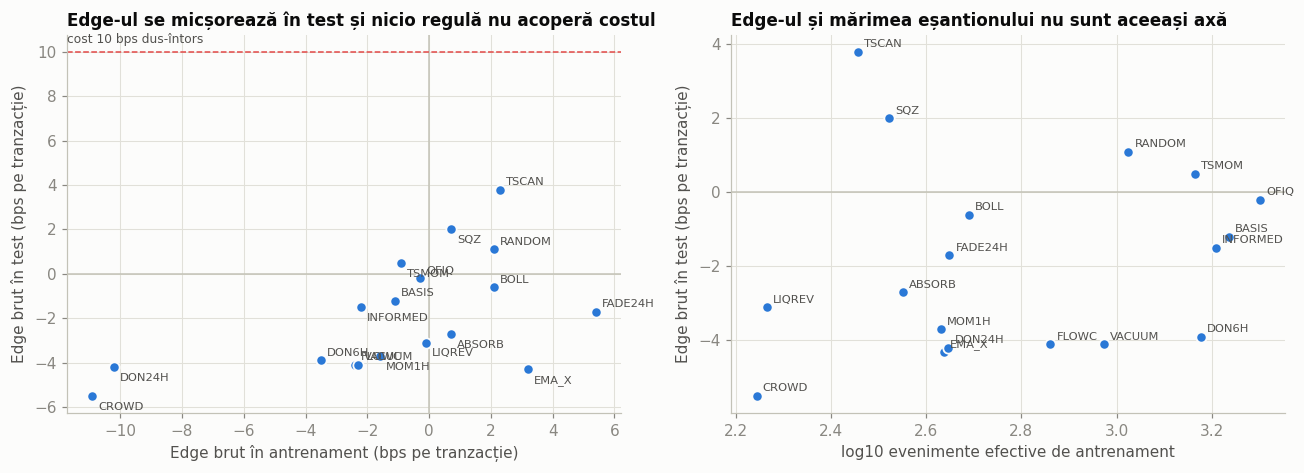

Across strategies: Spearman(edge dev, edge test) = 0.54; Spearman(edge test, log N eff train) = 0.21.


In [14]:
g = R.groupby("strategy", observed=True)
PRIM = pd.DataFrame({"family": [STRATS[k][1] for k in g.groups], "H (h)": [STRATS[k][2] for k in g.groups], "test events": g["n_test"].mean().round(0).to_numpy(), "per day": (g["n_test"].mean() / N_DAYS).round(2).to_numpy(),
                     "N eff train": g["neff_train"].mean().round(0).to_numpy(), "N eff test": g["neff_test"].mean().round(0).to_numpy(),
                     "win rate train": g["base_train"].mean().round(3).to_numpy(), "win rate test": g["base_test"].mean().round(3).to_numpy(),
                     "edge dev (gross bps)": g["gross_train"].mean().round(1).to_numpy(), "edge test (gross bps)": g["gross_test"].mean().round(1).to_numpy(), "net test (bps)": g["net_test"].mean().round(1).to_numpy(),
                     "sim trades": g["u_trades"].mean().round(0).to_numpy(), "sim net/trade": g["u_net_trade"].mean().round(1).to_numpy(), "sim Sharpe": g["u_sharpe"].mean().round(2).to_numpy()}, index=list(g.groups))
PRIM.index.name = "strategy"
display(PRIM)

hash_alt = lambda n_: list(PRIM.index).index(n_) % 2 == 0       # alternate label side to limit overlaps
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ax = axes[0]
xs, ys = PRIM["edge dev (gross bps)"].to_numpy(), PRIM["edge test (gross bps)"].to_numpy()
ax.axhline(0, color=AXIS, lw=1); ax.axvline(0, color=AXIS, lw=1); ax.axhline(COST_RT_BPS, color=C["red"], lw=1, ls="--")
ax.scatter(xs, ys, s=46, color=C["blue"], edgecolor=SURFACE, linewidth=1.2, zorder=3)
for n_, a_, b_ in zip(PRIM.index, xs, ys):
    ax.annotate(n_, (a_, b_), xytext=(4, 3 if hash_alt(n_) else -9), textcoords="offset points", fontsize=7.5, color=INK2)
ax.text(ax.get_xlim()[0], COST_RT_BPS + .4, "cost 10 bps dus-întors", fontsize=8, color=INK2)
ax.set_xlabel("Edge brut în antrenament (bps pe tranzacție)"); ax.set_ylabel("Edge brut în test (bps pe tranzacție)")
ax.set_title("Edge-ul se micșorează în test și nicio regulă nu acoperă costul")
ax = axes[1]
ax.axhline(0, color=AXIS, lw=1)
ax.scatter(np.log10(PRIM["N eff train"]), ys, s=46, color=C["blue"], edgecolor=SURFACE, linewidth=1.2, zorder=3)
for n_, a_, b_ in zip(PRIM.index, np.log10(PRIM["N eff train"]), ys):
    ax.annotate(n_, (a_, b_), xytext=(4, 3), textcoords="offset points", fontsize=7.5, color=INK2)
ax.set_xlabel("log10 evenimente efective de antrenament"); ax.set_ylabel("Edge brut în test (bps pe tranzacție)")
ax.set_title("Edge-ul și mărimea eșantionului nu sunt aceeași axă")
fig.tight_layout(); plt.show()
print(f"Across strategies: Spearman(edge dev, edge test) = {stats.spearmanr(xs, ys)[0]:.2f}; Spearman(edge test, log N eff train) = {stats.spearmanr(ys, PRIM['N eff train'])[0]:.2f}.")

**Interpretare.**

* **Nicio regulă nu acoperă costul.** Niciun `edge` brut din test nu ajunge la 10 bps, iar cel mai bun e `TSCAN`, cu +3.8 bps.
* **`Edge`-ul de dezvoltare se micșorează.** Clasamentul se păstrează parțial (Spearman 0.54), dar `FADE24H` scade de la +5.4 la −1.7 bps și `EMA_X` de la +3.2 la −4.3 bps. E ce trebuia să se întâmple după ce am ales reguli pe rezultate.
* **Execuția costă și ea.** `DON24H` și `FADE24H` sunt aceeași tranzacție în sensuri opuse, iar brutul lor însumat e −5.9 bps. Pierderea vine din intrarea la cel mai prost preț din secundă și din stopurile cu gap, înainte de orice comision.
* **`Edge` și N nu sunt legate** (Spearman 0.21). Designul a reușit să le separe, deci analiza din secțiunea 14 are sens.

## 11. Există informație pentru meta-labeling? `EXPLORATORY`

Rezultatele modelului selectat economic, în test. **Skill log loss** este câștigul de neg log loss față de predicția constantă cu rata de succes din antrenament. Pozitiv înseamnă că modelul bate constanta.

,n_test,neff_train,auc,lo,hi,p,neg_ll,neg_ll_base,skill,skill_lo,skill_hi,placebo,inject,bars_above,q,verdict
strategy,,,,,,,,,,,,,,,,
RANDOM,1410.0,1059.0,0.524,0.499,0.547,0.033,-0.6879,-0.6876,-0.0004,-0.0020,0.0010,0.491,0.581,3,NaN,SIGNAL
EMA_X,449.0,434.0,0.508,0.484,0.531,0.241,-0.6894,-0.6859,-0.0035,-0.0060,-0.0010,0.499,0.574,0,0.273,NO USEFUL SIGNAL
DON6H,1728.0,1502.0,0.556,0.535,0.578,0.000,-0.6695,-0.6741,0.0046,0.0011,0.0079,0.499,0.597,9,0.008,SIGNAL
DON24H,432.0,443.0,0.537,0.499,0.572,0.027,-0.6921,-0.6929,0.0008,-0.0015,0.0029,0.507,0.575,1,0.092,UNDERPOWERED
FADE24H,432.0,445.0,0.521,0.476,0.565,0.168,-0.6969,-0.6965,-0.0004,-0.0018,0.0010,0.504,0.568,1,0.237,UNDERPOWERED
TSMOM,1311.0,1461.0,0.515,0.485,0.543,0.181,-0.6859,-0.6860,0.0000,-0.0030,0.0030,0.497,0.571,0,0.237,NO USEFUL SIGNAL
BOLL,459.0,489.0,0.514,0.479,0.549,0.221,-0.6928,-0.6906,-0.0022,-0.0062,0.0018,0.495,0.556,0,0.268,NO USEFUL SIGNAL
SQZ,334.0,332.0,0.510,0.457,0.565,0.373,-0.6624,-0.6605,-0.0019,-0.0052,0.0012,0.495,0.581,0,0.396,UNDERPOWERED
TSCAN,286.0,286.0,0.529,0.481,0.582,0.130,-0.6937,-0.6884,-0.0052,-0.0128,0.0024,0.499,0.585,0,0.201,UNDERPOWERED


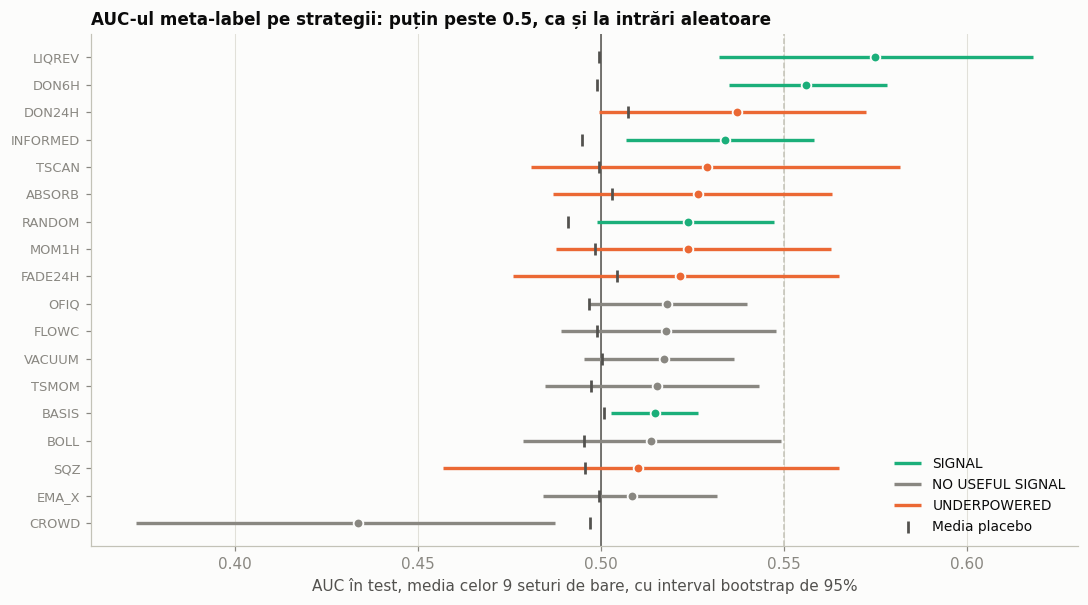

verdict
NO USEFUL SIGNAL    7
UNDERPOWERED        6
SIGNAL              5
Cells with positive log-loss skill: 75 of 161; mean AUC over real strategies 0.521; mean placebo 0.499 (sd across reps 0.025).


In [15]:
rows = []
real = [k for k in NAMES if STRATS[k][0][0] != "0"]
for k in NAMES:
    r = R[R["strategy"] == k]
    if r.empty:
        continue
    b = strat_boot("b_auc", k); dl = strat_boot("b_dll", k)
    rows.append(dict(strategy=k, tier=STRATS[k][0], cells=len(r), n_test=r["n_test"].mean(), neff_train=r["neff_train"].mean(), auc=r["auc"].mean(), lo=np.nanquantile(b, .025), hi=np.nanquantile(b, .975),
                     p=float(np.mean(b <= .5)), neg_ll=r["neg_ll"].mean(), neg_ll_base=r["neg_ll_base"].mean(), skill=(r["neg_ll"] - r["neg_ll_base"]).mean(), skill_lo=np.nanquantile(dl, .025), skill_hi=np.nanquantile(dl, .975),
                     placebo=r["placebo_mean"].mean(), inject=r["inject"].mean(), bars_above=int((r["auc_lo"] > .5).sum())))
Q1 = pd.DataFrame(rows).set_index("strategy")
m_ = Q1.index.isin(real)
Q1["q"] = np.nan
Q1.loc[m_, "q"] = multipletests(np.maximum(Q1.loc[m_, "p"], 1 / BOOT_REPS), method="fdr_bh")[1]
def verdict(r):
    if r["q"] < .05 and r["auc"] > .5 or (np.isnan(r["q"]) and r["p"] < .05):
        return "SIGNAL"
    return "NO USEFUL SIGNAL" if r["hi"] < AUC_RELEVANT else "UNDERPOWERED"
Q1["verdict"] = Q1.apply(verdict, axis=1)
display(Q1.drop(columns=["tier", "cells"]).round({"n_test": 0, "neff_train": 0, "auc": 3, "lo": 3, "hi": 3, "p": 3, "neg_ll": 4, "neg_ll_base": 4, "skill": 4, "skill_lo": 4, "skill_hi": 4, "placebo": 3, "inject": 3, "q": 3}))

fig, ax = plt.subplots(figsize=(10, 5.6))
Qs = Q1.sort_values("auc")
col = {"SIGNAL": C["aqua"], "NO USEFUL SIGNAL": MUTED, "UNDERPOWERED": C["orange"]}
yy = np.arange(len(Qs))
ax.axvline(.5, color=INK2, lw=1); ax.axvline(AUC_RELEVANT, color=AXIS, lw=1, ls="--")
for v, cc in col.items():
    m = (Qs["verdict"] == v).to_numpy()
    ax.hlines(yy[m], Qs["lo"][m], Qs["hi"][m], color=cc, lw=2.2, label=v)
    ax.scatter(Qs["auc"][m], yy[m], s=40, color=cc, edgecolor=SURFACE, linewidth=1.2, zorder=3)
ax.scatter(Qs["placebo"], yy, marker="|", s=70, color=INK2, zorder=4, label="Media placebo")
ax.set_yticks(yy); ax.set_yticklabels(Qs.index, fontsize=8.5); ax.grid(axis="y", visible=False)
ax.set_xlabel("AUC în test, media celor 9 seturi de bare, cu interval bootstrap de 95%")
ax.set_title("AUC-ul meta-label pe strategii: puțin peste 0.5, ca și la intrări aleatoare"); ax.legend(loc="lower right")
fig.tight_layout(); plt.show()
print(Q1["verdict"].value_counts().to_string())
print(f"Cells with positive log-loss skill: {(R['neg_ll'] > R['neg_ll_base']).sum()} of {len(R)}; mean AUC over real strategies {R[R['strategy'].isin(real)]['auc'].mean():.3f}; mean placebo {R['placebo_mean'].mean():.3f} (sd across reps {R['placebo_sd'].mean():.3f}).")

**Interpretare.**

* **Rezultatul pe verdictele fixate:** 4 reguli `SIGNAL` (`LIQREV`, `DON6H`, `INFORMED`, `BASIS`), 7 `NO USEFUL SIGNAL`, 6 `UNDERPOWERED`.
* **`RANDOM` iese și el `SIGNAL`** (0.524, p necorectat 0.033). Așa cum am anticipat în secțiunea 2.7, 0.5 e un prag prea blând pentru eticheta netă. Vezi tabelul următor.
* **`BASIS` trece testul, dar efectul e neglijabil.** Are AUC 0.515 cu limită superioară 0.526. Trece fiindcă are multe evenimente, nu fiindcă ar fi util.
* **Log loss-ul e mai aspru decât AUC-ul.** Doar `DON6H` are intervalul de skill complet peste zero, cu +0.0046 nats, adică 0.7% din log loss. `EMA_X`, `ABSORB` și `OFIQ` sunt clar **mai slabe** decât predicția constantă.
* **Placebo e centrat** (0.499), deci testul nu are scurgeri. Rotirea etichetelor de antrenament distruge tot.
* **`CROWD` e sub 0.5, cu interval care exclude 0.5.** Verdictul fixat este `NO USEFUL SIGNAL`, dar nu e de încredere. Secțiunea 13 arată că e un eșec al modelului, nu o măsurătoare curată a absenței semnalului.

### Controlul corect: comparația cu `RANDOM` și cu zero `POST-HOC`

`RANDOM` a ieșit și el peste 0.5, deci pragul de 0.5 e prea blând. Un AUC peste `RANDOM` înseamnă informație legată de strategie, nu de piață în general. Am adăugat acest tabel după ce am văzut rezultatul. În același tabel e intervalul pentru `edge`-ul din test, ca să se vadă dacă strategiile chiar diferă între ele.

In [16]:
b_rand = strat_boot("b_auc", "RANDOM")
rows = []
for k in real:
    b = strat_boot("b_auc", k) - b_rand
    e = strat_boot("b_edge", k)
    rows.append(dict(strategy=k, auc=Q1.loc[k, "auc"], d_vs_random=Q1.loc[k, "auc"] - Q1.loc["RANDOM", "auc"], d_lo=np.nanquantile(b, .025), d_hi=np.nanquantile(b, .975), p=max(float(np.mean(b <= 0)), 1 / BOOT_REPS),
                     edge_test=R[R["strategy"] == k]["gross_test"].mean(), edge_lo=np.nanquantile(e, .025), edge_hi=np.nanquantile(e, .975), verdict=Q1.loc[k, "verdict"]))
VSR = pd.DataFrame(rows).set_index("strategy")
VSR["q"] = multipletests(VSR["p"], method="fdr_bh")[1]
display(VSR.sort_values("d_vs_random", ascending=False).round(3))
print(f"Rules above RANDOM at q<0.05: {list(VSR.index[VSR['q'] < .05])}. Rules with a test-edge interval excluding zero: {list(VSR.index[(VSR['edge_lo'] > 0) | (VSR['edge_hi'] < 0)])}. Rules with the interval above the 10 bps cost: {list(VSR.index[VSR['edge_lo'] > COST_RT_BPS])}.")

,auc,d_vs_random,d_lo,d_hi,p,edge_test,edge_lo,edge_hi,verdict,q
strategy,,,,,,,,,,
LIQREV,0.575,0.051,0.005,0.100,0.015,-3.071,-9.393,3.377,SIGNAL,0.145
DON6H,0.556,0.032,0.005,0.063,0.017,-3.933,-7.901,0.187,SIGNAL,0.145
DON24H,0.537,0.013,-0.033,0.059,0.303,-4.233,-12.926,4.588,UNDERPOWERED,0.847
INFORMED,0.534,0.010,-0.019,0.041,0.289,-1.481,-3.655,0.187,SIGNAL,0.847
TSCAN,0.529,0.005,-0.050,0.068,0.416,3.758,-2.868,9.685,UNDERPOWERED,0.847
ABSORB,0.526,0.003,-0.041,0.050,0.475,-2.711,-4.903,-0.480,UNDERPOWERED,0.847
MOM1H,0.524,-0.000,-0.041,0.043,0.494,-3.723,-8.530,0.848,UNDERPOWERED,0.847
FADE24H,0.521,-0.002,-0.048,0.046,0.532,-1.662,-10.613,7.233,UNDERPOWERED,0.847
OFIQ,0.518,-0.006,-0.037,0.026,0.619,-0.213,-1.799,1.273,NO USEFUL SIGNAL,0.847


Rules above RANDOM at q<0.05: []. Rules with a test-edge interval excluding zero: ['FLOWC', 'ABSORB', 'VACUUM']. Rules with the interval above the 10 bps cost: [].


**Interpretare.**

* **Nicio regulă nu bate `RANDOM` după corecție** (cel mai mic q e 0.145). `LIQREV` (+0.051) și `DON6H` (+0.032) au intervalele peste zero, dar numai necorectat.
* **`RANDOM` e o singură extragere**, deci și reperul e zgomotos. Secțiunea 13 arată că AUC-ul variază cu aproximativ 0.025 între extrageri. Tabelul trebuie citit ca "nimic nu se desprinde clar", nu ca o dovadă că toate sunt egale.
* **`Edge`-urile din test abia se pot deosebi.** Doar trei intervale exclud zero, toate negative: `FLOWC`, `ABSORB`, `VACUUM`. Nicio regulă nu are `edge` brut pozitiv demonstrat. Asta contează mult pentru secțiunea 14.

### Îmbunătățește filtrul strategia primară?

Filtrul cu retenție fixă de 50% e comparat cu nefiltrat și cu un filtru aleator de aceeași mărime, prin aceeași politică de poziție. **Uplift** înseamnă bps net pe eveniment păstrat minus bps net pe toate evenimentele. Intervalul folosește bootstrap comun pe toate seturile.

,edge_test,net_all,net_filter50,net_filter_pick,random50,uplift,up_lo,up_hi,sim_trades_f50,sharpe_all,sharpe_f50,sharpe_pick,mean_pct_vs_random,bars_improve,bars_positive_f50
strategy,,,,,,,,,,,,,,,
RANDOM,1.1,-7.8,-8.5,-10.5,-8.7,1.3,-2.0,4.6,447.0,-3.62,-2.49,-2.22,0.53,0,0
EMA_X,-4.3,-15.5,-13.6,-13.3,-15.0,0.8,-1.9,3.4,207.0,-4.86,-3.37,-2.68,0.61,1,0
DON6H,-3.9,-16.0,-13.0,-11.8,-14.9,1.6,-1.1,4.1,637.0,-8.61,-4.70,-3.43,0.79,1,0
DON24H,-4.2,-12.2,-9.6,-9.7,-12.9,2.8,-2.9,8.9,209.0,-2.52,-1.40,-1.05,0.72,1,0
FADE24H,-1.7,-13.2,-9.8,-7.2,-12.2,2.6,-4.0,8.9,201.0,-2.71,-1.45,-0.86,0.64,1,0
TSMOM,0.5,-10.8,-9.3,-9.4,-10.1,0.8,-2.9,4.6,538.0,-5.65,-2.99,-2.22,0.62,0,0
BOLL,-0.6,-10.6,-12.4,-10.8,-10.9,-2.0,-5.8,1.9,206.0,-4.72,-3.18,-2.04,0.32,0,0
SQZ,2.0,-11.0,-12.2,-5.6,-9.8,-3.6,-8.5,0.9,128.0,-2.63,-1.93,-0.71,0.37,0,0
TSCAN,3.8,-5.9,-2.1,-1.3,-5.4,3.7,-2.6,9.2,110.0,-2.03,-0.43,-0.17,0.77,1,1


filter_verdict
REDUCES EXPOSURE ONLY     141
TOO FEW TRADES              9
IMPROVES TRADE QUALITY      8
NO IMPROVEMENT              3


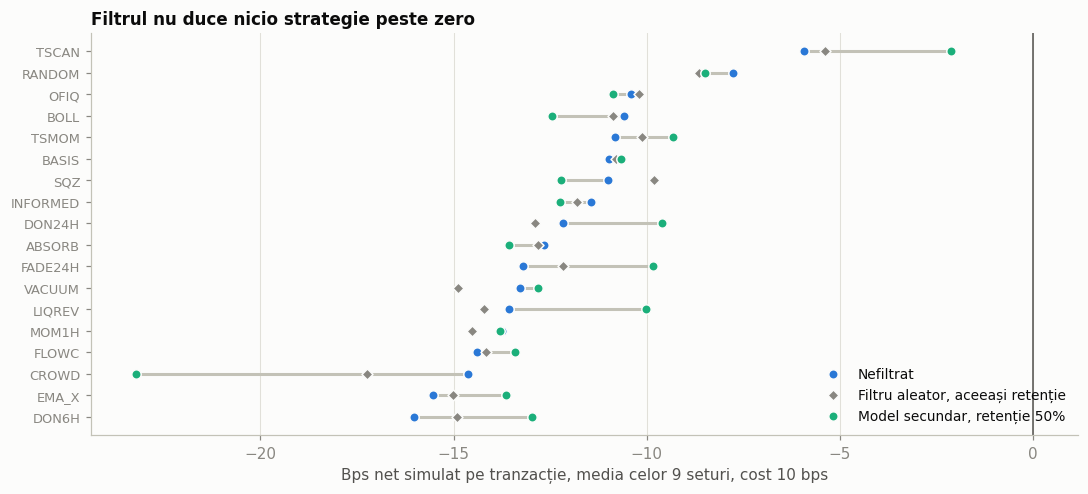

unfiltered             filter50            
cost             4     7     10       4     7     10
strategy                                            
RANDOM         -1.8  -4.8  -7.8     -2.5  -5.5  -8.5
EMA_X          -9.5 -12.5 -15.5     -7.6 -10.6 -13.6
DON6H         -10.0 -13.0 -16.0     -7.0 -10.0 -13.0
DON24H         -6.2  -9.2 -12.2     -3.6  -6.6  -9.6
FADE24H        -7.2 -10.2 -13.2     -3.8  -6.8  -9.8
TSMOM          -4.8  -7.8 -10.8     -3.3  -6.3  -9.3
BOLL           -4.6  -7.6 -10.6     -6.4  -9.4 -12.4
SQZ            -5.0  -8.0 -11.0     -6.2  -9.2 -12.2
TSCAN           0.1  -2.9  -5.9      3.9   0.9  -2.1
MOM1H          -7.7 -10.7 -13.7     -7.8 -10.8 -13.8
FLOWC          -8.4 -11.4 -14.4     -7.4 -10.4 -13.4
ABSORB         -6.6  -9.6 -12.6     -7.6 -10.6 -13.6
OFIQ           -4.4  -7.4 -10.4     -4.9  -7.9 -10.9
INFORMED       -5.4  -8.4 -11.4     -6.2  -9.2 -12.2
VACUUM         -7.3 -10.3 -13.3     -6.8  -9.8 -12.8
LIQREV         -7.6 -10.6 -13.6     -4.0  -7.0 -10.0
BASIS          -5.0  -8.0 -11.0     -4.7  -7.7 -10.7
CROWD          -8.6 -11.6 -14.6    -17.2 -20.2 -23.2

In [17]:
def fverdict(r):
    if r["f50_trades"] < MIN_TEST_TRADES:
        return "TOO FEW TRADES"
    if r["f50_net_trade"] > r["u_net_trade"] and r["pct_vs_random"] >= .95:
        return "IMPROVES TRADE QUALITY"
    if r["f50_total"] > r["u_total"]:
        return "REDUCES EXPOSURE ONLY"
    return "NO IMPROVEMENT"
R["filter_verdict"] = R.apply(fverdict, axis=1)
rows = []
for k in NAMES:
    r = R[R["strategy"] == k]
    if r.empty:
        continue
    bu = strat_boot("b_up", k)
    rows.append(dict(strategy=k, edge_test=r["gross_test"].mean(), net_all=r["u_net_trade"].mean(), net_filter50=r["f50_net_trade"].mean(), net_filter_pick=r["fp_net_trade"].mean(), random50=r["rand_net_trade"].mean(), uplift=r["uplift50"].mean(), up_lo=np.nanquantile(bu, .025), up_hi=np.nanquantile(bu, .975),
                     sim_trades_f50=r["f50_trades"].mean(), sharpe_all=r["u_sharpe"].mean(), sharpe_f50=r["f50_sharpe"].mean(), sharpe_pick=r["fp_sharpe"].mean(), mean_pct_vs_random=r["pct_vs_random"].mean(), bars_improve=int((r["filter_verdict"] == "IMPROVES TRADE QUALITY").sum()), bars_positive_f50=int((r["f50_net_trade"] > 0).sum())))
ECON = pd.DataFrame(rows).set_index("strategy")
display(ECON.round({"edge_test": 1, "net_all": 1, "net_filter50": 1, "net_filter_pick": 1, "random50": 1, "uplift": 1, "up_lo": 1, "up_hi": 1, "sim_trades_f50": 0, "sharpe_all": 2, "sharpe_f50": 2, "sharpe_pick": 2, "mean_pct_vs_random": 2}))
print(R["filter_verdict"].value_counts().to_string())

fig, ax = plt.subplots(figsize=(10, 4.6))
Es = ECON.sort_values("net_all"); yy = np.arange(len(Es))
ax.axvline(0, color=INK2, lw=1)
ax.hlines(yy, Es["net_all"], Es["net_filter50"], color=AXIS, lw=2)
ax.scatter(Es["net_all"], yy, s=38, color=C["blue"], label="Nefiltrat", zorder=3, edgecolor=SURFACE)
ax.scatter(Es["random50"], yy, s=26, marker="D", color=MUTED, label="Filtru aleator, aceeași retenție", zorder=3, edgecolor=SURFACE)
ax.scatter(Es["net_filter50"], yy, s=38, color=C["aqua"], label="Model secundar, retenție 50%", zorder=4, edgecolor=SURFACE)
ax.set_yticks(yy); ax.set_yticklabels(Es.index, fontsize=8.5); ax.grid(axis="y", visible=False)
ax.set_xlabel("Bps net simulat pe tranzacție, media celor 9 seturi, cost 10 bps"); ax.set_title("Filtrul nu duce nicio strategie peste zero"); ax.legend(loc="lower right")
fig.tight_layout(); plt.show()

# Cost sensitivity: same decisions, lower fee level.
rows = []
for k in NAMES:
    for cost in (10, 7, 4):
        v = R[R["strategy"] == k]
        rows.append(dict(strategy=k, cost=cost, unfiltered=(v["u_net_trade"] + 10 - cost).mean(), filter50=(v["f50_net_trade"] + 10 - cost).mean()))
COST = pd.DataFrame(rows).pivot(index="strategy", columns="cost", values=["unfiltered", "filter50"]).loc[[k for k in NAMES if k in ECON.index]]
display(COST.round(1))

**Interpretare.**

* **Nicio strategie nu ajunge pe plus** la 10 bps. Doar 2 din 161 de celule filtrate au net pozitiv, iar cel mai bun mediu este `TSCAN`, cu −2.1 bps.
* **Filtrele nu selectează mai bine decât hazardul.** Toate intervalele de uplift includ zero. `IMPROVES TRADE QUALITY` apare în 8 din 161 de celule, adică 5.0%, exact rata de fals pozitive la percentila 95.
* **Verdictul dominant e `REDUCES EXPOSURE ONLY`** (141 de celule). Total, pierzi mai puțin pentru că tranzacționezi mai puțin. Filtrul aleator face aproape la fel.
* **Sharpe-ul crește aproape peste tot, și e o capcană.** O strategie care pierde are Sharpe mai puțin negativ dacă are mai puține tranzacții.
* **`LIQREV`, `TSCAN`, `DON24H` și `FADE24H` au cele mai mari uplift-uri** (+2.6 la +3.7 bps), dar intervalele lor sunt largi, fiindcă au puține tranzacții.
* **La 4 bps cost**, ceva apropiat de execuție cu ordine limită, doar `TSCAN` devine pozitiv: +0.1 bps nefiltrat, +3.9 bps filtrat, pe aproximativ 110 tranzacții simulate. Tabelul mută doar comisionul; ordinele limită nu se umplu mereu, deci cifra e optimistă.

## 12. Cu ce features? `EXPLORATORY`

Modelul de referință, cu aceleași ferestre. Stânga: AUC-ul fiecărei familii **singure**. Dreapta: ce se pierde când familia e **scoasă** din modelul complet. Prima măsoară informație, a doua informație unică. Punctele marchează celulele cu BH q sub 0.05 pe tot tabelul, din bootstrap comun.

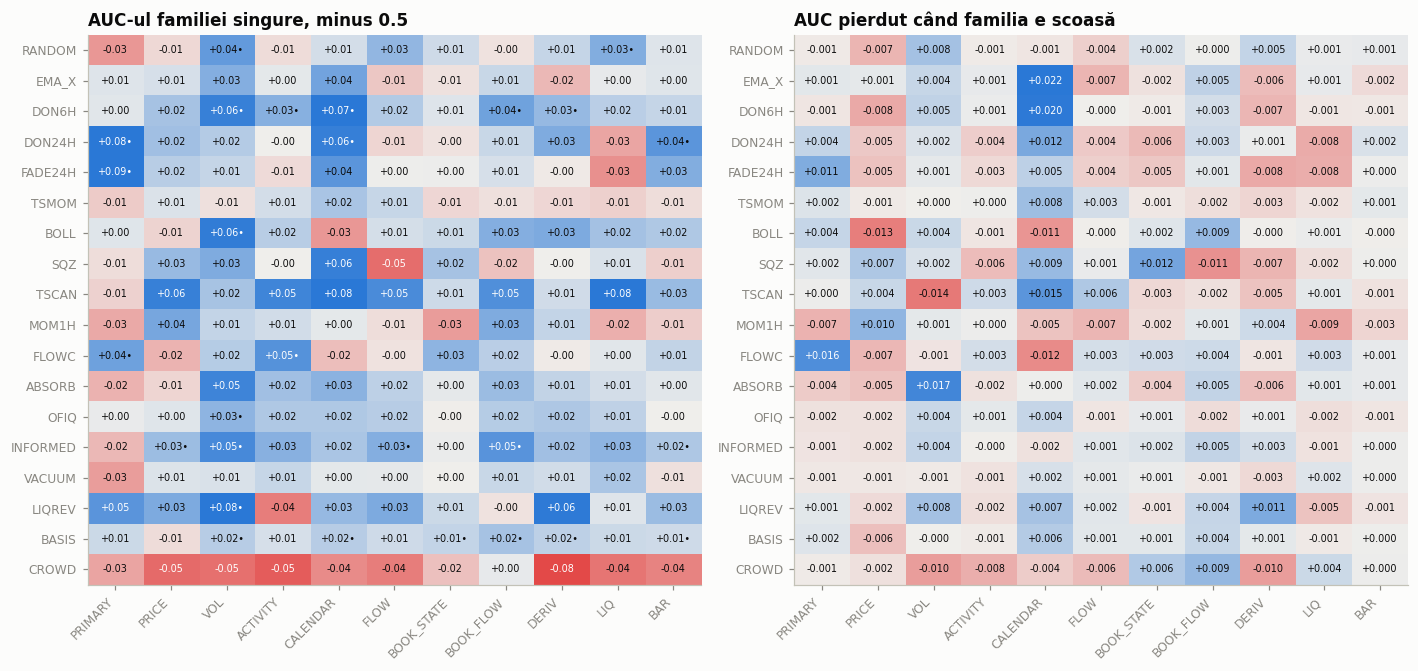

Family-alone cells above 0.5 at q<0.05: 27 of 198. Unique-value cells at q<0.05: 0 of 198.


,mean AUC alone,strategies q<0.05,mean unique AUC,unique q<0.05
VOL,0.5265,6,0.0016,0
CALENDAR,0.5238,3,0.0046,0
BOOK_FLOW,0.5177,3,0.0021,0
PRICE,0.5100,1,-0.0022,0
ACTIVITY,0.5096,2,-0.0010,0
DERIV,0.5089,2,-0.0021,0
BAR,0.5083,3,-0.0002,0
PRIMARY,0.5075,3,0.0016,0
LIQ,0.5052,0,-0.0015,0
FLOW,0.5047,1,-0.0006,0


,PRIMARY,PRICE,VOL,ACTIVITY,CALENDAR,FLOW,BOOK_STATE,BOOK_FLOW,DERIV,LIQ,BAR
RANDOM,0.468,0.492,0.542,0.493,0.508,0.528,0.510,0.495,0.513,0.533,0.505
EMA_X,0.505,0.508,0.532,0.504,0.538,0.486,0.495,0.512,0.481,0.503,0.505
DON6H,0.504,0.522,0.556,0.532,0.573,0.519,0.505,0.539,0.527,0.516,0.513
DON24H,0.578,0.524,0.518,0.500,0.556,0.491,0.496,0.512,0.534,0.473,0.545
FADE24H,0.590,0.517,0.513,0.493,0.545,0.501,0.501,0.508,0.498,0.466,0.533
TSMOM,0.487,0.506,0.495,0.509,0.521,0.512,0.491,0.495,0.491,0.489,0.494
BOLL,0.505,0.490,0.557,0.517,0.468,0.508,0.511,0.532,0.535,0.523,0.519
SQZ,0.494,0.526,0.534,0.500,0.556,0.453,0.522,0.484,0.500,0.507,0.489
TSCAN,0.489,0.556,0.522,0.553,0.581,0.550,0.510,0.548,0.510,0.585,0.526
MOM1H,0.475,0.536,0.513,0.509,0.503,0.494,0.470,0.534,0.514,0.477,0.488


In [18]:
fams = list(FAMILIES)
SN = [k for k in NAMES if k in set(R["strategy"])]
ALONE = pd.DataFrame({f: {k: np.nanmean([EVAL[(k, b)]["fam"][f]["alone"] for b in ALL_BARS if (k, b) in EVAL]) for k in SN} for f in fams})
LOFO = pd.DataFrame({f: {k: np.nanmean([EVAL[(k, b)]["fam"][f]["lofo"] for b in ALL_BARS if (k, b) in EVAL]) for k in SN} for f in fams})
def fam_p(field, null):
    P = pd.DataFrame(index=SN, columns=fams, dtype=float)
    for k in SN:
        for f in fams:
            a = np.nanmean(np.stack([EVAL[(k, b)][field][f] for b in ALL_BARS if (k, b) in EVAL]), axis=0)
            P.loc[k, f] = max(np.mean(a <= null), 1 / 300)
    return P
P_ALONE, P_LOFO = fam_p("fam_a", .5), fam_p("fam_l", 0.)
Q_ALONE = pd.DataFrame(multipletests(P_ALONE.to_numpy().ravel(), method="fdr_bh")[1].reshape(P_ALONE.shape), index=SN, columns=fams)
Q_LOFO = pd.DataFrame(multipletests(P_LOFO.to_numpy().ravel(), method="fdr_bh")[1].reshape(P_LOFO.shape), index=SN, columns=fams)

fig, axes = plt.subplots(1, 2, figsize=(13, 6.2))
for ax, M, Qm, title, v, fmt in ((axes[0], ALONE - .5, Q_ALONE, "AUC-ul familiei singure, minus 0.5", .06, "{:+.2f}"), (axes[1], LOFO, Q_LOFO, "AUC pierdut când familia e scoasă", .02, "{:+.3f}")):
    im = ax.imshow(M.to_numpy(), cmap=DIV, norm=TwoSlopeNorm(0, -v, v), aspect="auto")
    ax.set_xticks(range(len(fams))); ax.set_xticklabels(fams, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(SN))); ax.set_yticklabels(SN, fontsize=8); ax.grid(False); ax.set_title(title)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            x = M.iat[i, j]
            ax.text(j, i, fmt.format(x) + ("•" if Qm.iat[i, j] < .05 and x > 0 else ""), ha="center", va="center", fontsize=6.3, color="white" if abs(x) > .75 * v else INK)
fig.tight_layout(); plt.show()
print(f"Family-alone cells above 0.5 at q<0.05: {int(((Q_ALONE < .05) & (ALONE > .5)).sum().sum())} of {ALONE.size}. Unique-value cells at q<0.05: {int(((Q_LOFO < .05) & (LOFO > 0)).sum().sum())} of {LOFO.size}.")
FAM_SUMMARY = pd.DataFrame({"mean AUC alone": ALONE.loc[[k for k in SN if k in real]].mean(), "strategies q<0.05": ((Q_ALONE < .05) & (ALONE > .5)).loc[[k for k in SN if k in real]].sum(), "mean unique AUC": LOFO.loc[[k for k in SN if k in real]].mean(), "unique q<0.05": ((Q_LOFO < .05) & (LOFO > 0)).loc[[k for k in SN if k in real]].sum()}).sort_values("mean AUC alone", ascending=False)
display(FAM_SUMMARY.round(4))
display((ALONE).round(3))

**Interpretare.**

* **Informația există în câteva familii, dar e redundantă.** 27 din 198 de combinații familie-strategie trec testul singure. **0 din 198** au valoare unică. Dacă scoți o familie, restul o acoperă.
* **`VOL` e familia dominantă** (AUC mediu 0.527, semnificativă pe 6 reguli reale). Apoi `CALENDAR` (0.524), care e tot volatilitate: ora și ziua prezic activitatea. `CALENDAR` are cel mai mare aport unic, +0.005.
* **`BOOK_FLOW` e a treia** (0.518), mai ales pe `DON6H` și `INFORMED`.
* **`BOOK_STATE` și `FLOW` nu aduc aproape nimic** (0.503 și 0.505). Dezechilibrul din book mișcă prețul cu sub un bps și în câteva secunde, deci nu are ce să spună despre o tranzacție de 1–8 ore. E în acord cu notebook-ul de explorare.
* **`PRIMARY` contează doar pentru `DON24H` și `FADE24H`** (0.578 și 0.590) și `FLOWC`. Motorul este performanța recentă a regulii, discutată mai jos.
* **`RANDOM` are și el `VOL` semnificativ.** Deci informația din `VOL` nu e despre strategie. Este despre piață.

### Ce a selectat procedura pe date de antrenament

Frecvența cu care fiecare cluster a fost ales de MDA, pe toate celulele și blocurile. Selecția vede doar antrenamentul, deci arată ce părea important înainte de test, nu ce a funcționat.

In [19]:
sel_count = np.zeros((len(SN), len(CLUSTERS))); n_rec = np.zeros(len(SN))
for (k, b), m in MAIN.items():
    for rec in m["blocks"]:
        if not rec["skipped"]:
            sel_count[SN.index(k), rec["sel_clusters"]] += 1; n_rec[SN.index(k)] += 1
SELF = pd.DataFrame(sel_count / n_rec[:, None], index=SN, columns=[CL_NAME[i] for i in range(len(CLUSTERS))])
top = SELF.mean().sort_values(ascending=False).head(12)
print("Clusters chosen most often, share of all cell-blocks:"); print(top.round(3).to_string())
print(f"Clusters chosen per cell-block: {sel_count.sum() / n_rec.sum():.1f} of {len(CLUSTERS)}. Share of model picks: ")
picks = pd.DataFrame([dict(strategy=k, bars=b, block=r["block"], cfg=CFG_NAME[r["pick"][0]], kind=CONFIGS[r["pick"][0]]["kind"], fset=FEATURE_SETS[r["pick"][1]], ret=r["ret_pick"], cfg_ll=CFG_NAME[r["pick_ll"][0]], fset_ll=FEATURE_SETS[r["pick_ll"][1]], cv_econ=r["cv_econ_pick"], cv_unf=r["cv_econ_unf"]) for (k, b), m in MAIN.items() for r in m["blocks"] if not r["skipped"]])
display(pd.concat([picks["kind"].value_counts(normalize=True), picks["fset"].value_counts(normalize=True), picks["ret"].value_counts(normalize=True)]).round(3).to_frame("share of picks"))

Clusters chosen most often, share of all cell-blocks:
lrv_2m + lrv_15m + lrv_1h (+14)                            0.394
dow_sin + is_weekend                                       0.361
s_z_ret_2m + s_z_ret_15m + s_z_ret_1h (+21)                0.343
recent_hit_20 + recent_pnl_20                              0.320
l_rv_ratio_2m_1h + rel_eff_spread_2m + z_bar_range         0.287
oi_change_rz_7d                                            0.285
side + s_basis_bps + s_funding_bps                         0.281
hour_cos                                                   0.275
s_basis_chg_15m + s_basis_chg_1h + s_z_ret_vs_index_15m    0.273
s_run_volume                                               0.273
oi_chg_24h + oi_level_rz_7d                                0.267
lrv_24h + l_width                                          0.264
Clusters chosen per cell-block: 8.8 of 35. Share of model picks: 


,share of picks
logit,0.692
lgb,0.308
CORE,0.783
SEL,0.180
ALL,0.037
0.3,0.905
0.5,0.081
0.7,0.014


**Interpretare.**

* **Selecția pe antrenament a preferat aceleași lucruri ca testul**: clusterul de volatilitate și activitate apare primul (39%).
* **Dar stabilitatea e joasă.** Niciun cluster nu e ales în mai mult de 40% din cazuri, deci alegerea se schimbă de la o celulă la alta.
* **Selecția economică ajunge aproape mereu la modelul simplu:** `CORE` în 78% din cazuri, logit în 69%. Asta face regula one-SE când diferențele dintre candidați sunt sub zgomot. Retenția de 30% e aleasă în 90% din cazuri, fiindcă pentru o strategie care pierde, a tranzacționa mai puțin îmbunătățește mereu Sharpe-ul.

### De ce diferă features între strategii: semne pe familii de strategii

Pentru fiecare feature calculez corelația de rang cu rezultatul **brut** al tranzacției în unități de barieră (`gross / lățime`), pe evenimentele de test, media pe seturile de bare. Folosesc brutul intenționat: `net / lățime` conține `−cost / lățime`, care crește mecanic cu volatilitatea. O prima versiune a acestei analize, pe net, punea volatilitatea pe primul loc exact din acest motiv. Grupez apoi pe familia economică a strategiei. Dacă un feature ajută trendul și strică reversia, are semn opus în coloane. Stabilitatea compară aceeași corelație în antrenament și în test.

In [20]:
def cell_ic(key):
    c = CELLS[key]; E = c["E"]; X = c["X"]
    r = (E["gross_bps"] / (1e4 * E["width"])).to_numpy()      # gross: net / width would contain -cost / width, which rises with volatility by construction
    last_tr, _ = block_index(E, 0)
    te = np.concatenate([block_index(E, b)[1] for b in range(len(BLOCKS))])
    def ic(idx):
        if idx.size < 30:
            return np.full(X.shape[1], np.nan)
        return pd.DataFrame(X[idx]).corrwith(pd.Series(r[idx]), method="spearman").to_numpy()
    return key, ic(last_tr), ic(te)

IC = pmap(cell_ic, KEYS, key=cell_cost)
IC_TEST = pd.DataFrame({key: te for key, tr, te in IC}, index=FEATS).T
IC_TRAIN = pd.DataFrame({key: tr for key, tr, te in IC}, index=FEATS).T
ICS_TEST = IC_TEST.groupby(level=0).mean().loc[SN]; ICS_TRAIN = IC_TRAIN.groupby(level=0).mean().loc[SN]
STRAT_FAM = pd.Series({k: STRATS[k][1] for k in SN})
ICF = ICS_TEST.groupby(STRAT_FAM).mean().T
ICF["spread"] = ICF.max(axis=1) - ICF.min(axis=1)
ICF["family"] = [FAM_OF[c] for c in ICF.index]
pair = pd.DataFrame({"train": ICS_TRAIN.stack(), "test": ICS_TEST.stack()}).dropna()
print(f"Stability of strategy-feature rank correlations: Spearman(train, test) = {stats.spearmanr(pair['train'], pair['test'])[0]:.3f} on {len(pair)} pairs; same sign on {np.mean(np.sign(pair['train']) == np.sign(pair['test'])):.1%}.")
print("Strongest absolute test IC, mean over bar sets:")
TOPIC = ICS_TEST.stack().rename("ic_test").to_frame()
TOPIC["ic_train"] = ICS_TRAIN.stack()
TOPIC["n"] = [R[R["strategy"] == k]["n_test"].mean() for k, f in TOPIC.index]
TOPIC["t_naive"] = TOPIC["ic_test"] * np.sqrt(TOPIC["n"])
TOPIC = TOPIC.reindex(TOPIC["ic_test"].abs().sort_values(ascending=False).index)
display(TOPIC.head(20).round(3))
print("Features whose sign differs most between strategy families:")
display(ICF.sort_values("spread", ascending=False).head(14).round(3))

# Do differences between trend and reversal rules persist from training to test?
ICF_TR = ICS_TRAIN.groupby(STRAT_FAM).mean().T
dtest, dtrain = ICF["reversal"] - ICF["trend"], ICF_TR["reversal"] - ICF_TR["trend"]
INTER = pd.DataFrame({"family": ICF["family"], "reversal - trend, train": dtrain, "reversal - trend, test": dtest, "trend train": ICF_TR["trend"], "trend test": ICF["trend"], "reversal train": ICF_TR["reversal"], "reversal test": ICF["reversal"]})
print(f"Reversal-minus-trend gap across features: Spearman(train, test) = {stats.spearmanr(dtrain, dtest)[0]:+.3f}; same sign on {np.mean(np.sign(dtrain) == np.sign(dtest)):.1%} of {len(dtest)} features.")
print("Features with the largest same-sign gap in both periods:")
display(INTER[np.sign(dtrain) == np.sign(dtest)].assign(m=lambda d: np.minimum(d.iloc[:, 1].abs(), d.iloc[:, 2].abs())).sort_values("m", ascending=False).head(8).drop(columns="m").round(3))
print("Recent primary performance, IC by rule (train, test):")
display(pd.DataFrame({"hit train": ICS_TRAIN["recent_hit_20"], "hit test": ICS_TEST["recent_hit_20"], "pnl train": ICS_TRAIN["recent_pnl_20"], "pnl test": ICS_TEST["recent_pnl_20"]}).round(3))

def decile_view(strategy, feature, q=5):
    # Pooled test events over the bar sets, by quintile of the feature computed inside each cell.
    out = []
    for b in ALL_BARS:
        if (strategy, b) not in EVAL:
            continue
        c = CELLS[(strategy, b)]; E = c["E"]
        te = np.concatenate([block_index(E, i)[1] for i in range(len(BLOCKS))])
        x = pd.Series(c["X"][te, FIDX[feature]].astype(float))
        out.append(pd.DataFrame({"bin": pd.qcut(x.rank(method="first"), q, labels=False), "net": E["net_bps"].to_numpy()[te], "gross": E["gross_bps"].to_numpy()[te], "y": E["y"].to_numpy()[te], "barrier": (E["reason"].to_numpy()[te] != EXIT_TIME)}))
    return pd.concat(out).groupby("bin").mean()

Stability of strategy-feature rank correlations: Spearman(train, test) = 0.087 on 1781 pairs; same sign on 52.9%.
Strongest absolute test IC, mean over bar sets:


ic_test  ic_train        n  t_naive
SQZ     s_range_pos_24h     0.185    -0.075  333.556    3.380
CROWD   s_large_flow_15m   -0.184     0.126  190.667   -2.544
DON24H  s_oi_x_ret_1h       0.182    -0.021  431.889    3.789
CROWD   s_tfi_ratio_15m    -0.179     0.110  190.667   -2.468
        s_z_vwap_15m       -0.169     0.180  190.667   -2.339
DON24H  oi_chg_1h           0.167    -0.038  431.889    3.473
        recent_pnl_20      -0.167    -0.036  431.889   -3.463
FADE24H s_oi_x_ret_1h       0.166     0.004  431.889    3.446
CROWD   s_ofi_15m          -0.161    -0.051  190.667   -2.217
TSCAN   s_z_ret_4h          0.153    -0.025  285.667    2.593
FADE24H oi_chg_1h          -0.152     0.014  431.889   -3.163
        recent_pnl_20      -0.146    -0.028  431.889   -3.034
        recent_hit_20      -0.145    -0.050  431.889   -3.004
DON24H  recent_hit_20      -0.142    -0.003  431.889   -2.960
TSCAN   s_slog_liq_15m      0.138    -0.075  285.667    2.325
        s_tfi_ratio_15m     0.136    -0.003  285.667    2.303
        s_large_flow_15m    0.136     0.008  285.667    2.295
CROWD   s_path_eff_15m     -0.135     0.169  190.667   -1.863
        rel_tw_spread_2m    0.133    -0.031  190.667    1.837
TSCAN   s_z_vwap_1h         0.129     0.088  285.667    2.181

Features whose sign differs most between strategy families:


,control,flow,reversal,trend,spread,family
oi_chg_1h,0.001,0.025,-0.063,0.034,0.097,DERIV
lrv_4h,0.055,-0.019,0.048,-0.032,0.087,VOL
rel_tw_spread_2m,-0.025,-0.030,0.051,-0.020,0.081,BOOK_STATE
l_since_prev,0.053,0.005,-0.025,0.009,0.078,PRIMARY
recent_pnl_20,0.009,-0.028,-0.059,-0.066,0.075,PRIMARY
l_width,0.057,0.018,0.023,-0.017,0.074,VOL
lrv_24h,0.057,0.019,0.023,-0.017,0.074,VOL
lrv_15m,0.053,-0.020,0.035,-0.017,0.073,VOL
lrv_1h,0.056,-0.015,0.041,-0.001,0.070,VOL
dow_sin,0.054,-0.015,0.008,-0.001,0.070,CALENDAR


Reversal-minus-trend gap across features: Spearman(train, test) = -0.025; same sign on 44.4% of 99 features.
Features with the largest same-sign gap in both periods:


,family,"reversal - trend, train","reversal - trend, test",trend train,trend test,reversal train,reversal test
z_max_ret_15m,VOL,-0.061,-0.059,-0.013,0.021,-0.073,-0.038
strength,PRIMARY,-0.051,-0.053,0.017,0.032,-0.034,-0.021
l_width,VOL,0.064,0.041,0.008,-0.017,0.072,0.023
s_tfi_ratio_1h,FLOW,-0.041,-0.045,0.035,0.026,-0.006,-0.019
lrv_24h,VOL,0.064,0.040,0.008,-0.017,0.072,0.023
z_bar_range,BAR,-0.038,-0.047,0.002,0.017,-0.036,-0.030
lrv_4h,VOL,0.036,0.080,0.006,-0.032,0.042,0.048
hour_sin,CALENDAR,-0.062,-0.033,0.021,0.021,-0.041,-0.012


Recent primary performance, IC by rule (train, test):


,hit train,hit test,pnl train,pnl test
RANDOM,-0.021,0.011,-0.036,0.009
EMA_X,0.047,-0.039,0.039,-0.040
DON6H,-0.064,-0.036,-0.049,-0.034
DON24H,-0.003,-0.142,-0.036,-0.167
FADE24H,-0.050,-0.145,-0.028,-0.146
TSMOM,0.005,-0.011,-0.000,-0.028
BOLL,-0.004,-0.052,0.002,-0.042
SQZ,-0.027,-0.018,-0.068,-0.034
TSCAN,-0.000,-0.066,0.009,-0.112
MOM1H,-0.021,0.016,-0.052,-0.047


**Interpretare.**

* **Diferențele dintre strategii sunt reale în test, dar nu se păstrează.** Corelația importanțelor între antrenament și test e 0.087, iar semnul coincide în 52.9% din cazuri. E practic o monedă.
* **Tabelul cu cele mai mari corelații din test o arată direct:** `s_range_pos_24h` pe `SQZ` are +0.185 în test și −0.075 în antrenament. `s_oi_x_ret_1h` pe `DON24H` are +0.182 și −0.021. Multe vârfuri din test sunt doar vârfuri.
* **Diferența trend-reversie nu e stabilă nici ea.** Pe 99 de features, corelația dintre diferența din antrenament și cea din test e −0.025.
* **Câteva tipare au sens economic, dar sunt doar ipoteze.** Au același semn în ambele perioade, deși sunt alese după aceea, din 44 de features:
  * **Volatilitatea trailing ajută reversia și nu trendul** (`l_width`, `lrv_4h`). Mișcările mari într-o piață agitată se întorc mai des.
  * **Mărimea declanșatorului ajută trendul și strică reversia** (`strength`). Un șoc mare e mai des informație decât zgomot.
  * **Performanța recentă a regulii se inversează.** `recent_hit_20` e negativ în test pe 14 din 17 reguli și în antrenament pe 12 din 17. E cel mai consecvent lucru găsit, iar pe `DON24H` și `FADE24H`, unde semnul e negativ pe ambele, sugerează alternanța între regimuri de trend și de reversie.

## 13. Ce fel de informație e: volatilitate sau direcție? `EXPLORATORY`

Eticheta triple-barrier amestecă două lucruri: **dacă** se atinge o barieră și **care** barieră se atinge. Cu costuri, primul contează mecanic. Când prețul se mișcă puțin față de barieră, tranzacția iese pe timp și pierde comisionul. Antrenez același model pe patru etichete:

* **net**: eticheta folosită în studiu.
* **gross**: pozitiv înainte de costuri.
* **barrier**: orice barieră înainte de limita de timp.
* **dir**: target înainte de stop, doar pe ieșirile la barieră. Aceasta e singura cu adevărat direcțională.

,net,gross,barrier,barrier_vol,dir,net_on_barrier,net_on_dir,barrier_share,dir_lo,dir_hi,dir_p,barrier_lo,barrier_hi
RANDOM,0.528,0.502,0.675,0.631,0.555,0.524,0.512,0.480,0.519,0.591,0.000,0.639,0.704
EMA_X,0.534,0.529,0.693,0.687,0.522,0.537,0.506,0.562,0.479,0.559,0.137,0.657,0.727
DON6H,0.548,0.512,0.705,0.670,0.503,0.601,0.505,0.565,0.484,0.527,0.343,0.678,0.730
DON24H,0.539,0.539,0.676,0.624,0.502,0.563,0.511,0.626,0.450,0.549,0.507,0.636,0.715
FADE24H,0.531,0.537,0.684,0.630,0.507,0.477,0.507,0.627,0.452,0.557,0.410,0.648,0.721
TSMOM,0.508,0.502,0.715,0.630,0.533,0.550,0.499,0.483,0.500,0.570,0.027,0.689,0.738
BOLL,0.513,0.477,0.728,0.718,0.479,0.559,0.488,0.592,0.432,0.518,0.827,0.692,0.758
SQZ,0.548,0.503,0.651,0.547,0.466,0.574,0.512,0.402,0.396,0.533,0.840,0.599,0.710
TSCAN,0.558,0.516,0.651,0.660,0.528,0.569,0.549,0.566,0.439,0.605,0.263,0.586,0.711
MOM1H,0.508,0.483,0.721,0.686,0.482,0.541,0.480,0.708,0.438,0.524,0.767,0.666,0.774


Direction AUC above 0.5 at BH q<0.05: [].
Means over real strategies. Net 0.526, gross 0.511, barrier 0.691, barrier with vol and activity only 0.661, direction 0.498.


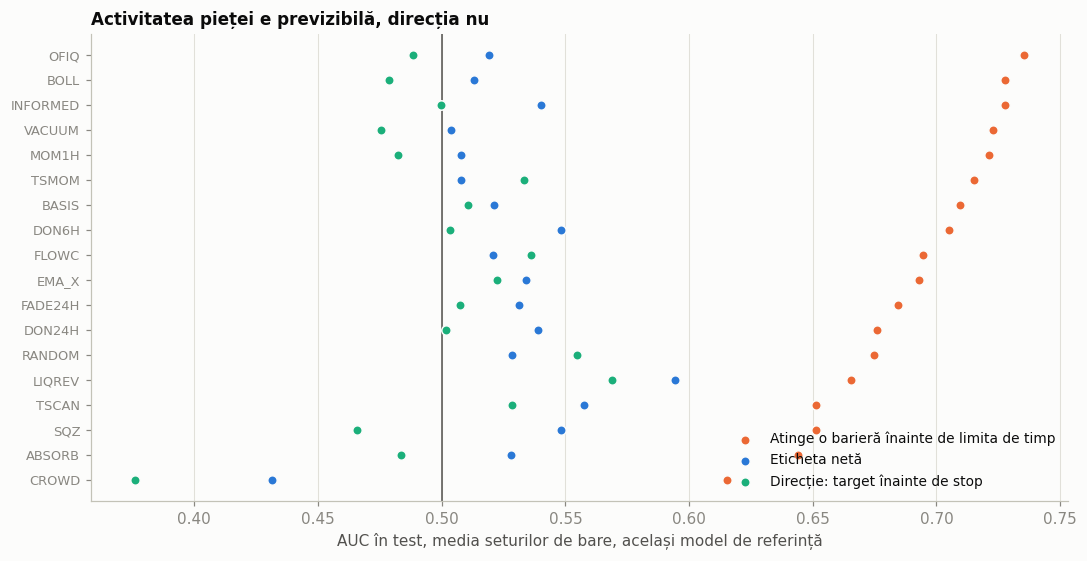

In [21]:
DEC = pd.DataFrame({k: {f: np.nanmean([EVAL[(k, b)]["dec"][f] for b in ALL_BARS if (k, b) in EVAL]) for f in ["net", "gross", "barrier", "barrier_vol", "dir", "net_on_barrier", "net_on_dir", "barrier_share"]} for k in SN}).T
for lab, fld in (("dir", "b_dir"), ("barrier", "b_bar")):
    bb = {k: np.nanmean(np.stack([EVAL[(k, b)][fld] for b in ALL_BARS if (k, b) in EVAL]), axis=0) for k in SN}
    DEC[lab + "_lo"] = [np.nanquantile(bb[k], .025) for k in SN]; DEC[lab + "_hi"] = [np.nanquantile(bb[k], .975) for k in SN]
    if lab == "dir":
        DEC["dir_p"] = [np.mean(bb[k] <= .5) for k in SN]
display(DEC.round(3))
mreal = DEC.index.isin(real)
DEC_q = multipletests(np.maximum(DEC.loc[mreal, "dir_p"], 1 / 300), method="fdr_bh")[1]
print(f"Direction AUC above 0.5 at BH q<0.05: {list(DEC.index[mreal][DEC_q < .05])}.")
print(f"Means over real strategies. Net {DEC.loc[mreal, 'net'].mean():.3f}, gross {DEC.loc[mreal, 'gross'].mean():.3f}, barrier {DEC.loc[mreal, 'barrier'].mean():.3f}, barrier with vol and activity only {DEC.loc[mreal, 'barrier_vol'].mean():.3f}, direction {DEC.loc[mreal, 'dir'].mean():.3f}.")

fig, ax = plt.subplots(figsize=(10, 5.2))
Ds = DEC.sort_values("barrier"); yy = np.arange(len(Ds))
ax.axvline(.5, color=INK2, lw=1)
for f, cc, lab in (("barrier", C["orange"], "Atinge o barieră înainte de limita de timp"), ("net", C["blue"], "Eticheta netă"), ("dir", C["aqua"], "Direcție: target înainte de stop")):
    ax.scatter(Ds[f], yy, s=38, color=cc, label=lab, edgecolor=SURFACE, zorder=3)
ax.set_yticks(yy); ax.set_yticklabels(Ds.index, fontsize=8.5); ax.grid(axis="y", visible=False)
ax.set_xlabel("AUC în test, media seturilor de bare, același model de referință"); ax.set_title("Activitatea pieței e previzibilă, direcția nu"); ax.legend(loc="lower right")
fig.tight_layout(); plt.show()

**Interpretare. Acesta e rezultatul central al notebook-ului.**

* **Modelul știe bine dacă piața se mișcă.** AUC 0.691 pentru "atinge o barieră". Doar volatilitatea și activitatea ajung la 0.661.
* **Modelul nu știe în ce parte.** AUC 0.498 pe direcție, media celor 17 reguli. Nicio regulă nu trece corecția, deși `LIQREV` e cel mai aproape (0.569, p necorectat 0.01).
* **Eticheta netă e undeva între ele** (0.526), fiindcă e un amestec. Costul transformă o parte din predictibilitatea volatilității în aparentă predictibilitate a câștigului: tranzacțiile care ies pe timp pierd comisionul, iar cele care ating bariera nu.
* **Scorul modelului pe eticheta netă e, de fapt, un scor de volatilitate.** Corelează cu atingerea barierei (coloana `net_on_barrier`, de exemplu 0.620 pe `OFIQ`, 0.601 pe `DON6H`) și nu cu direcția (`net_on_dir` în jur de 0.50).
* **`LIQREV` e singura excepție clară:** `net_on_barrier` e 0.443 și `net_on_dir` 0.575. Acolo eticheta netă chiar urmărește direcția.

### Prezice modelul bani sau doar câștiguri mai dese? `POST-HOC`

Tabelul de calibrare din secțiunea 16 mi-a ridicat întrebarea: pe decile de probabilitate, rata de câștig crește, dar netul stă pe loc. Aici verific direct, cu scorul modelului de referință pe evenimentele de test.

,win_rate,barrier_hit,width_bps,gross,net,gross_in_barriers
dec,,,,,,
0,0.371,0.476,61.041,-2.651,-12.646,-0.044
1,0.400,0.514,62.105,-2.043,-12.040,-0.030
2,0.404,0.525,63.989,-2.658,-12.658,-0.041
3,0.412,0.528,64.836,-2.228,-12.226,-0.031
4,0.421,0.547,65.872,-2.108,-12.104,-0.029
5,0.429,0.571,67.645,-0.966,-10.963,-0.019
6,0.438,0.584,69.155,-1.265,-11.257,-0.015
7,0.434,0.596,71.028,-1.742,-11.735,-0.027
8,0.445,0.620,72.785,-1.245,-11.240,-0.021


,win rate top - bottom,gross top - bottom (bps),width top / bottom,rank IC score vs gross/width
strategy,,,,
ABSORB,0.029,-1.763,1.433,0.002
BASIS,0.035,0.082,1.173,-0.009
BOLL,0.012,-1.170,1.236,-0.025
CROWD,-0.100,-15.513,1.115,-0.147
DON24H,0.058,10.386,0.956,0.035
DON6H,0.073,3.519,0.999,0.009
EMA_X,0.045,2.362,0.965,0.011
FADE24H,0.037,6.047,1.129,0.044
FLOWC,0.028,2.764,0.980,0.049


Score vs gross per trade, real rules: mean rank IC +0.001; 10 of 17 rules have a better gross in the top half.


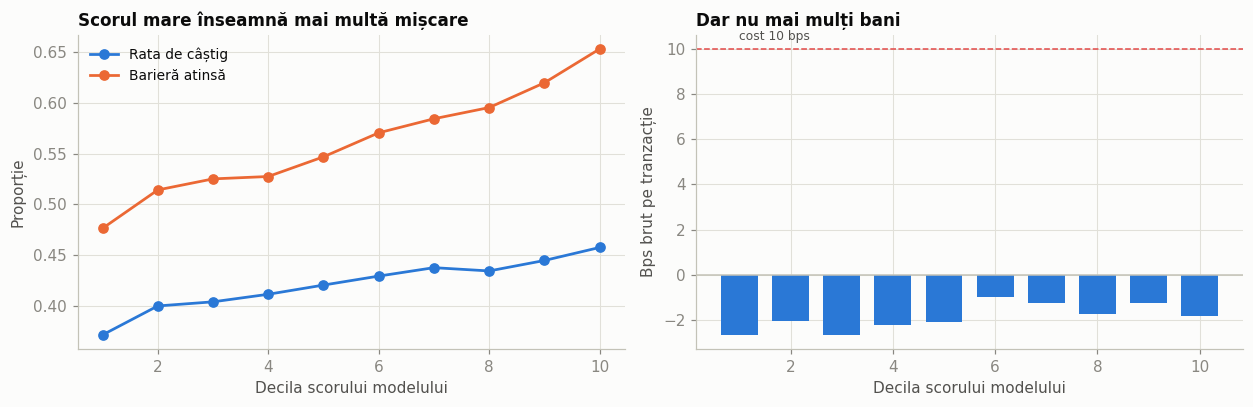

In [22]:
def money_rows(key):
    v = EXP[key]; E = CELLS[key]["E"]; te = v["te"]
    return pd.DataFrame({"strategy": key[0], "bars": key[1], "s": v["ref"], "y": E["y"].to_numpy()[te], "gross": E["gross_bps"].to_numpy()[te], "net": E["net_bps"].to_numpy()[te],
                         "width": 1e4 * E["width"].to_numpy()[te], "barrier": (E["reason"].to_numpy()[te] != EXIT_TIME).astype(float), "gw": (E["gross_bps"] / (1e4 * E["width"])).to_numpy()[te]})
MON = pd.concat([money_rows(k) for k in EVAL])
MON["dec"] = MON.groupby(["strategy", "bars"], observed=True)["s"].transform(lambda x: pd.qcut(x.rank(method="first"), 10, labels=False))
REALM = MON[MON["strategy"].isin(real)]
DECM = REALM.groupby("dec").agg(win_rate=("y", "mean"), barrier_hit=("barrier", "mean"), width_bps=("width", "median"), gross=("gross", "mean"), net=("net", "mean"), gross_in_barriers=("gw", "mean"))
display(DECM.round(3))
tops = REALM.assign(top=REALM["dec"] >= 5).groupby(["strategy", "top"], observed=True)[["y", "gross", "net", "width"]].mean().unstack()
MONEY = pd.DataFrame({"win rate top - bottom": tops["y"][True] - tops["y"][False], "gross top - bottom (bps)": tops["gross"][True] - tops["gross"][False], "width top / bottom": tops["width"][True] / tops["width"][False]})
MONEY["rank IC score vs gross/width"] = REALM.groupby(["strategy", "bars"], observed=True).apply(lambda g_: stats.spearmanr(g_["s"], g_["gw"])[0]).groupby(level=0, observed=True).mean()
display(MONEY.round(3))
print(f"Score vs gross per trade, real rules: mean rank IC {MONEY['rank IC score vs gross/width'].mean():+.3f}; {int((MONEY['gross top - bottom (bps)'] > 0).sum())} of {len(MONEY)} rules have a better gross in the top half.")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
ax = axes[0]
ax.plot(DECM.index + 1, DECM["win_rate"], marker="o", color=C["blue"], label="Rata de câștig")
ax.plot(DECM.index + 1, DECM["barrier_hit"], marker="o", color=C["orange"], label="Barieră atinsă")
ax.set_xlabel("Decila scorului modelului"); ax.set_ylabel("Proporție"); ax.set_title("Scorul mare înseamnă mai multă mișcare"); ax.legend()
ax = axes[1]
ax.axhline(0, color=AXIS, lw=1); ax.bar(DECM.index + 1, DECM["gross"], color=C["blue"], width=.72, label="Brut")
ax.axhline(COST_RT_BPS, color=C["red"], lw=1, ls="--"); ax.text(1, COST_RT_BPS + .4, "cost 10 bps", fontsize=8, color=INK2)
ax.set_xlabel("Decila scorului modelului"); ax.set_ylabel("Bps brut pe tranzacție"); ax.set_title("Dar nu mai mulți bani")
fig.tight_layout(); plt.show()

**Interpretare.**

* **Rata de câștig crește de la 37% la 46% între decile, iar brutul rămâne aproape plat**, între −2.7 și −1.0 bps, și netul stă în jur de −12 bps. Corelația medie dintre scor și rezultatul brut e +0.001.
* **Motivul:** un scor mare înseamnă mai multe atingeri de barieră (48% → 65%) și bariere mai late (61 → 77 bps). Câștigurile sunt mai frecvente, dar și pierderile. Tranzacțiile care ar fi ieșit pe timp cu o pierdere mică devin un câștig sau un stop, cu medie apropiată de zero.
* **Consecința practică:** AUC-ul și neg log loss-ul pe eticheta `net > 0` sunt metrici înșelătoare aici. Pot arăta îmbunătățire fără niciun profit. Un model care prezice volatilitatea e util pentru mărimea poziției, nu pentru a alege tranzacții.

### De ce are `RANDOM` AUC direcțional? `POST-HOC`

La intrări aleatoare, AUC-ul pe direcție (0.555) nu ar trebui să existe, dacă direcția nu e previzibilă. Verific dacă vine doar din `side`, adică din sensul general al pieței.

In [23]:
rows = []
for bar in ALL_BARS:
    c = CELLS[("RANDOM", bar)]; E = c["E"]; X = c["X"].astype(np.float64)
    r_ = E["reason"].to_numpy(); yd = (r_ == EXIT_PT).astype(int)
    sc, te_ = [], []
    for b, tr, te, w, um in windows(E):
        m = r_[tr] != EXIT_TIME
        sc.append(fit_predict(dict(kind="logit", C=1.0), X[tr][m][:, [FIDX["side"]]], yd[tr][m], w[m], X[te][:, [FIDX["side"]]])); te_.append(te)
    sc = np.concatenate(sc); te_ = np.concatenate(te_); be = r_[te_] != EXIT_TIME
    rows.append(dict(bars=bar, side_only=auc(sc[be], yd[te_][be]), full=auc(EXP[("RANDOM", bar)]["s_dir"][be], yd[te_][be])))
RD = pd.DataFrame(rows).set_index("bars"); display(RD.round(3))
def block_ret(a, b):
    i0, i1 = int(a.timestamp()) - SEC0, int(b.timestamp()) - SEC0
    p0 = CL[i0:i0 + 600][CL[i0:i0 + 600] > 0][0]; p1 = CL[i1 - 600:i1][CL[i1 - 600:i1] > 0][-1]
    return 100 * (p1 / p0 - 1)
print("BTC return before and inside the blocks (%):", {"dev": round(block_ret(TRAIN_START, FIRST_TEST), 1), **{f"{a:%b}-{(b - pd.Timedelta(days=1)):%b}": round(block_ret(a, b), 1) for a, b in BLOCKS}})
print(f"Side alone explains {100 * (RD['side_only'].mean() - .5) / (RD['full'].mean() - .5):.0f}% of the excess direction AUC on RANDOM.")

,side_only,full
bars,,
time_1m,0.486,0.552
time_5m,0.504,0.543
volume_50btc,0.499,0.578
volume_adapt60s,0.512,0.558
dollar_5musdt,0.497,0.555
dollar_adapt60s,0.506,0.552
cusum_5bps,0.507,0.550
cusum_10bps,0.505,0.531
cusum_adapt_c1,0.482,0.573


BTC return before and inside the blocks (%): {'dev': np.float64(-32.9), 'Feb-Apr': np.float64(-3.1), 'May-Jul': np.float64(-17.6), 'Aug-Oct': np.float64(23.3)}
Side alone explains -0% of the excess direction AUC on RANDOM.


In [24]:
# Is the RANDOM direction result a property of the market or of one draw? New random draws, same pipeline, two bar sets.
def random_seed_dir(job):
    seed, bar = job
    r = np.random.default_rng(seed)
    tt = np.sort(r.integers(TRAIN_START.value, DATA_END.value, 6 * _days)); sd = r.choice([-1, 1], tt.size)
    t = BAR_T[bar]
    pos = np.searchsorted(t, tt, side="left"); ok = pos < t.size
    pos, sd = pos[ok], sd[ok]
    pos, first = np.unique(pos, return_index=True); sd = sd[first]
    tcol = load_bars(bar, ["decision_time_ns", "t_start_ns", "eval_time_ns"])
    E = label_events(pos, sd, tcol["decision_time_ns"].to_numpy()[pos], tcol["t_start_ns"].to_numpy()[pos], tcol["eval_time_ns"].to_numpy()[pos], HORIZON_S["RANDOM"], np.zeros(pos.size))
    E["dur_norm"] = np.nan
    Rr = read_rows(bar, pos)
    F = candidate_features(E, Rr)
    cell = pack_cell(E, F, eligibility(E, Rr, F, HORIZON_S["RANDOM"]), HORIZON_S["RANDOM"])
    Ec = cell["E"]; X = cell["X"].astype(np.float64); r_ = Ec["reason"].to_numpy(); yd = (r_ == EXIT_PT).astype(int)
    sc, te_, blk = [], [], []
    for b, tr, te, w, um in windows(Ec):
        m = r_[tr] != EXIT_TIME
        sc.append(ref_score(X[tr][m], yd[tr][m], w[m], X[te])); te_.append(te); blk.append(np.full(te.size, b))
    sc, te_, blk = map(np.concatenate, (sc, te_, blk))
    be = r_[te_] != EXIT_TIME
    return dict(seed=seed, bars=bar, dir_auc=auc(sc[be], yd[te_][be]), **{f"block{b}": auc(sc[be & (blk == b)], yd[te_][be & (blk == b)]) for b in range(len(BLOCKS))})

N_RS = 2 if DRY_RUN else 10
RSEEDS = pd.DataFrame(cached("random_seeds", lambda: pmap(random_seed_dir, [(SEED + 100 + i, b) for i in range(N_RS) for b in ("time_1m", "volume_adapt60s")], workers=5)))
display(RSEEDS.groupby("bars")[["dir_auc"] + [f"block{b}" for b in range(len(BLOCKS))]].agg(["mean", "std"]).round(3))
print(f"Direction AUC on {len(RSEEDS)} new random draws: mean {RSEEDS['dir_auc'].mean():.3f}, range {RSEEDS['dir_auc'].min():.3f} to {RSEEDS['dir_auc'].max():.3f}; the original draw had {DEC.loc['RANDOM', 'dir']:.3f}.")

dir_auc        block0        block1        block2       
                   mean    std   mean    std   mean    std   mean    std
bars                                                                    
time_1m           0.519  0.026  0.536  0.034  0.514  0.067  0.518  0.036
volume_adapt60s   0.512  0.024  0.520  0.024  0.507  0.053  0.513  0.041

Direction AUC on 20 new random draws: mean 0.516, range 0.475 to 0.561; the original draw had 0.555.


**Interpretare.**

* **`side` nu explică rezultatul.** Singur dă 0.50, chiar dacă BTC a scăzut 33% în dezvoltare și a urcat 23% în ultimul bloc.
* **Valoarea 0.555 a fost în mare parte noroc.** Pe 20 de extrageri noi, media e 0.516 și intervalul 0.475–0.561, cu o deviație standard de 0.025. Prima extragere e aproape de maxim.
* **Rămâne poate o urmă de predictibilitate a direcției pe 4 ore** (0.516), dar extragerile folosesc aceeași piață, deci nu sunt independente. Nu aș construi nimic pe ea.
* **Lecția pentru restul notebook-ului:** o diferență de AUC de 0.02–0.03 pe un singur set de evenimente e zgomot obișnuit.

### Excepțiile: `LIQREV`, `DON6H` și `CROWD` `POST-HOC`

Trei strategii ies din tipar. Le privesc separat pe chintile, pe evenimentele de test din toate seturile de bare. Toate rândurile unei strategii sunt aproape aceleași tranzacții văzute pe ceasuri diferite, deci N-ul real e cel dintr-un singur set.

In [25]:
for k, f in [("LIQREV", "lrv_24h"), ("LIQREV", "s_z_ret_1h"), ("DON6H", "lrv_24h"), ("CROWD", "s_funding_bps"), ("CROWD", "lrv_24h")]:
    print(f"{k} by quintile of {f}:"); display(decile_view(k, f).round(3))
print("Top test features by rule (gross/width IC) for the three exceptions:")
for k in ("LIQREV", "DON6H", "CROWD"):
    t = TOPIC.loc[k].head(6)
    print(k, t[["ic_test", "ic_train"]].round(3).to_dict("index"))
CR = pd.DataFrame({b: {k: (MAIN[("CROWD", b)]["blocks"][i].get("base_rate_train", np.nan)) for i, k in enumerate(["train to Feb", "train to May", "train to Aug"])} for b in ALL_BARS}).mean(axis=1)
print("CROWD training win rate before each block:", CR.round(3).to_dict(), "| test win rate", round(R[R["strategy"] == "CROWD"]["base_test"].mean(), 3))
print("CROWD long share in training and test:", round(float(np.mean([(CELLS[("CROWD", b)]["E"]["side"][CELLS[("CROWD", b)]["E"]["t0"] < FIRST_TEST] > 0).mean() for b in ALL_BARS])), 3), round(float(np.mean([(CELLS[("CROWD", b)]["E"]["side"][CELLS[("CROWD", b)]["E"]["t0"] >= FIRST_TEST] > 0).mean() for b in ALL_BARS])), 3))

LIQREV by quintile of lrv_24h:


,net,gross,y,barrier
bin,,,,
0,-19.290,-9.268,0.383,0.895
1,-10.748,-0.758,0.520,0.755
2,-17.354,-7.367,0.402,0.730
3,-3.801,6.203,0.522,0.729
4,-13.997,-4.065,0.500,0.681


LIQREV by quintile of s_z_ret_1h:


,net,gross,y,barrier
bin,,,,
0.0,-9.617,0.386,0.443,0.899
1.0,-4.453,5.509,0.480,0.767
2.0,-10.142,-0.162,0.512,0.731
3.0,-23.678,-13.714,0.396,0.760
4.0,-17.983,-7.958,0.486,0.648


DON6H by quintile of lrv_24h:


,net,gross,y,barrier
bin,,,,
0,-9.975,0.043,0.419,0.678
1,-10.810,-0.774,0.420,0.555
2,-17.400,-7.342,0.370,0.559
3,-20.536,-10.526,0.368,0.495
4,-10.934,-0.937,0.436,0.535


CROWD by quintile of s_funding_bps:


,net,gross,y,barrier
bin,,,,
0,-16.002,-6.627,0.458,0.527
1,-3.887,5.711,0.471,0.544
2,-17.849,-8.117,0.484,0.563
3,-17.724,-7.827,0.404,0.550
4,-20.699,-10.567,0.480,0.523


CROWD by quintile of lrv_24h:


,net,gross,y,barrier
bin,,,,
0,-14.908,-5.055,0.473,0.680
1,-7.057,2.675,0.462,0.544
2,-9.485,0.206,0.513,0.490
3,-31.985,-22.304,0.360,0.444
4,-12.765,-2.992,0.488,0.547


Top test features by rule (gross/width IC) for the three exceptions:
LIQREV {'recent_hit_20': {'ic_test': -0.125, 'ic_train': -0.056}, 'lrv_1h': {'ic_test': 0.121, 'ic_train': 0.007}, 'jump_share_1h': {'ic_test': -0.111, 'ic_train': -0.002}, 'z_max_ret_15m': {'ic_test': -0.11, 'ic_train': -0.098}, 'large_share_15m': {'ic_test': -0.105, 'ic_train': -0.117}, 'lrv_4h': {'ic_test': 0.104, 'ic_train': 0.079}}
DON6H {'side': {'ic_test': 0.061, 'ic_train': 0.058}, 'hour_cos': {'ic_test': -0.048, 'ic_train': 0.0}, 's_basis_bps': {'ic_test': -0.048, 'ic_train': -0.042}, 'l_events_24h': {'ic_test': -0.048, 'ic_train': -0.012}, 'oi_chg_4h': {'ic_test': 0.043, 'ic_train': -0.012}, 'oi_chg_1h': {'ic_test': 0.042, 'ic_train': -0.004}}
CROWD {'s_large_flow_15m': {'ic_test': -0.184, 'ic_train': 0.126}, 's_tfi_ratio_15m': {'ic_test': -0.179, 'ic_train': 0.11}, 's_z_vwap_15m': {'ic_test': -0.169, 'ic_train': 0.18}, 's_ofi_15m': {'ic_test': -0.161, 'ic_train': -0.051}, 's_path_eff_15m': {'ic_test': -0.13

**Interpretare.**

* **`LIQREV` nu are o poveste simplă de volatilitate.** Pe chintile de `lrv_24h`, rezultatul brut nu e monoton. Pe chintile de `s_z_ret_1h` apare ceva mai clar: lichidările care vin după o mișcare mare împotriva poziției se întorc (brut +0.4 și +5.5 bps), iar cele după o mișcare mică nu (−13.7 și −8.0). Economic are sens: doar o capitulare reală are ce să inverseze. Fiind găsit post-hoc, pe 262 de evenimente, e o ipoteză.
* **`DON6H` e cazul tipic.** Are AUC 0.556 cu N mare, iar cea mai puternică familie e `CALENDAR` (0.573). Breakout-urile din orele active ating bariera, dar direcția e la 0.503. Lățimea barierei nu diferă între jumătăți, deci vine din momentul zilei, nu din nivelul volatilității.
* **`CROWD` e un eșec al modelului.** Features au semn inversat între antrenament și test: `s_large_flow_15m` +0.126 → −0.184, `s_z_vwap_15m` +0.180 → −0.169. Modelul învață pe aproximativ 125 de evenimente efective, în primul bloc, o relație care se inversează, iar un feature injectat cu AUC 0.60 nu îl salvează (0.464). Verdictul `NO USEFUL SIGNAL` trebuie citit "nu se poate măsura la acest N", nu "nu există semnal". Aceasta e exact capcana din secțiunea 2.6.

## 14. `Edge` sau număr de semnale? `EXPLORATORY`

### 14.1 Regresie pe celule

Variabila dependentă e AUC-ul modelului de referință minus 0.5. Erorile sunt clusterizate pe strategie, fiindcă cele 9 seturi ale unei strategii sunt aproape aceleași date.

In [26]:
def cell_reg(dep, data, cols):
    Xd = sm.add_constant(data[cols].astype(float))
    return sm.OLS(data[dep].astype(float), Xd).fit(cov_type="cluster", cov_kwds={"groups": data["strategy"].cat.codes})

RR = R[R["strategy"].isin(real)].copy()
RR["auc_c"] = RR["auc_ref"] - .5
RR["log_neff"] = np.log(RR["neff_train"]); RR["log_ntest"] = np.log(RR["n_test"])
RR["edge10"] = RR["gross_train"] / 10; RR["edge_test10"] = RR["gross_test"] / 10
RR["abs_edge10"] = RR["edge_test10"].abs()
RR["cost_ratio"] = [COST_RT_BPS / (1e4 * np.nanmedian(CELLS[(k, b)]["E"]["width"])) for k, b in zip(RR["strategy"], RR["bars"])]
RR["base_gap"] = RR["base_test"] - .5
RR["uplift10"] = RR["uplift50"] / 10
specs = {"AUC on edge only": ("auc_c", ["edge_test10"]), "AUC on log N only": ("auc_c", ["log_neff"]), "AUC on both": ("auc_c", ["edge_test10", "log_neff"]), "AUC, full": ("auc_c", ["edge_test10", "edge10", "log_neff", "log_ntest", "cost_ratio"]),
         "Uplift on both": ("uplift10", ["edge_test10", "log_neff", "cost_ratio"])}
rows = {}
for n_, (dep, cols) in specs.items():
    f = cell_reg(dep, RR.dropna(subset=[dep] + cols), cols)
    rows[n_] = {**{c: f"{f.params[c]:+.4f} ({f.tvalues[c]:+.1f})" for c in cols}, "R2": f"{f.rsquared:.2f}", "cells": int(f.nobs)}
REG = pd.DataFrame(rows).T.fillna("")
display(REG)
S_ = RR.groupby("strategy", observed=True)[["auc_ref", "gross_test", "gross_train", "neff_train", "uplift50", "cost_ratio", "base_test"]].mean()
print("Across the 17 rules (Spearman):", {c: round(stats.spearmanr(S_["auc_ref"], S_[c])[0], 2) for c in ["gross_test", "gross_train", "neff_train", "cost_ratio", "base_test"]})

,edge_test10,R2,cells,log_neff,edge10,log_ntest,cost_ratio
AUC on edge only,+0.0407 (+1.5),0.08,152,,,,
AUC on log N only,,0.00,152,+0.0022 (+0.2),,,
AUC on both,+0.0404 (+1.6),0.08,152,+0.0010 (+0.1),,,
"AUC, full",+0.0308 (+2.2),0.23,152,-0.0659 (-1.2),+0.0225 (+1.0),+0.0666 (+1.3),+0.0894 (+0.9)
Uplift on both,+0.2705 (+0.9),0.03,152,+0.0257 (+0.3),,,+0.2914 (+0.2)


Across the 17 rules (Spearman): {'gross_test': np.float64(0.24), 'gross_train': np.float64(0.31), 'neff_train': np.float64(-0.22), 'cost_ratio': np.float64(0.01), 'base_test': np.float64(-0.04)}


**Interpretare.**

* **Log N nu explică AUC-ul între strategii** (+0.002 pe unitate, t 0.2).
* **`Edge`-ul din test are un coeficient pozitiv, dar slab:** +0.04 AUC la 10 bps de `edge`, t 1.6. Cu toate controalele ajunge la t 2.2, cu 17 clustere și `edge` măsurat pe același eșantion ca AUC-ul. Nu ar trebui citit ca efect cauzal.
* **R² mic (0.08).** `Edge`-ul și N-ul împreună lasă aproape toată variația neexplicată.
* **Uplift-ul economic nu depinde nici de `edge`, nici de N** (t sub 1).

### 14.2 N egalat și curbe de învățare

Antrenamentul e redus la același N efectiv pentru toate strategiile. Testul nu se schimbă, deci numai antrenamentul diferă. Dacă strategiile cu `edge` mai mare au AUC mai bun și la N egal, efectul e real.

,N eff train,edge test,Full,N=100,N=200,N=400,N=800,N=1600
strategy,,,,,,,,
RANDOM,1059.0,1.1,0.528,0.513,0.516,0.522,NaN,NaN
EMA_X,434.0,-4.3,0.534,0.512,0.522,NaN,NaN,NaN
DON6H,1502.0,-3.9,0.548,0.517,0.527,0.531,0.539,NaN
DON24H,443.0,-4.2,0.539,0.521,0.533,NaN,NaN,NaN
FADE24H,445.0,-1.7,0.531,0.520,0.525,NaN,NaN,NaN
TSMOM,1461.0,0.5,0.508,0.502,0.507,0.507,0.505,NaN
BOLL,489.0,-0.6,0.513,0.505,0.516,0.509,NaN,NaN
SQZ,332.0,2.0,0.548,0.527,0.535,NaN,NaN,NaN
TSCAN,286.0,3.8,0.558,0.545,0.556,NaN,NaN,NaN


N=100: 17 strategies, Spearman(AUC, test edge) = +0.26, p = 0.30; spread of AUC 0.118.
N=200: 15 strategies, Spearman(AUC, test edge) = +0.07, p = 0.80; spread of AUC 0.054.
N=400: 8 strategies, Spearman(AUC, test edge) = -0.60, p = 0.12; spread of AUC 0.024.
N=800: 6 strategies, Spearman(AUC, test edge) = -0.37, p = 0.47; spread of AUC 0.033.


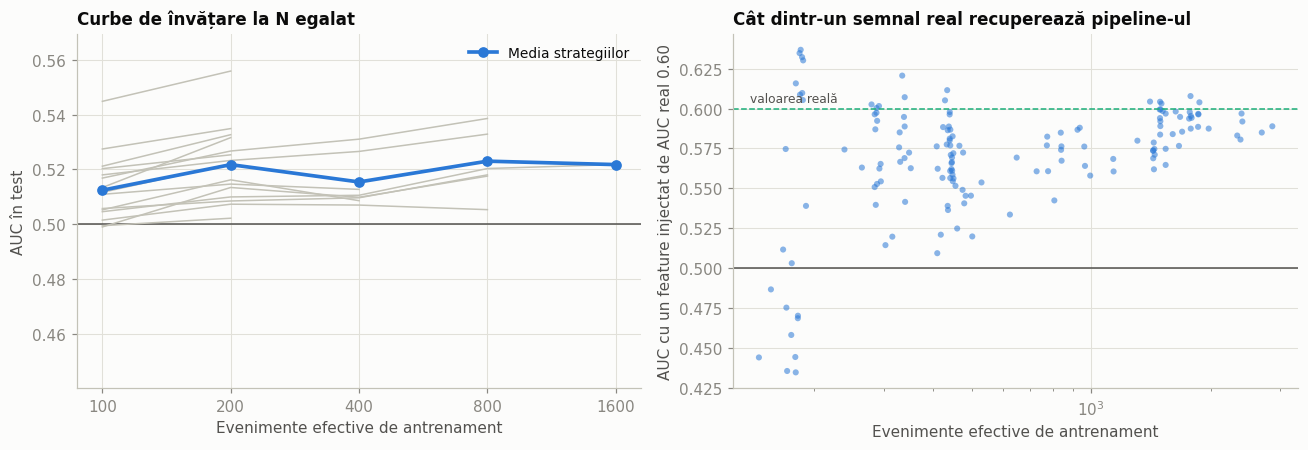

,cells,recovered_auc,real_auc,auc_se
bin,,,,
"(0.0, 150.0]",1,0.444,0.430,0.076
"(150.0, 300.0]",35,0.555,0.528,0.036
"(300.0, 600.0]",55,0.566,0.528,0.028
"(600.0, 1200.0]",18,0.568,0.514,0.021
"(1200.0, 100000.0]",43,0.588,0.529,0.014


In [27]:
mrows = []
for key, v in EVAL.items():
    for N, a in v["match"].items():
        mrows.append(dict(strategy=key[0], bars=key[1], N=N, auc=float(np.nanmean(a))))
    mrows.append(dict(strategy=key[0], bars=key[1], N=-1, auc=v["res"]["auc_ref"]))
MATCH = pd.DataFrame(mrows)
MS = MATCH.groupby(["strategy", "N"])["auc"].mean().unstack().reindex(SN)
MS.columns = ["Full" if c == -1 else f"N={c}" for c in MS.columns]
MS.insert(0, "N eff train", R.groupby("strategy", observed=True)["neff_train"].mean().reindex(SN).round(0))
MS.insert(1, "edge test", R.groupby("strategy", observed=True)["gross_test"].mean().reindex(SN).round(1))
display(MS.round(3))
for N in [c for c in MS.columns if c.startswith("N=")]:
    m = MS[N].dropna(); m = m[m.index.isin(real)]
    if len(m) >= 6:
        rho, pv = stats.spearmanr(m, MS.loc[m.index, "edge test"])
        print(f"{N}: {len(m)} strategies, Spearman(AUC, test edge) = {rho:+.2f}, p = {pv:.2f}; spread of AUC {m.max() - m.min():.3f}.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.axhline(.5, color=INK2, lw=1)
grid = sorted(n for n in MATCH["N"].unique() if n > 0)
for k in [k for k in SN if k in real]:
    m = MATCH[(MATCH["strategy"] == k) & (MATCH["N"] > 0)].groupby("N")["auc"].mean()
    ax.plot(m.index, m.to_numpy(), color=AXIS, lw=1)
m = MATCH[(MATCH["N"] > 0) & MATCH["strategy"].isin(real)].groupby("N")["auc"].mean()
ax.plot(m.index, m.to_numpy(), color=C["blue"], lw=2.4, marker="o", label="Media strategiilor")
ax.set_xscale("log"); ax.set_xticks(grid); ax.set_xticklabels(grid); ax.minorticks_off()
ax.set_xlabel("Evenimente efective de antrenament"); ax.set_ylabel("AUC în test"); ax.set_title("Curbe de învățare la N egalat"); ax.legend()
ax = axes[1]
g_ = R[R["strategy"].isin(real)]
ax.axhline(INJECT_AUC, color=C["aqua"], lw=1, ls="--"); ax.axhline(.5, color=INK2, lw=1)
ax.scatter(g_["neff_train"], g_["inject"], s=16, color=C["blue"], alpha=.55, edgecolor="none")
ax.set_xscale("log"); ax.set_xlabel("Evenimente efective de antrenament"); ax.set_ylabel("AUC cu un feature injectat de AUC real 0.60")
ax.text(ax.get_xlim()[0] * 1.1, INJECT_AUC + .004, "valoarea reală", fontsize=8, color=INK2)
ax.set_title("Cât dintr-un semnal real recuperează pipeline-ul")
fig.tight_layout(); plt.show()
INJ = g_.assign(bin=pd.cut(g_["neff_train"], [0, 150, 300, 600, 1200, 1e5])).groupby("bin", observed=True).agg(cells=("inject", "size"), recovered_auc=("inject", "mean"), real_auc=("auc_ref", "mean"), auc_se=("auc_se", "mean"))
display(INJ.round(3))

**Interpretare.**

* **La N egal, legătura cu `edge`-ul nu e stabilă.** Spearman +0.26, +0.07, −0.60, −0.37 la N = 100, 200, 400, 800, niciuna semnificativă. Dacă `edge`-ul ar ajuta modelul, semnul ar rămâne pozitiv.
* **Clasamentul se păstrează în mare la N egal.** `TSCAN` și `LIQREV` rămân sus, `TSMOM` și `MOM1H` jos, deci diferențele nu sunt doar un efect de N.
* **N limitează însă ce se poate vedea.** Un semnal real de 0.60 e recuperat la 0.555 sub 300 de evenimente efective și la 0.588 peste 1.200. Sub 300 pierzi aproape jumătate din semnal. De aceea cele 6 reguli `UNDERPOWERED` nu pot fi declarate fără semnal.
* **AUC-ul real nu urmează aceeași curbă** (0.528, 0.528, 0.514, 0.529 pe aceleași intervale). Dacă ar exista un semnal puternic blocat de N, regulile cu N mare l-ar fi arătat.
* **Extremele sunt la N mic.** Cel mai mare AUC (`LIQREV`) și cel mai mic (`CROWD`) au cele mai puține evenimente. E forma tipică de pâlnie a zgomotului, deci 0.575 al lui `LIQREV` e suspect exact din acest motiv, chiar dacă trece testul.

### 14.3 Oglinda: același N, `edge` opus

Pentru fiecare celulă inversez partea tranzacției și reconstruiesc eticheta. Momentele, N-ul și barierele rămân aceleași. Se schimbă doar direcția, deci și `edge`-ul.

,own,mirror,gross_own,gross_mirror,base_own,base_mirror,d_auc,d_edge
strategy,,,,,,,,
RANDOM,0.528,0.510,1.058,-2.998,0.441,0.432,0.019,4.057
EMA_X,0.534,0.528,-4.328,1.664,0.429,0.474,0.006,-5.992
DON6H,0.548,0.516,-3.933,0.554,0.403,0.482,0.032,-4.487
DON24H,0.539,0.531,-4.233,-1.662,0.456,0.476,0.008,-2.571
FADE24H,0.531,0.539,-1.662,-4.233,0.476,0.456,-0.007,2.571
TSMOM,0.508,0.519,0.549,-2.735,0.436,0.438,-0.011,3.284
BOLL,0.513,0.505,-0.582,-3.261,0.460,0.390,0.008,2.679
SQZ,0.548,0.499,1.997,-3.978,0.369,0.478,0.049,5.975
TSCAN,0.558,0.490,3.758,-5.581,0.447,0.411,0.067,9.339


Correlation of own and mirror AUC across rules: 0.70. Mean difference +0.0114. Spearman(AUC difference, edge difference) = +0.31.


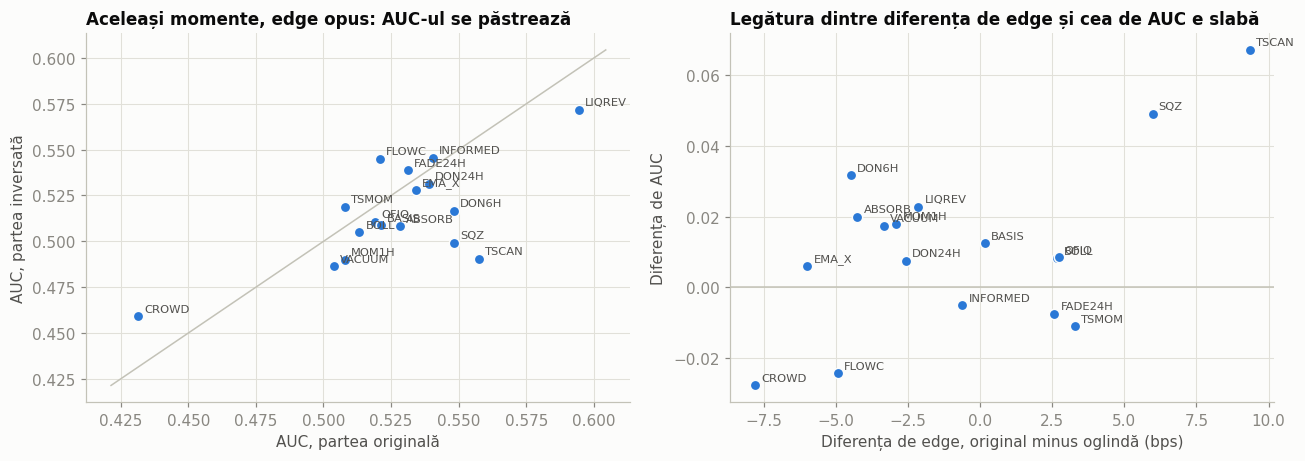

In [28]:
MIR = pd.DataFrame([dict(strategy=k, bars=b, own=v["mirror"]["auc_own"], mirror=v["mirror"]["auc"], base_mirror=v["mirror"]["base_test"], gross_mirror=v["mirror"]["gross_test"], gross_own=v["res"]["gross_test"], base_own=v["res"]["base_test"]) for (k, b), v in EVAL.items()])
MS2 = MIR.groupby("strategy")[["own", "mirror", "gross_own", "gross_mirror", "base_own", "base_mirror"]].mean().reindex(SN)
MS2["d_auc"] = MS2["own"] - MS2["mirror"]; MS2["d_edge"] = MS2["gross_own"] - MS2["gross_mirror"]
display(MS2.round(3))
mm = MS2[MS2.index.isin(real)]
print(f"Correlation of own and mirror AUC across rules: {stats.pearsonr(mm['own'], mm['mirror'])[0]:.2f}. Mean difference {mm['d_auc'].mean():+.4f}. Spearman(AUC difference, edge difference) = {stats.spearmanr(mm['d_auc'], mm['d_edge'])[0]:+.2f}.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axes[0]
lim = [min(mm["own"].min(), mm["mirror"].min()) - .01, max(mm["own"].max(), mm["mirror"].max()) + .01]
ax.plot(lim, lim, color=AXIS, lw=1)
ax.scatter(mm["own"], mm["mirror"], s=46, color=C["blue"], edgecolor=SURFACE, zorder=3)
for n_, a_, b_ in zip(mm.index, mm["own"], mm["mirror"]):
    ax.annotate(n_, (a_, b_), xytext=(4, 3), textcoords="offset points", fontsize=7.5, color=INK2)
ax.set_xlabel("AUC, partea originală"); ax.set_ylabel("AUC, partea inversată"); ax.set_title("Aceleași momente, edge opus: AUC-ul se păstrează")
ax = axes[1]
ax.axhline(0, color=AXIS, lw=1)
ax.scatter(mm["d_edge"], mm["d_auc"], s=46, color=C["blue"], edgecolor=SURFACE, zorder=3)
for n_, a_, b_ in zip(mm.index, mm["d_edge"], mm["d_auc"]):
    ax.annotate(n_, (a_, b_), xytext=(4, 3), textcoords="offset points", fontsize=7.5, color=INK2)
ax.set_xlabel("Diferența de edge, original minus oglindă (bps)"); ax.set_ylabel("Diferența de AUC"); ax.set_title("Legătura dintre diferența de edge și cea de AUC e slabă")
fig.tight_layout(); plt.show()

**Interpretare.**

* **Informația ține de momente, nu de `edge`.** Inversând partea, AUC-ul se păstrează în mare (corelație 0.70, diferență medie +0.011). Aceleași momente, același N, `edge` diferit, rezultat asemănător.
* **Asta explică și de ce modelul nu urmărește `edge`-ul:** ce prezice el e mișcarea, iar mișcarea e aceeași indiferent de partea pe care stai.
* **Regulile cu cea mai mare diferență pozitivă de `edge`** (`TSCAN` +9.3 bps, `SQZ` +6.0 bps) au și cea mai mare diferență de AUC (+0.067, +0.049). Legătura per total e slabă (Spearman +0.31, 17 reguli). Merită urmărită, nu trasă ca o concluzie.

*Notă tehnică.* În oglindă, coloanele `z_adverse_15m` și `z_favorable_15m` nu au fost interschimbate. Fiindcă inversarea se aplică tuturor evenimentelor, la antrenament și la test, modelul vede aceeași informație sub nume schimbate, deci AUC-ul nu e afectat. Notebook-ul următor (`btcusdt_v2_metalabeling_edge_experiment.ipynb`) calculează features separat pentru fiecare parte și verifică orientarea.

**Răspunsul pe scurt pentru `edge` și N.**

| Afirmație | Sprijinită? |
|---|---|
| Modelul secundar merge mai bine cu `edge` mai mare | Nu se vede. Doar un indiciu slab |
| Rezultatul slab vine din prea puține semnale | Parțial, doar la regulile rare. Regulile cu N mare au și ele AUC mic |
| `Edge`-ul și N-ul se confundă aici | Nu, sunt aproape necorelate |
| Se poate spune ce face modelul pe o primară cu `edge` real | **Nu.** Toate `edge`-urile din test sunt nedistingibile de zero sau negative |

Ultimul rând e cel mai important. Setul a fost construit cu `edge`-uri diverse, dar în test intervalul real e de la −5.5 la +3.8 bps, în mare zgomot. Studiul spune ce face modelul pe primare fără `edge`, nu cum se schimbă el odată ce există.

## 15. Cum afectează barele modelul secundar? `EXPLORATORY`

### 15.1 Tabloul general

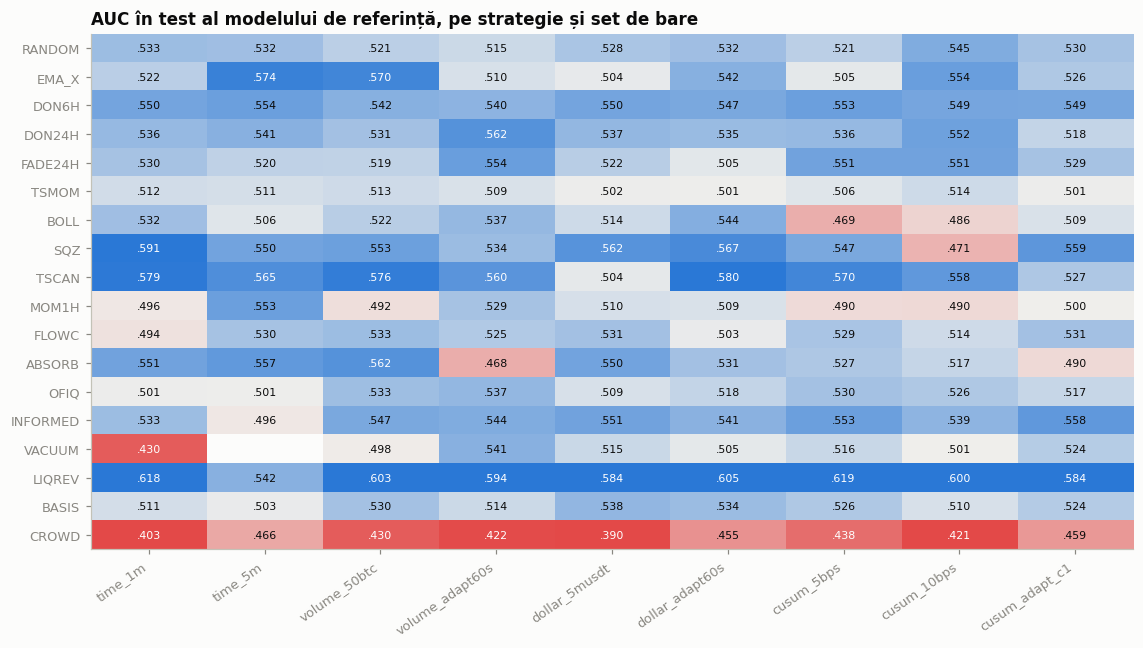

,type,bars_count,median_gap_s,n_test,neff_train,elig,edge_test,base_test,auc_ref,lo,hi,d_vs_base,d_lo,d_hi,auc_selected,skill,uplift,net_f50,net_all,improves
bars,,,,,,,,,,,,,,,,,,,,
time_1m,Time,672480,60.0,758.0,704.0,0.863,-2.3,0.419,0.523,0.507,0.540,0.000,0.000,0.000,0.517,0.0015,-0.7,-13.2,-12.7,1
time_5m,Time,134496,300.0,633.0,589.0,0.886,-1.3,0.421,0.529,0.515,0.545,0.006,-0.014,0.018,0.517,-0.0046,0.1,-11.0,-11.4,3
volume_50btc,Volume,1374524,14.4,936.0,843.0,0.852,-2.2,0.419,0.533,0.519,0.548,0.010,-0.004,0.025,0.521,-0.0010,-1.2,-12.9,-12.4,0
volume_adapt60s,Volume,1340966,14.9,922.0,837.0,0.851,-1.9,0.421,0.528,0.514,0.543,0.005,-0.008,0.020,0.527,-0.0010,0.1,-11.6,-12.2,1
dollar_5musdt,Dollar,1150745,17.7,893.0,836.0,0.850,-2.1,0.421,0.522,0.509,0.536,-0.001,-0.015,0.014,0.527,-0.0000,0.2,-11.4,-12.6,2
dollar_adapt60s,Dollar,1335074,15.0,927.0,840.0,0.851,-2.2,0.419,0.531,0.517,0.544,0.008,-0.007,0.023,0.518,-0.0005,-0.5,-12.9,-12.5,0
cusum_5bps,CUSUM,1454657,6.5,940.0,890.0,0.854,-2.2,0.425,0.527,0.513,0.542,0.004,-0.011,0.020,0.521,-0.0002,-0.3,-12.1,-12.6,0
cusum_10bps,CUSUM,445951,25.4,781.0,749.0,0.854,-1.9,0.430,0.521,0.508,0.534,-0.002,-0.016,0.012,0.524,-0.0002,2.2,-9.4,-12.4,0
cusum_adapt_c1,CUSUM,1112656,10.1,908.0,864.0,0.852,-2.1,0.425,0.524,0.510,0.539,0.001,-0.015,0.018,0.513,-0.0002,-0.6,-12.6,-12.3,1


,bar effect,t,bar effect given N,t given N
cusum_10bps,-0.0021,-0.1998,-0.0030,-0.3157
cusum_5bps,0.0044,0.4924,0.0013,0.2079
cusum_adapt_c1,0.0008,0.0824,-0.0020,-0.2411
dollar_5musdt,-0.0010,-0.1087,-0.0034,-0.4670
dollar_adapt60s,0.0077,1.1249,0.0053,0.9299
time_5m,0.0050,0.4451,0.0076,0.6705
volume_50btc,0.0098,1.3863,0.0072,1.3166
volume_adapt60s,0.0055,0.4903,0.0031,0.3214


log N eff coefficient within strategy: +0.0165 (t +1.8). Joint test of bar effects: p = 0.091.


In [29]:
HA = R.pivot(index="strategy", columns="bars", values="auc_ref").reindex(SN)[ALL_BARS]
fig, ax = plt.subplots(figsize=(10.5, 6))
Hm = HA - .5
ax.imshow(Hm.to_numpy(), cmap=DIV, norm=TwoSlopeNorm(0, -.08, .08), aspect="auto")
ax.set_xticks(range(len(ALL_BARS))); ax.set_xticklabels(ALL_BARS, rotation=35, ha="right", fontsize=8.5); ax.set_yticks(range(len(SN))); ax.set_yticklabels(SN, fontsize=8.5); ax.grid(False)
for i in range(Hm.shape[0]):
    for j in range(Hm.shape[1]):
        v = HA.iat[i, j]
        if np.isfinite(v):
            ax.text(j, i, f"{v:.3f}".lstrip("0"), ha="center", va="center", fontsize=7.2, color="white" if abs(v - .5) > .06 else INK)
ax.set_title("AUC în test al modelului de referință, pe strategie și set de bare"); fig.tight_layout(); plt.show()

rows = []
base = ALL_BARS[0]
for b in ALL_BARS:
    r = RR[RR["bars"] == b]
    arr = np.stack([EVAL[(k, b)]["b_ref"] for k in real if (k, b) in EVAL]).mean(0)
    arr0 = np.stack([EVAL[(k, base)]["b_ref"] for k in real if (k, b) in EVAL and (k, base) in EVAL]).mean(0)
    d = arr - arr0
    rows.append(dict(bars=b, type=BAR_TYPE[b], bars_count=int(BAR_STATS.loc[b, "bars"]), median_gap_s=BAR_STATS.loc[b, "median_gap_s"], n_test=r["n_test"].mean(), neff_train=r["neff_train"].mean(), elig=SAMPLE[SAMPLE["bars"] == b]["eligible_share"].mean(), edge_test=r["gross_test"].mean(), base_test=r["base_test"].mean(),
                     auc_ref=r["auc_ref"].mean(), lo=np.nanquantile(arr, .025), hi=np.nanquantile(arr, .975), d_vs_base=r["auc_ref"].mean() - RR[RR["bars"] == base]["auc_ref"].mean(), d_lo=np.nanquantile(d, .025), d_hi=np.nanquantile(d, .975),
                     auc_selected=r["auc"].mean(), skill=(r["neg_ll"] - r["neg_ll_base"]).mean(), uplift=r["uplift50"].mean(), net_f50=r["f50_net_trade"].mean(), net_all=r["u_net_trade"].mean(), improves=int((r["filter_verdict"] == "IMPROVES TRADE QUALITY").sum())))
BARS = pd.DataFrame(rows).set_index("bars")
display(BARS.round({"median_gap_s": 1, "n_test": 0, "neff_train": 0, "elig": 3, "edge_test": 1, "base_test": 3, "auc_ref": 3, "lo": 3, "hi": 3, "d_vs_base": 3, "d_lo": 3, "d_hi": 3, "auc_selected": 3, "skill": 4, "uplift": 1, "net_f50": 1, "net_all": 1}))

# Two-way fixed effects: the bar effect within strategy, with and without sample size.
D_ = pd.get_dummies(RR["bars"].astype(str), dtype=float).drop(columns=base)
St = pd.get_dummies(RR["strategy"].astype(str), dtype=float).iloc[:, 1:]
def fe(dep, add=()):
    Xd = sm.add_constant(pd.concat([D_, St] + [RR[[a]] for a in add], axis=1).astype(float))
    return sm.OLS(RR[dep].astype(float), Xd, missing="drop").fit(cov_type="cluster", cov_kwds={"groups": RR["strategy"].cat.codes})
f0, f1 = fe("auc_c"), fe("auc_c", ("log_neff",))
FE = pd.DataFrame({"bar effect": f0.params[D_.columns], "t": f0.tvalues[D_.columns], "bar effect given N": f1.params[D_.columns], "t given N": f1.tvalues[D_.columns]})
display(FE.round(4)); print(f"log N eff coefficient within strategy: {f1.params['log_neff']:+.4f} (t {f1.tvalues['log_neff']:+.1f}). Joint test of bar effects: p = {float(f0.f_test(np.eye(len(f0.params))[[list(f0.params.index).index(c) for c in D_.columns]]).pvalue):.3f}.")

**Interpretare.**

* **Nicio familie de bare nu e clar mai bună.** AUC-ul mediu stă între 0.521 și 0.533. Toate diferențele față de `time_1m` au intervale care includ zero.
* **Efectele fixe confirmă:** efecte de bară sub 0.01, test comun p = 0.091. Controlând pentru N, rămân la fel de mici.
* **Un N mai mare pe același ceas ajută puțin:** în cadrul aceleiași strategii, log N are +0.0165 (t 1.8). Este canalul principal prin care barele contează.
* **`Edge`-ul brut și rata de câștig sunt aproape identice pe seturi** (−1.3 la −2.3 bps), deci barele nu creează `edge`.

### 15.2 Barele schimbă mai mult unele strategii?

Variația AUC-ului și a numărului de evenimente pe seturi, pentru fiecare strategie, și AUC la N egal între bare.

In [30]:
TY = RR.groupby(["strategy", "bar_type"], observed=True).agg(auc=("auc_ref", "mean"), n=("n_test", "mean"), edge=("gross_test", "mean")).unstack()
SPREAD = pd.DataFrame({"AUC range over bars": HA.max(axis=1) - HA.min(axis=1), "mean SE of one cell": R.groupby("strategy", observed=True)["auc_se"].mean().reindex(SN),
                       "events max / min": (PIV_TEST.max(axis=1) / PIV_TEST.min(axis=1)).reindex(SN), "edge range (bps)": R.groupby("strategy", observed=True)["gross_test"].agg(lambda s: s.max() - s.min()).reindex(SN), "family": [STRATS[k][1] for k in SN]})
display(SPREAD.round(3))
display(TY["auc"].round(3)); display(TY["n"].round(0))
mN = MATCH[MATCH["N"] > 0].copy(); mN["type"] = mN["bars"].map(BAR_TYPE)
MB = mN[mN["strategy"].isin(real)].groupby(["N", "bars"])["auc"].mean().unstack()[ALL_BARS]
print("AUC at matched effective N, mean over the strategies available at that N:"); display(MB.round(3))

,AUC range over bars,mean SE of one cell,events max / min,edge range (bps),family
strategy,,,,,
RANDOM,0.030,0.016,1.034,1.708,control
EMA_X,0.070,0.027,1.036,1.794,trend
DON6H,0.014,0.015,1.137,2.462,trend
DON24H,0.045,0.026,1.078,6.305,trend
FADE24H,0.049,0.027,1.078,2.492,reversal
TSMOM,0.013,0.017,1.176,1.407,trend
BOLL,0.075,0.028,3.186,3.994,reversal
SQZ,0.120,0.035,1.096,3.820,trend
TSCAN,0.075,0.034,1.065,2.301,trend


bar_type,CUSUM,Dollar,Time,Volume
strategy,,,,
EMA_X,0.528,0.523,0.548,0.540
DON6H,0.550,0.548,0.552,0.541
DON24H,0.535,0.536,0.539,0.547
FADE24H,0.544,0.514,0.525,0.536
TSMOM,0.507,0.501,0.511,0.511
BOLL,0.488,0.529,0.519,0.529
SQZ,0.526,0.564,0.571,0.543
TSCAN,0.551,0.542,0.572,0.568
MOM1H,0.493,0.510,0.525,0.511


bar_type,CUSUM,Dollar,Time,Volume
strategy,,,,
EMA_X,452.0,446.0,451.0,446.0
DON6H,1690.0,1704.0,1840.0,1698.0
DON24H,430.0,430.0,444.0,425.0
FADE24H,430.0,430.0,444.0,425.0
TSMOM,1244.0,1289.0,1445.0,1300.0
BOLL,460.0,276.0,822.0,276.0
SQZ,325.0,342.0,328.0,344.0
TSCAN,278.0,288.0,292.0,288.0
MOM1H,434.0,460.0,298.0,466.0


AUC at matched effective N, mean over the strategies available at that N:


bars,time_1m,time_5m,volume_50btc,volume_adapt60s,dollar_5musdt,dollar_adapt60s,cusum_5bps,cusum_10bps,cusum_adapt_c1
N,,,,,,,,,
100,0.514,0.513,0.514,0.511,0.516,0.516,0.510,0.508,0.510
200,0.525,0.522,0.525,0.524,0.521,0.527,0.521,0.514,0.515
400,0.515,0.509,0.517,0.520,0.519,0.516,0.517,0.509,0.515
800,0.518,0.519,0.526,0.523,0.523,0.525,0.523,0.525,0.523
1600,NaN,NaN,0.533,0.533,0.509,0.519,0.523,NaN,0.514


### Variația între bare e mai mare decât zgomotul? `POST-HOC`

Intervalul AUC pe 9 valori crește natural cu eroarea standard: pentru 9 valori independente, intervalul așteptat e de aproximativ 3 erori standard. Compar, și verific dacă o celulă singură conduce media pe set.

In [31]:
SPREAD["range / SE"] = SPREAD["AUC range over bars"] / SPREAD["mean SE of one cell"]
print(f"Range / SE: median {SPREAD['range / SE'].median():.2f}, max {SPREAD['range / SE'].max():.2f} ({SPREAD['range / SE'].idxmax()}). About 3 is expected for 9 independent draws.")
display(R.pivot(index="strategy", columns="bars", values="uplift50").reindex(SN)[ALL_BARS].round(1))
print("Median uplift over rules by bar set (bps):", R[R["strategy"].isin(real)].groupby("bars", observed=True)["uplift50"].median().round(2).to_dict())

Range / SE: median 2.26, max 4.58 (VACUUM). About 3 is expected for 9 independent draws.


bars,time_1m,time_5m,volume_50btc,volume_adapt60s,dollar_5musdt,dollar_adapt60s,cusum_5bps,cusum_10bps,cusum_adapt_c1
strategy,,,,,,,,,
RANDOM,5.6,2.4,0.0,0.9,1.8,0.4,-0.4,-0.5,1.4
EMA_X,-4.0,5.4,-1.8,-0.4,2.7,2.8,0.1,1.0,1.2
DON6H,4.7,1.3,0.2,0.4,2.4,2.1,0.4,0.4,2.4
DON24H,5.6,2.6,1.2,0.7,1.5,3.1,6.2,2.3,1.6
FADE24H,4.0,-4.5,3.5,3.8,9.5,-1.5,0.8,7.7,-0.2
TSMOM,0.8,0.8,-0.8,0.1,0.3,0.3,2.8,1.1,1.9
BOLL,-2.9,-0.5,-1.8,-2.4,-2.6,1.0,-6.7,1.7,-3.5
SQZ,-8.2,-5.0,-2.5,-2.8,-4.8,-0.7,-4.4,-1.0,-3.3
TSCAN,-1.7,5.0,4.5,4.5,5.5,3.6,4.8,2.5,4.4


Median uplift over rules by bar set (bps): {'time_1m': -0.39, 'time_5m': 1.04, 'volume_50btc': -0.82, 'volume_adapt60s': 0.08, 'dollar_5musdt': 0.3, 'dollar_adapt60s': -0.16, 'cusum_5bps': 0.07, 'cusum_10bps': 1.06, 'cusum_adapt_c1': -0.21}


**Interpretare.**

* **Variația AUC între bare e de nivelul zgomotului.** Intervalul e în mediană 2.3 erori standard, sub cele 3 așteptate pentru 9 valori independente. Doar `VACUUM` iese în afară (4.6), din cauza celulei `time_1m`, care are 131 de evenimente și AUC 0.430. Celula `time_5m`, cu 28 de evenimente, n-a putut fi modelată.
* **Unde contează barele cu adevărat: numărul de evenimente.** La regulile de preț pe ceas lung raportul max/min e 1.03–1.18. La microstructură e de până la 54.
* **Două mecanisme diferite:**
  * **`OFIQ`, `VACUUM`, `FLOWC`:** caută stări scurte. Barele de eveniment eșantionează tocmai când se întâmplă ceva, deci le prind mai des. `time_5m` le ratează.
  * **`BOLL`:** efectul e invers, 873 de evenimente pe `time_1m` și 275 pe volume. Explicația probabilă, neverificată separat: pe volume bars, fereastra de 4 ore e dominată de rândurile din perioadele agitate, deci deviația standard crește și pragul de 3σ se atinge mai rar. Bara schimbă însăși statistica regulii.
* **La N egal, seturile de bare se apropie mult** (tabelul cu AUC la N egalat), deci efectul principal e numărul de evenimente, nu calitatea lor.
* **Media `cusum_10bps` de +2.2 bps uplift e un artefact** al unei singure celule (`CROWD`, +18.3 bps). Mediana pe reguli e aproape de zero pe toate seturile.

### 15.3 Experimentul factorial: momentul sau măsurătoarea?

Barele pot schimba modelul în două feluri: aleg **alte momente** de decizie sau dau **alte valori** de features la același moment. Le separ: evenimentele de pe un ceas, features citite as-of de pe altul. Familia `BAR` e scoasă din toate variantele, ca toate să aibă aceleași coloane.

In [32]:
F = pd.DataFrame([dict(strategy=f["job"][0], events=f["job"][1], features=f["job"][2], auc=f["auc"], n=f["n"]) for f in FACT])
F = F[F["strategy"].isin(real)]
TAB = F.groupby(["events", "features"])["auc"].mean().unstack().reindex(index=FB, columns=FB)
display(TAB.round(4))
ev_eff = F.groupby("events")["auc"].mean(); fx_eff = F.groupby("features")["auc"].mean()
print(f"Range of the event-clock effect {ev_eff.max() - ev_eff.min():.4f}; range of the feature-clock effect {fx_eff.max() - fx_eff.min():.4f}.")
Fw = F.pivot_table(index=["strategy", "events"], columns="features", values="auc")
print(f"Mean absolute change in a strategy's AUC when only the feature clock changes: {np.mean([np.abs(Fw[a] - Fw[b]).mean() for a in FB for b in FB if a < b]):.4f}.")
Fe = F.pivot_table(index=["strategy", "features"], columns="events", values="auc")
print(f"Mean absolute change when only the event clock changes: {np.mean([np.abs(Fe[a] - Fe[b]).mean() for a in FB for b in FB if a < b]):.4f}.")

BARF = pd.DataFrame({t: {f: np.nanmean([EVAL[(k, b)]["fam"][f]["lofo"] for k in real for b in ALL_BARS if BAR_TYPE[b] == t and (k, b) in EVAL]) for f in fams} for t in dict.fromkeys(BAR_TYPE[b] for b in ALL_BARS)})
BARA = pd.DataFrame({t: {f: np.nanmean([EVAL[(k, b)]["fam"][f]["alone"] for k in real for b in ALL_BARS if BAR_TYPE[b] == t and (k, b) in EVAL]) for f in fams} for t in dict.fromkeys(BAR_TYPE[b] for b in ALL_BARS)})
print("Mean family-alone AUC by bar type:"); display(BARA.round(3))
print("Mean unique value by bar type:"); display(BARF.round(4))

features,time_1m,volume_adapt60s,cusum_adapt_c1
events,,,
time_1m,0.5230,0.5207,0.5235
volume_adapt60s,0.5266,0.5292,0.5349
cusum_adapt_c1,0.5191,0.5197,0.5237


Range of the event-clock effect 0.0094; range of the feature-clock effect 0.0045.
Mean absolute change in a strategy's AUC when only the feature clock changes: 0.0126.
Mean absolute change when only the event clock changes: 0.0257.
Mean family-alone AUC by bar type:


,Time,Volume,Dollar,CUSUM
PRIMARY,0.503,0.510,0.504,0.512
PRICE,0.505,0.516,0.517,0.505
VOL,0.529,0.530,0.531,0.520
ACTIVITY,0.505,0.517,0.514,0.505
CALENDAR,0.520,0.531,0.527,0.520
FLOW,0.511,0.502,0.503,0.503
BOOK_STATE,0.493,0.501,0.508,0.506
BOOK_FLOW,0.511,0.526,0.521,0.514
DERIV,0.507,0.512,0.508,0.508
LIQ,0.502,0.507,0.509,0.503


Mean unique value by bar type:


,Time,Volume,Dollar,CUSUM
PRIMARY,0.0027,0.0003,0.0013,0.0020
PRICE,-0.0028,-0.0035,-0.0016,-0.0014
VOL,0.0045,0.0013,0.0018,-0.0002
ACTIVITY,-0.0010,-0.0016,-0.0014,-0.0004
CALENDAR,0.0053,0.0046,0.0040,0.0046
FLOW,0.0015,-0.0018,-0.0018,-0.0004
BOOK_STATE,-0.0014,-0.0010,0.0006,0.0018
BOOK_FLOW,0.0003,0.0040,0.0033,0.0012
DERIV,-0.0025,-0.0030,-0.0019,-0.0013
LIQ,-0.0005,-0.0023,-0.0022,-0.0014


**Interpretare.**

* **Barele schimbă mai mult momentul decât măsurătoarea.** Schimbând ceasul evenimentelor, AUC-ul unei strategii se mișcă în medie cu 0.026. Schimbând ceasul features, cu 0.013. Așa cum am anticipat.
* **Nu e surprinzător:** aproape toate features sunt ferestre de ceas, deci citite la același moment dau aproape același număr, indiferent de bară.
* **Niciun ceas nu câștigă clar.** Evenimentele pe volume au media cea mai mare (0.527–0.535), dar diferența e sub nivelul de zgomot de 0.02–0.03 stabilit în secțiunea 13.
* **Familia `BAR`** are AUC 0.498 pe time bars, unde nu are ce informație să ofere, și 0.507–0.514 pe barele de eveniment. Valoarea ei unică e zero, deci ce spune o bară se regăsește în ferestrele de ceas.
* **`BOOK_FLOW` pare mai util pe volume și dollar** (0.526 și 0.521) decât pe time (0.511). E plauzibil, dar nu e testat formal.

## 16. Controale și robustețe `EXPLORATORY`

,"AUC, economic pick","AUC, log-loss pick","skill, economic pick","skill, log-loss pick","AUC, reference"
strategy,,,,,
RANDOM,0.5238,0.4803,-0.0004,-0.0030,0.5285
EMA_X,0.5084,0.4923,-0.0035,-0.0060,0.5340
DON6H,0.5558,0.5584,0.0046,0.0052,0.5482
DON24H,0.5370,0.5022,0.0008,-0.0051,0.5388
FADE24H,0.5214,0.5161,-0.0004,-0.0018,0.5313
TSMOM,0.5152,0.5222,0.0000,0.0001,0.5078
BOLL,0.5135,0.5083,-0.0022,-0.0048,0.5132
SQZ,0.5101,0.5044,-0.0019,-0.0026,0.5483
TSCAN,0.5290,0.4699,-0.0052,-0.0163,0.5576


Means. AUC: economic 0.5208, log-loss 0.5116, reference 0.5265. Skill: economic -0.00064, log-loss -0.00374.
Spearman(CV Sharpe gain, test Sharpe gain) over cells: 0.674; Spearman(CV AUC, test AUC): 0.355.
CV AUC mean 0.512 against test AUC mean 0.521. Mean CV Sharpe of the pick -2.22 against -2.61 in test.


,Feb–Apr,May–Jul,Aug–Oct
strategy,,,
RANDOM,0.506,0.503,0.565
EMA_X,0.493,0.520,0.536
DON6H,0.523,0.552,0.594
DON24H,0.578,0.506,0.517
FADE24H,0.587,0.488,0.503
TSMOM,0.521,0.508,0.516
BOLL,0.518,0.474,0.552
SQZ,0.437,0.561,0.558
TSCAN,0.500,0.600,0.529


Mean percentile of the picked filter against a random filter of equal size: 0.55; of the 50% filter: 0.55. Cells with positive filtered net at 50% retention: 2 of 161; unfiltered: 0.
Significant family-alone cells (q<0.05): [('RANDOM', 'VOL', np.float64(0.542)), ('RANDOM', 'LIQ', np.float64(0.533)), ('DON6H', 'VOL', np.float64(0.556)), ('DON6H', 'ACTIVITY', np.float64(0.532)), ('DON6H', 'CALENDAR', np.float64(0.573)), ('DON6H', 'BOOK_FLOW', np.float64(0.539)), ('DON6H', 'DERIV', np.float64(0.527)), ('DON24H', 'PRIMARY', np.float64(0.578)), ('DON24H', 'CALENDAR', np.float64(0.556)), ('DON24H', 'BAR', np.float64(0.545)), ('FADE24H', 'PRIMARY', np.float64(0.59)), ('BOLL', 'VOL', np.float64(0.557)), ('FLOWC', 'PRIMARY', np.float64(0.539)), ('FLOWC', 'ACTIVITY', np.float64(0.547)), ('OFIQ', 'VOL', np.float64(0.529)), ('INFORMED', 'PRICE', np.float64(0.525)), ('INFORMED', 'VOL', np.float64(0.551)), ('INFORMED', 'FLOW', np.float64(0.533)), ('INFORMED', 'BOOK_FLOW', np.float64(0.545)), ('INFOR

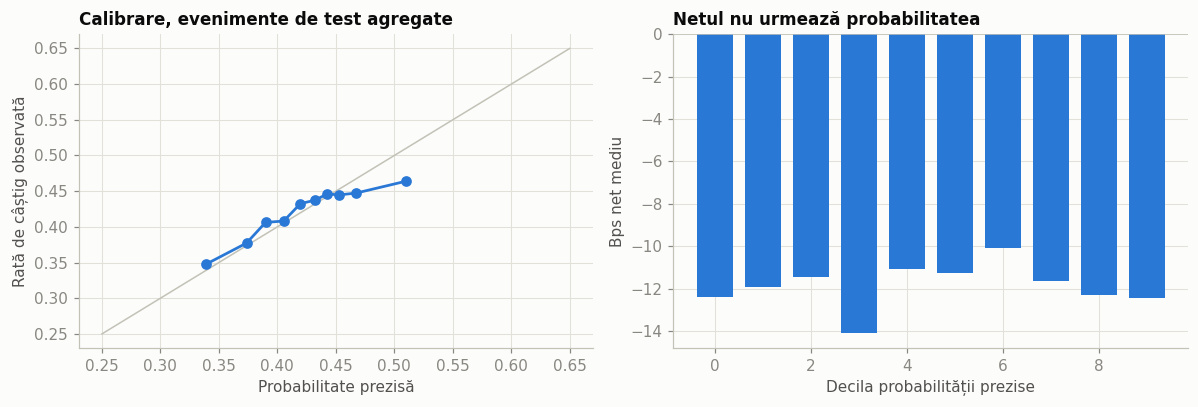

,p_mean,y_mean,net,n
bin,,,,
0,0.339,0.348,-12.393,13024
1,0.374,0.377,-11.900,13024
2,0.390,0.406,-11.455,13024
3,0.405,0.408,-14.095,13024
4,0.420,0.433,-11.090,13024
5,0.432,0.437,-11.265,13023
6,0.443,0.446,-10.097,13024
7,0.452,0.445,-11.649,13024
8,0.468,0.447,-12.291,13024


In [33]:
# Economic selection versus log-loss selection, same candidates.
ROB = pd.DataFrame({"AUC, economic pick": R.groupby("strategy", observed=True)["auc"].mean(), "AUC, log-loss pick": R.groupby("strategy", observed=True)["auc_ll"].mean(), "skill, economic pick": (R["neg_ll"] - R["neg_ll_base"]).groupby(R["strategy"], observed=True).mean(), "skill, log-loss pick": (R["neg_ll_llpick"] - R["neg_ll_base"]).groupby(R["strategy"], observed=True).mean(), "AUC, reference": R.groupby("strategy", observed=True)["auc_ref"].mean()})
display(ROB.round(4))
print(f"Means. AUC: economic {R['auc'].mean():.4f}, log-loss {R['auc_ll'].mean():.4f}, reference {R['auc_ref'].mean():.4f}. Skill: economic {(R['neg_ll'] - R['neg_ll_base']).mean():+.5f}, log-loss {(R['neg_ll_llpick'] - R['neg_ll_base']).mean():+.5f}.")

# Did the CV metric predict anything out of sample?
gain_cv = R["cv_econ"] - R["cv_unf"]; gain_te = R["fp_sharpe"] - R["u_sharpe"]
print(f"Spearman(CV Sharpe gain, test Sharpe gain) over cells: {stats.spearmanr(gain_cv, gain_te, nan_policy='omit')[0]:.3f}; Spearman(CV AUC, test AUC): {stats.spearmanr(R['cv_auc'], R['auc'], nan_policy='omit')[0]:.3f}.")
print(f"CV AUC mean {R['cv_auc'].mean():.3f} against test AUC mean {R['auc'].mean():.3f}. Mean CV Sharpe of the pick {R['cv_econ'].mean():.2f} against {R['fp_sharpe'].mean():.2f} in test.")

# Stability by block.
def block_auc(key):
    T = test_frame(key)
    return {b: auc(g_["s"].to_numpy(), g_["y"].to_numpy()) if g_["y"].nunique() > 1 else np.nan for b, g_ in T.groupby("block")}
BA = pd.DataFrame({k: block_auc(k) for k in EVAL}).T
BA.index.names = ["strategy", "bars"]
BS = BA.groupby(level=0).mean().reindex(SN)
BS.columns = [f"{BLOCKS[int(c)][0]:%b}–{(BLOCKS[int(c)][1] - pd.Timedelta(days=1)):%b}" for c in BS.columns]
display(BS.round(3))
print(f"Mean percentile of the picked filter against a random filter of equal size: {R['pct_vs_random_pick'].mean():.2f}; of the 50% filter: {R['pct_vs_random'].mean():.2f}. Cells with positive filtered net at 50% retention: {(R['f50_net_trade'] > 0).sum()} of {len(R)}; unfiltered: {(R['u_net_trade'] > 0).sum()}.")
print("Significant family-alone cells (q<0.05):", [(k, f, round(ALONE.loc[k, f], 3)) for k in SN for f in fams if Q_ALONE.loc[k, f] < .05 and ALONE.loc[k, f] > .5])
print(f"Rules above 0.5 in every block: {[k for k in BS.index if (BS.loc[k] > .5).all() and k in real]}.")

# Calibration on pooled test events of the real strategies.
frames = [test_frame(k)[["p", "y", "net_bps"]].assign(strategy=k[0]) for k in EVAL if k[0] in real]
PT = pd.concat(frames)
PT["bin"] = pd.qcut(PT["p"], 10, labels=False, duplicates="drop")
CAL = PT.groupby("bin").agg(p_mean=("p", "mean"), y_mean=("y", "mean"), net=("net_bps", "mean"), n=("y", "size"))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.plot([.25, .65], [.25, .65], color=AXIS, lw=1); ax.plot(CAL["p_mean"], CAL["y_mean"], marker="o", color=C["blue"])
ax.set_xlabel("Probabilitate prezisă"); ax.set_ylabel("Rată de câștig observată"); ax.set_title("Calibrare, evenimente de test agregate")
ax = axes[1]
ax.axhline(0, color=AXIS, lw=1); ax.bar(CAL.index, CAL["net"], color=C["blue"], width=.75)
ax.set_xlabel("Decila probabilității prezise"); ax.set_ylabel("Bps net mediu"); ax.set_title("Netul nu urmează probabilitatea")
fig.tight_layout(); plt.show()
display(CAL.round(3))

**Interpretare.**

* **Selecția economică a fost mai bună decât cea pe log loss** pe aceiași candidați: AUC 0.521 față de 0.512, skill −0.0006 față de −0.0037. Regula one-SE și preferința pentru simplitate ajută.
* **Dar tuning-ul n-a adus nimic față de un model fix.** Modelul de referință, fără nicio căutare, are AUC 0.527. Când semnalul e atât de slab, tuning-ul caută în zgomot.
* **CV-ul nu e optimist:** AUC de 0.512 în CV și 0.521 în test.
* **Corelația de 0.67 între câștigul de Sharpe din CV și din test nu e skill.** Regulile care pierd cel mai mult câștigă cel mai mult Sharpe prin reducerea expunerii, iar percentila față de filtrul aleator rămâne 0.55.
* **Stabilitate:** 9 reguli sunt peste 0.5 în toate cele trei blocuri, dar rezultatele pe bloc variază mult. `RANDOM` are 0.565 în ultimul bloc, deci o parte din el vine dintr-un singur regim.
* **Calibrarea e bună până la aproximativ 0.45**, apoi modelul e prea sigur: în decila de sus prezice 0.51 și realizează 0.46. Netul nu urmează probabilitatea în nicio decilă.

## 17. Concluzii `EXPLORATORY`

### Răspunsul direct

**Am descoperit informație pentru meta-labeling?** Da, dar nu cea dorită. Datele conțin informație robustă despre **cât se va mișca piața** și foarte puțină despre **în ce direcție**. Un model secundar pe eticheta `net > 0` învață volatilitatea, iar asta ridică rata de câștig fără să ridice profitul. Pe aceste reguli, la aceste costuri, meta-labeling-ul nu a creat valoare peste un filtru aleator.

| Întrebare | Concluzie | Încredere |
|---|---|---|
| Informație în date | Da pentru mișcare (AUC 0.69), nu pentru direcție (0.498) | Mare |
| Îmbunătățire AUC | Mică: 0.521 în medie, nedistinsă de intrări aleatoare | Mare |
| Îmbunătățire neg log loss | Aproape nulă, clară doar pe `DON6H` (+0.0046) | Mare |
| Îmbunătățire economică | Nu peste un filtru aleator. Nicio strategie pe plus la 10 bps | Mare |
| Features cu semnal | `VOL`, `CALENDAR`, `BOOK_FLOW`, toate redundante | Medie |
| Features diferite pe strategii | Nu se păstrează din train în test | Medie |
| Efectul `edge`-ului | Nedetectabil în acest interval îngust | **Mică** |
| Efectul lui N | Reduce puterea sub 300 de evenimente, nu explică tiparul general | Medie |
| Efectul barelor | Mic asupra AUC. Mare asupra numărului de semnale la microstructură | Medie |

### Ce așteptam și ce s-a întâmplat

Am notat înainte patru așteptări. Toate s-au confirmat, cu o surpriză de amploare.

* **`RANDOM` peste 0.5 pe eticheta netă:** confirmat (0.524).
* **`VOL` și `ACTIVITY` explică mare parte din AUC:** confirmat pentru `VOL`. `ACTIVITY` a fost mai slabă decât `CALENDAR`, care a preluat rolul.
* **Puține strategii profitabile:** niciuna.
* **Barele contează mai mult prin moment decât prin features:** confirmat, de două ori mai mult.
* **Surpriză:** nu mă așteptam ca AUC-ul pe direcție să fie atât de exact 0.50 pe media regulilor și nici ca stabilitatea aparentă a feature-urilor să dispară în întregime odată scos costul.

### Ce nu arată acest studiu

* **Nu arată că meta-labeling-ul nu funcționează.** Arată că nu creează `edge` acolo unde nu există. Rezultatul e limitat la reguli cu `edge` aproape de zero.
* **Nu arată că regulile `UNDERPOWERED` nu au semnal.** Șase reguli nu pot fi judecate la acest N.
* **Nu acoperă alte etichete, alte orizonturi sau alte costuri.** Barierele ±1σ și orizonturile au fost fixate, nu optimizate.

### Limite

* **Toate lunile sunt deja văzute.** Am ales regulile pe date de dinainte de februarie 2026, dar notebook-urile anterioare au folosit tot intervalul, inclusiv holdout-ul.
* **O singură piață, un singur regim de 15 luni.** BTC a avut o scădere de 33%, apoi o urcare de 23%.
* **Cele 9 seturi nu sunt independente.** La regulile de preț, N-ul real e cel dintr-un set.
* **Execuție conservatoare și simplificată.** Intrare la cel mai prost preț din secundă, fără model de impact. La mărimi mari ar fi mai rău, cu ordine limită poate mai bine.
* **Eligibilitatea cere book valid**, deci stresul din primăvara lui 2026 e subreprezentat.
* **`RANDOM` are o singură extragere în tabelele principale.** Secțiunea 13 arată cât de mult poate varia.

### Evidența procesului

Toate celulele `POST-HOC` sunt adăugate după ce am văzut rezultatele de test: comparația cu `RANDOM`, intervalul de `edge`, analiza scor-bani, cele 20 de extrageri `RANDOM`, excepțiile, comparația cu zgomotul pe bare. Am schimbat și o analiză: corelațiile feature-rezultat au trecut de pe `net / lățime` pe `gross / lățime`, după ce am văzut că prima versiune era mecanică. Regulile, pragurile, modelele și verdictele fixate în secțiunea 2 nu au fost schimbate după test. Pragurile regulilor au venit din aproximativ 80 de variante încercate pe date de dinainte de februarie 2026.

### Pașii următori recomandați

1. **Schimbă eticheta.** Antrenează pe `gross / lățime` sau pe eticheta direcțională. Pe `net > 0`, un AUC bun nu spune nimic despre bani.
2. **Folosește volatilitatea pentru mărimea poziției**, nu pentru a filtra. AUC-ul de 0.69 e departe de 0.5 pe toate regulile, iar utilizarea lui naturală e sizing și lățimea barierelor.
3. **Caută întâi o primară cu `edge`.** Fără `edge` pozitiv nu există ce să selecteze un model secundar. Costul de 10 bps e cel mai mare obstacol: de studiat execuția cu ordine limită.
4. **Declară în avans un test pe date după 2026-10-31**, cu trei ipoteze fixate aici: `TSCAN` filtrat; `LIQREV` doar după mișcări mari; `recent_hit_20` ca semnal de inversare.
5. **Refă întrebarea despre `edge` cu un experiment controlat:** o primară sintetică cu `edge` cunoscut, injectat la niveluri diferite, peste aceleași features. Doar așa se poate măsura cum depinde modelul de `edge`, fără să aștepți o strategie reală care să aibă unul.

In [34]:
assert source_fingerprint() == FINGERPRINT_START, "Source data changed during the run."
peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6
print(f"Source data unchanged. Run time {(time.time() - T0) / 60:.1f} min; peak memory of the main process {peak:.1f} GB. Cells {len(KEYS)}, blocks {len(BLOCKS)}, seed {SEED}.")

Source data unchanged. Run time 20.0 min; peak memory of the main process 3.2 GB. Cells 162, blocks 3, seed 20261107.
